# **Project Name**    - Zomato Restaurant Clustering and Sentiment Analysis




##### **Project Type**    - Unsupervised ML (Clustering) + NLP Sentiment Analysis
##### **Contribution**    - Individual
##### **Team Member 1 -Youmbi Njanda Steven Alan**


# **Project Summary -**

In this project, I worked on Zomato data for restaurants in Hyderabad, with two goals: grouping the restaurants into meaningful segments (clustering), and building a model that can tell if a customer review is positive or negative (sentiment analysis).

I had two datasets: one with 105 restaurants (name, cost per person, collections, cuisines and timings), and one with 10,000 customer reviews (reviewer, review text, rating, reviewer profile, date and number of pictures). The data needed quite a lot of cleaning. The cost was stored as text with commas, the rating was text too and even had one value written as "Like" instead of a number, 38 rows were completely empty and were also the source of the 36 duplicates, and the reviewer profile combined the number of reviews and followers in a single string. After cleaning, I had 9,961 reviews. I also built a restaurant-level table by summarizing each restaurant's reviews (average rating, number of reviews, average pictures and review length) and merging it with the metadata.

Then I explored the data with 15 charts. Some of the main things I found: customers mostly rate when they really loved or really hated a place, so 5 stars is the most common rating but 1 star comes third. Most restaurants cost between ₹300 and ₹850 per person, and North Indian and Chinese are everywhere. People write their reviews right after lunch and especially after dinner. Unhappy customers mostly complain about bad taste, slow service, cold food and wasting their money. The most interesting finding was that "good" was the biggest word in the negative reviews, because people write "not good", which shaped how I prepared the text later.

I confirmed three hypotheses with statistical tests. Reviews with pictures get significantly higher ratings (Welch's t-test), premium restaurants above ₹1,000 are rated significantly higher than the others (Mann-Whitney U test and Welch's t-test), and cost and rating have a significant moderate positive correlation of about 0.4 (Pearson and Spearman).

For the clustering, I used 100 restaurants (the 5 without any reviews couldn't be rated) and 23 features: cost, average rating, average review length, number of cuisines, and 19 cuisine columns made with multi-hot encoding. I removed Avg_Pictures because it was 0.81 correlated with review length, applied a log transformation to cost, scaled the features, and used PCA to go from 23 features to 6 components that keep 81.1% of the information. I compared K-Means and hierarchical clustering. The best model was K-Means with 5 clusters (silhouette 0.228, Davies-Bouldin 1.265), which gave 5 clear segments: casual hangouts, budget quick bites, top-rated stars, mid-range all-rounders and premium multi-cuisine dining.

For the sentiment analysis, I labeled reviews of 4 stars and above as positive and 2 stars and below as negative, which gave 8,674 reviews after cleaning, with 72% positive. I cleaned the text step by step (contractions, lowercase, punctuation, URLs, stopwords while keeping negations like "not", slang, tokenization and lemmatization), then used TF-IDF with single words and word pairs. I handled the imbalance with class weights, and tuned a Logistic Regression with GridSearchCV and 5-fold cross-validation. The final model reached 96.2% accuracy, a macro F1 of 0.954 and a ROC-AUC of 0.993, and it catches 96% of the negative reviews.

Finally, I saved both models with joblib and tested the sentiment model on brand new reviews, and it classified all of them correctly, including a tricky one mixing a compliment and a complaint.

# **GitHub Link -**

https://github.com/Stevenyoumbi99/zomato-clustering-sentiment

# **Problem Statement**


Zomato is one of the biggest restaurant discovery and food delivery platforms in India. Each restaurant has a lot of information (cost, cuisines, collections) and thousands of customer reviews, but all this data isn't really used to understand the restaurants or the customers.

In this project, I'm working with data on 105 restaurants in Hyderabad and 10,000 customer reviews, and I have two goals:

1. **Restaurant clustering (unsupervised learning):** group the restaurants into segments based on their cost, ratings, cuisines and customer engagement. This helps Zomato understand what types of restaurants it has, which ones to promote, which ones need support, and where there are gaps in the market.

2. **Sentiment analysis (supervised NLP):** build a model that reads a review and predicts whether the customer is happy or unhappy. This helps Zomato and the restaurants spot unhappy customers quickly, understand what they complain about, and react before it hurts their reputation.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import re                           # regular expressions, to pull numbers out of text like "3 Reviews , 2 Followers"
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")   # keeps the output clean
sns.set_theme(style="whitegrid")    # one consistent look for every chart
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

### Dataset Loading

In [2]:
# Load Dataset
meta = pd.read_csv("Zomato Restaurant names and Metadata.csv")   # 1 row per restaurant
reviews = pd.read_csv("Zomato Restaurant reviews.csv")           # 1 row per customer review

### Dataset First View

In [3]:
# Dataset First Look
display(meta.head())
display(reviews.head())

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buff...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gachibowli,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gachibowli,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Beverages",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli,"1,200","Best Bars & Pubs, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Go...","Asian, Continental, North Indian, Chinese, Mediterranean","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)"


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . had Saturday lunch , which was ...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. Service is very prompt. Food is...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx for the service by Pradeep and ...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only because of their behavior and sinc...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are g...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print("Restaurants metadata :", meta.shape[0], "rows x", meta.shape[1], "columns")
print("Reviews              :", reviews.shape[0], "rows x", reviews.shape[1], "columns")

Restaurants metadata : 105 rows x 6 columns
Reviews              : 10000 rows x 7 columns


In [5]:
# How the two datasets are linked: restaurant name
print("Restaurants in metadata :", meta["Name"].nunique())
print("Restaurants in reviews  :", reviews["Restaurant"].nunique())
print("In metadata but with no reviews:", set(meta["Name"]) - set(reviews["Restaurant"]))

Restaurants in metadata : 105
Restaurants in reviews  : 100
In metadata but with no reviews: {'Republic Of Noodles - Lemon Tree Hotel', 'IndiBlaze', 'Wich Please', 'Angaara Counts 3', 'Sweet Basket'}


### Dataset Information

In [6]:
# Dataset Info
meta.info()
print("\n" + "-" * 60 + "\n")
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         105 non-null    str  
 1   Links        105 non-null    str  
 2   Cost         105 non-null    str  
 3   Collections  51 non-null     str  
 4   Cuisines     105 non-null    str  
 5   Timings      104 non-null    str  
dtypes: str(6)
memory usage: 5.1 KB

------------------------------------------------------------

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  10000 non-null  str  
 1   Reviewer    9962 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9962 non-null   str  
 4   Metadata    9962 non-null   str  
 5   Time        9962 non-null   str  
 6   Pictures    10000 non-null  int64
dtypes: int64(1), str(6)
memory usage: 54

#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print("Duplicate rows in metadata :", meta.duplicated().sum())
print("Duplicate rows in reviews  :", reviews.duplicated().sum())

Duplicate rows in metadata : 0
Duplicate rows in reviews  : 36


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print("Missing values in metadata:\n", meta.isnull().sum(), "\n")
print("Missing values in reviews:\n", reviews.isnull().sum())

Missing values in metadata:
 Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64 

Missing values in reviews:
 Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


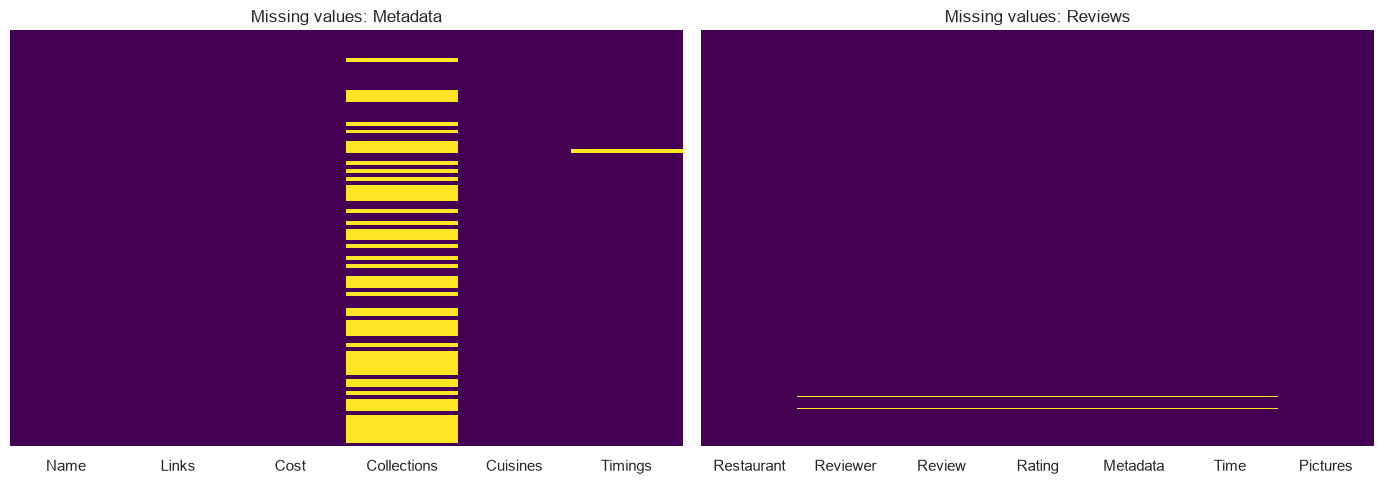

In [9]:
# Visualizing the missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(meta.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[0])
axes[0].set_title("Missing values: Metadata")

sns.heatmap(reviews.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Missing values: Reviews")

plt.tight_layout()
plt.show()

### What did you know about your dataset?

We have two datasets about restaurants in Hyderabad listed on Zomato.

**1. Restaurant metadata (105 rows x 6 columns):** one row per restaurant with its name, Zomato link, estimated cost per person, the Zomato collections it belongs to, its cuisines and its opening hours.
- No duplicate rows.
- `Collections` is missing for 54 restaurants (more than half), so it is not reliable as a feature.
- `Timings` has 1 missing value.
- Every column is stored as text, including `Cost`, which contains commas (e.g. "1,300") and must be converted to a number.

**2. Reviews (10,000 rows x 7 columns):** one row per customer review with the restaurant, reviewer, review text, rating, reviewer profile (number of reviews and followers), date and number of pictures.
- 38 rows are completely empty (no reviewer, rating, metadata or time). They sit next to each other in the file and are also the source of the 36 duplicate rows. They will be removed.
- 45 reviews have no text, so 7 rows have a rating without a written review.
- `Rating` is stored as text and needs to be converted to a number.
- `Metadata` combines two pieces of information in one string ("3 Reviews , 2 Followers") that need to be separated.

**Link between the two:** the restaurant name. 100 of the 105 restaurants have reviews (exactly 100 each), and 5 restaurants have no reviews at all.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print("Metadata columns:", meta.columns.tolist())
print("Reviews columns :", reviews.columns.tolist())

Metadata columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews columns : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [11]:
# Dataset Describe
display(meta.describe(include="all"))
display(reviews.describe(include="all"))

,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
count,10000,9962,9955,9962,9962,9962,10000.000000
unique,100,7446,9364,10,2477,9782,NaN
top,Beyond Flavours,Ankita,good,5,1 Review,5/5/2019 22:39,NaN
freq,100,13,237,3832,919,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.748600
std,NaN,NaN,NaN,NaN,NaN,NaN,2.570381
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


### Variables Description

**Restaurant metadata**
- **Name**: name of the restaurant (unique key, links to `Restaurant` in the reviews).
- **Links**: URL of the restaurant's Zomato page.
- **Cost**: estimated cost of dining per person, in Indian rupees (₹).
- **Collections**: Zomato themed lists the restaurant appears in (e.g. "Great Buffets", "Hyderabad's Hottest").
- **Cuisines**: types of food served, as a comma-separated list.
- **Timings**: opening hours, written as free text.

**Reviews**
- **Restaurant**: name of the restaurant being reviewed.
- **Reviewer**: name of the customer who wrote the review.
- **Review**: the review text written by the customer.
- **Rating**: score given by the customer, from 1 to 5.
- **Metadata**: reviewer profile, combining their total number of reviews and followers.
- **Time**: date and time the review was posted.
- **Pictures**: number of pictures attached to the review.

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
print("Unique values in metadata:\n", meta.nunique(), "\n")
print("Unique values in reviews:\n", reviews.nunique(), "\n")

# Rating deserves a closer look: it should only contain 1 to 5
print("Rating values:\n", reviews["Rating"].value_counts(dropna=False))

Unique values in metadata:
 Name           105
Links          105
Cost            29
Collections     42
Cuisines        92
Timings         77
dtype: int64 

Unique values in reviews:
 Restaurant     100
Reviewer      7446
Review        9364
Rating          10
Metadata      2477
Time          9782
Pictures        36
dtype: int64 

Rating values:
 Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
NaN       38
2.5       19
1.5        9
Like       1
Name: count, dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.

# ---------- 1. Restaurant metadata ----------
meta_clean = meta.copy()   # work on a copy so the raw data stays untouched

# Cost: "1,300" (text) -> 1300 (number)
meta_clean["Cost"] = meta_clean["Cost"].str.replace(",", "").astype(int)

# Cuisines: "Chinese, North Indian" -> ["Chinese", "North Indian"]
meta_clean["Cuisines_List"] = meta_clean["Cuisines"].str.split(",").apply(lambda x: [c.strip() for c in x])
meta_clean["Num_Cuisines"] = meta_clean["Cuisines_List"].str.len()

# ---------- 2. Reviews ----------
rev = reviews.copy()

# Remove the 38 completely empty rows, then any remaining duplicates
rev = rev.dropna(subset=["Reviewer", "Rating", "Metadata", "Time"], how="all")
rev = rev.drop_duplicates()

# Rating: text -> number. "Like" can't be converted, so it becomes NaN and I drop that single row
rev["Rating"] = pd.to_numeric(rev["Rating"], errors="coerce")
rev = rev.dropna(subset=["Rating"])

# The 7 reviews with a rating but no text: keep the rating, use an empty string for the text
rev["Review"] = rev["Review"].fillna("")

# Metadata: "3 Reviews , 2 Followers" -> two number columns
# No "Followers" part in the text means the reviewer has 0 followers
rev["Reviewer_Reviews"] = rev["Metadata"].str.extract(r"(\d+)\s*Review").astype(float).fillna(0).astype(int)
rev["Reviewer_Followers"] = rev["Metadata"].str.extract(r"(\d+)\s*Follower").astype(float).fillna(0).astype(int)

# Time: text -> real date, then extract useful parts
rev["Time"] = pd.to_datetime(rev["Time"], format="%m/%d/%Y %H:%M")
rev["Year"] = rev["Time"].dt.year
rev["Month"] = rev["Time"].dt.month
rev["Hour"] = rev["Time"].dt.hour

# Review length in words
rev["Review_Length"] = rev["Review"].str.split().str.len()

# ---------- 3. One table per restaurant (for clustering) ----------
rest_stats = rev.groupby("Restaurant").agg(
    Avg_Rating=("Rating", "mean"),
    Num_Reviews=("Rating", "count"),
    Avg_Pictures=("Pictures", "mean"),
    Avg_Review_Length=("Review_Length", "mean"),
).reset_index()

df = meta_clean.merge(rest_stats, left_on="Name", right_on="Restaurant", how="left").drop(columns="Restaurant")

# ---------- 4. Check the result ----------
print("Reviews :", reviews.shape, "->", rev.shape)
print("Restaurants table:", df.shape)
display(df.head())
display(rev.head())

Reviews : (10000, 7) -> (9961, 13)
Restaurants table: (105, 12)


,Name,Links,Cost,Collections,Cuisines,Timings,Cuisines_List,Num_Cuisines,Avg_Rating,Num_Reviews,Avg_Pictures,Avg_Review_Length
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buff...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)","[Chinese, Continental, Kebab, European, South Indian, North Indian]",6,4.28,100.0,0.39,47.92
1,Paradise,https://www.zomato.com/hyderabad/paradise-gachibowli,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,"[Biryani, North Indian, Chinese]",3,4.70,100.0,0.02,29.90
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gachibowli,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM","[Asian, Mediterranean, North Indian, Desserts]",4,4.66,100.0,0.55,47.68
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Beverages",12 Noon to 2 AM,"[Biryani, North Indian, Chinese, Seafood, Beverages]",5,3.21,100.0,0.30,45.50
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli,1200,"Best Bars & Pubs, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Go...","Asian, Continental, North Indian, Chinese, Mediterranean","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)","[Asian, Continental, North Indian, Chinese, Mediterranean]",5,4.34,100.0,0.44,48.80


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Reviewer_Reviews,Reviewer_Followers,Year,Month,Hour,Review_Length
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . had Saturday lunch , which was ...",5.0,"1 Review , 2 Followers",2019-05-25 15:54:00,0,1,2,2019,5,15,41
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. Service is very prompt. Food is...,5.0,"3 Reviews , 2 Followers",2019-05-25 14:20:00,0,3,2,2019,5,14,27
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx for the service by Pradeep and ...,5.0,"2 Reviews , 3 Followers",2019-05-24 22:54:00,0,2,3,2019,5,22,31
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only because of their behavior and sinc...,5.0,"1 Review , 1 Follower",2019-05-24 22:11:00,0,1,1,2019,5,22,28
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are g...,5.0,"3 Reviews , 2 Followers",2019-05-24 21:37:00,0,3,2,2019,5,21,27


### What all manipulations have you done and insights you found?

Here's what I did to get the data ready:

**On the restaurant metadata**
- I converted `Cost` from text to a number by removing the commas ("1,300" became 1300).
- I split `Cuisines` into a proper list and counted how many cuisines each restaurant serves (`Num_Cuisines`).

**On the reviews**
- I removed the 38 completely empty rows. That also got rid of the 36 duplicates, since they were the same empty rows.
- I converted `Rating` to a number. One rating was the word "Like" instead of a score, so I dropped that row since I couldn't know what score the person meant.
- For the 7 reviews with a rating but no text, I kept the rating and just left the text empty.
- I split `Metadata` into two number columns: how many reviews the reviewer has written and how many followers they have. When there was no follower count, I put 0, because that's what it means.
- I converted `Time` into a real date and pulled out the year, month and hour.
- I added `Review_Length`, the number of words in each review.

**Restaurant-level table**
For the clustering, I need one row per restaurant, so I summarized each restaurant's reviews (average rating, number of reviews, average pictures, average review length) and merged that with the metadata. That gives me a table of 105 restaurants and 12 columns.

**What I noticed**
- I went from 10,000 to 9,961 reviews, so I only lost 39 rows. That's less than 0.4% of the data.
- The 5 restaurants without reviews now have no average rating. I'll handle that in the missing values part.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

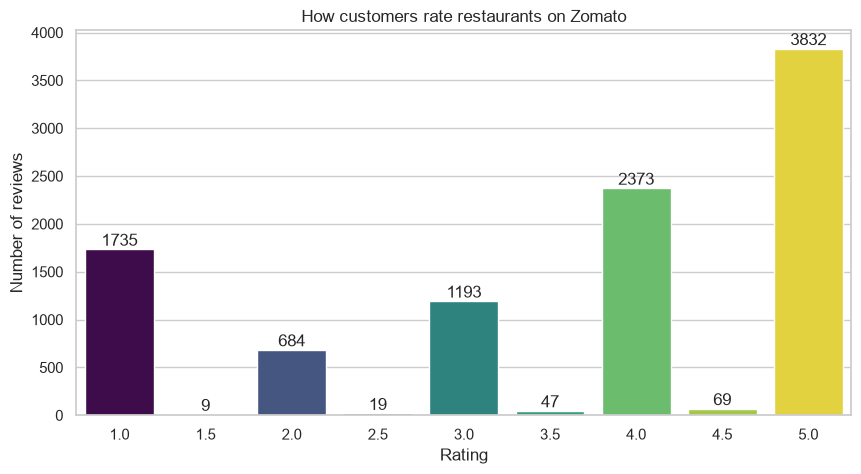

In [14]:
# Chart - 1 visualization code
plt.figure(figsize=(10, 5))
ax = sns.countplot(x="Rating", data=rev, hue="Rating", palette="viridis", legend=False)
for container in ax.containers:           # one container per bar, so label each one
    ax.bar_label(container)
plt.title("How customers rate restaurants on Zomato")
plt.xlabel("Rating")
plt.ylabel("Number of reviews")
plt.show()

##### 1. Why did you pick the specific chart?

I used a count plot because the rating only has a few possible values (1 to 5, with some half stars), and I wanted to see how many reviews fall on each one. Bars make it easy to compare them at a glance.

##### 2. What is/are the insight(s) found from the chart?

- 5 is by far the most common rating, with around 3,800 reviews, then 4 with around 2,400.
- What surprised me is that 1 star comes third, with 1,735 reviews. That's more than 3 stars and way more than 2 stars.
- So people mostly leave a rating when they really loved it or really hated it. The middle ratings are less common.
- Half stars (1.5, 2.5, 3.5, 4.5) almost don't exist, so most people just pick a whole number.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Since most reviews are 4 or 5, customers are generally happy, which is good for Zomato's image. But the high number of 1-star reviews is a warning sign. Those are customers who had a really bad experience, probably won't come back, and also push other people away. Zomato could flag restaurants that get a lot of 1-star reviews and warn them early, before it hurts their reputation.

For my model, it also tells me the classes aren't balanced: there are a lot more positive reviews than negative ones. I'll need to keep that in mind for the sentiment analysis.

#### Chart - 2

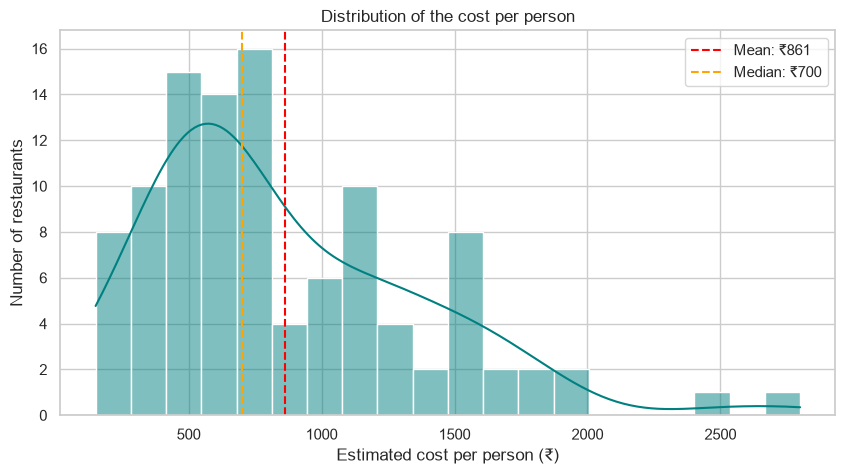

In [15]:
# Chart - 2 visualization code
plt.figure(figsize=(10, 5))
sns.histplot(df["Cost"], bins=20, kde=True, color="teal")
plt.axvline(df["Cost"].mean(), color="red", linestyle="--", label=f"Mean: ₹{df['Cost'].mean():.0f}")
plt.axvline(df["Cost"].median(), color="orange", linestyle="--", label=f"Median: ₹{df['Cost'].median():.0f}")
plt.title("Distribution of the cost per person")
plt.xlabel("Estimated cost per person (₹)")
plt.ylabel("Number of restaurants")
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?

Cost is a continuous number, so a histogram is the best way to see how it's spread out. I added the KDE curve to see the overall shape, plus the mean and the median to compare them.

##### 2. What is/are the insight(s) found from the chart?

- Most restaurants cost between ₹300 and ₹850 per person. That's where the tallest bars are.
- The median is ₹700 but the mean is ₹861. The mean is higher because a few expensive restaurants pull it up.
- The distribution is right-skewed: it has a long tail on the right.
- There are small bumps around ₹1,200 and ₹1,500, which look like a second group of more upscale restaurants.
- After ₹2,000 there's almost nothing, except two restaurants at around ₹2,500 and ₹2,800. Those are the premium hotel restaurants, and they're outliers compared to the rest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most restaurants are in the affordable to mid-range budget, so that's where most of Zomato's customers spend. Zomato can focus offers and promotions on that price range, where the volume is.

There's no negative growth here, but I see a gap: there are very few premium restaurants. That could be an opportunity for Zomato to bring in more high-end partners. For my model, the skew and the two outliers mean I'll need to scale `Cost` before clustering, so the expensive restaurants don't dominate the groups.

#### Chart - 3

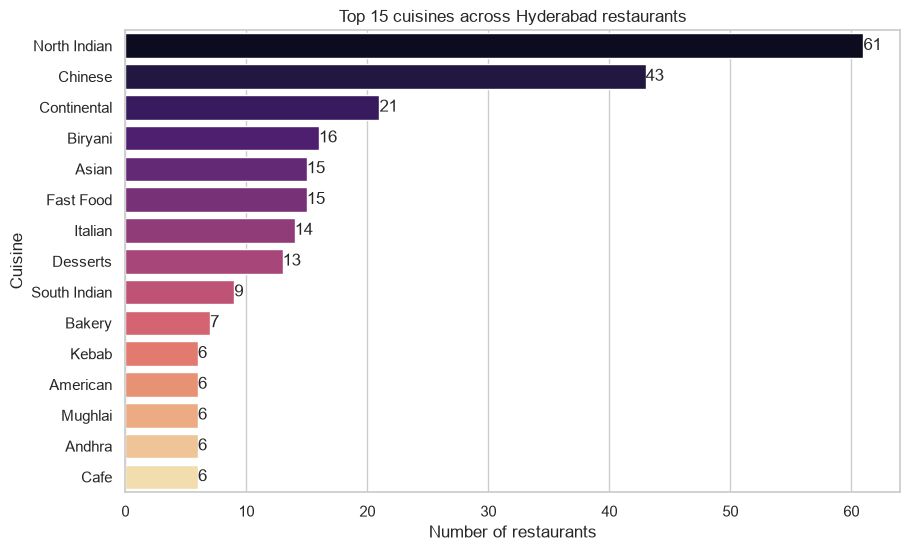

In [16]:
# Chart - 3 visualization code
cuisine_counts = df["Cuisines_List"].explode().value_counts().head(15)   # explode: one row per cuisine

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index,
                 hue=cuisine_counts.index, palette="magma", legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Top 15 cuisines across Hyderabad restaurants")
plt.xlabel("Number of restaurants")
plt.ylabel("Cuisine")
plt.show()

##### 1. Why did you pick the specific chart?

I used a horizontal bar chart because I'm comparing categories (cuisines) and some names are long. Horizontal bars keep the labels readable, and sorting them from top to bottom makes the ranking obvious straight away.

##### 2. What is/are the insight(s) found from the chart?

- North Indian is everywhere: 61 of the 105 restaurants serve it, so more than half.
- Chinese comes second with 43, way ahead of the rest.
- After that it drops a lot: Continental has 21, then Biryani 16, Asian and Fast Food 15 each.
- The local cuisines are lower than I expected. South Indian is only at 9 and Andhra at 6, even though Hyderabad is in South India.
- Most restaurants serve several cuisines, so a lot of them are "a bit of everything" places rather than specialists.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. North Indian and Chinese are clearly what restaurants in Hyderabad bet on, so Zomato should make sure these are always well covered and easy to find in the app.

On the negative side, these two cuisines are saturated. A new North Indian restaurant will face a lot of competition and will struggle to stand out. Cuisines like South Indian, Andhra or Mughlai have far fewer options, so there's room for new restaurants there. That's useful for Zomato when it advises new restaurant partners on where to position themselves.

#### Chart - 4

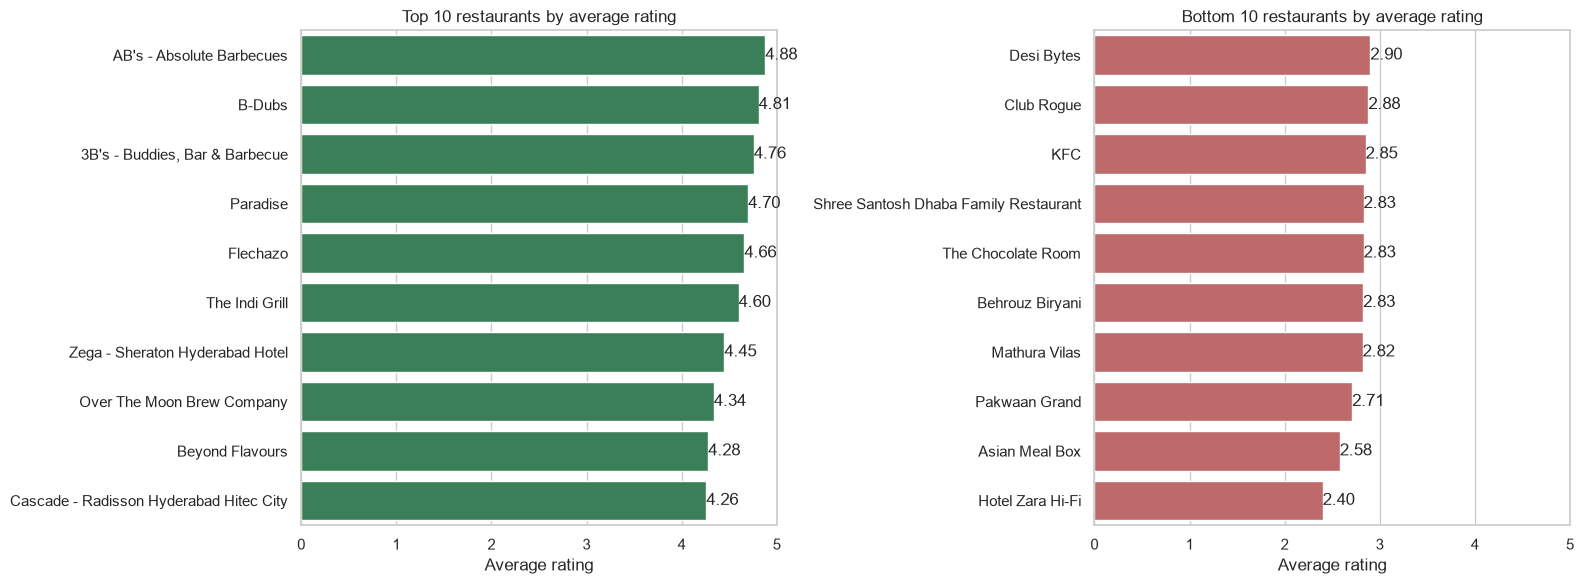

In [17]:
# Chart - 4 visualization code
rated = df.dropna(subset=["Avg_Rating"]).sort_values("Avg_Rating", ascending=False)   # skip the 5 restaurants with no reviews
top10 = rated.head(10)
bottom10 = rated.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x="Avg_Rating", y="Name", data=top10, color="seagreen", ax=axes[0])
axes[0].set_title("Top 10 restaurants by average rating")
axes[0].set_xlim(0, 5)

sns.barplot(x="Avg_Rating", y="Name", data=bottom10, color="indianred", ax=axes[1])
axes[1].set_title("Bottom 10 restaurants by average rating")
axes[1].set_xlim(0, 5)

for ax in axes:
    ax.bar_label(ax.containers[0], fmt="%.2f")   # one colour per chart, so one container is enough here
    ax.set_xlabel("Average rating")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I put two bar charts side by side so I could compare the best and the worst restaurants directly. Both use the same scale from 0 to 5, so the gap between the two groups is easy to see. Horizontal bars also keep the restaurant names readable.

##### 2. What is/are the insight(s) found from the chart?

- The best restaurant is AB's - Absolute Barbecues with 4.88, and the worst is Hotel Zara Hi-Fi with 2.40. That's a gap of almost 2.5 points.
- The top 10 are mostly dine-in experiences: barbecue and buffet places (AB's, 3B's), pubs (B-Dubs, Over The Moon Brew Company) and hotel restaurants (Zega at the Sheraton, Cascade at the Radisson).
- The bottom 10 has a lot of quick food and delivery brands, like KFC, Behrouz Biryani and Asian Meal Box.
- Even big famous names like KFC end up in the bottom 10, so being a known brand doesn't guarantee good reviews.
- All the bottom 10 are under 3, so customers are clearly not happy with them.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Zomato can promote the top restaurants in its app and in collections like "Top-Rated", since customers clearly love them. It can also study what they do well (the full experience, the service, the atmosphere) and share that with other restaurants.

The bottom 10 is the negative side. Restaurants rated under 3 drive customers away, and when customers have a bad order through Zomato, some of them blame the app too. Zomato should reach out to these restaurants, read their negative reviews to find the main problems (late delivery, cold food, bad service) and help them improve, or show them lower in the search results until they do.

#### Chart - 5

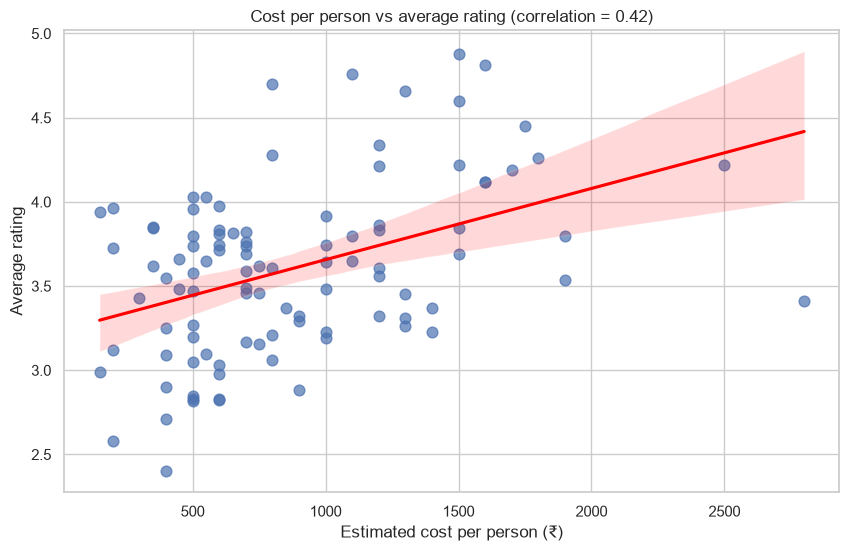

In [18]:
# Chart - 5 visualization code
plt.figure(figsize=(10, 6))
sns.regplot(x="Cost", y="Avg_Rating", data=df,
            scatter_kws={"s": 60, "alpha": 0.7}, line_kws={"color": "red"})
corr = df["Cost"].corr(df["Avg_Rating"])
plt.title(f"Cost per person vs average rating (correlation = {corr:.2f})")
plt.xlabel("Estimated cost per person (₹)")
plt.ylabel("Average rating")
plt.show()

##### 1. Why did you pick the specific chart?

I wanted to check if two numbers are linked (cost and rating), so a scatter plot was the natural choice: each dot is a restaurant. I used a regression plot to add the trend line, and I put the correlation in the title to measure how strong the link is.

##### 2. What is/are the insight(s) found from the chart?

- The correlation is 0.42, so there's a moderate positive link: the more expensive the restaurant, the better the rating tends to be.
- But it's not a rule. Cheap restaurants (under ₹1,000) are all over the place, from 2.4 up to 4.7. So you can find great places on a small budget, and also very bad ones.
- All the restaurants rated under 3 cost less than ₹1,000. Once you go above ₹1,000, almost no restaurant drops under 3.2.
- The most expensive restaurant (₹2,800) only has a rating of around 3.4. So paying the most doesn't guarantee the best experience.
- The red shaded area gets wider on the right because there are very few expensive restaurants, so the trend is less certain there.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The higher price range is the "safe" zone: customers who pay more almost always get a decent experience. Zomato can use that to reassure customers when it promotes premium restaurants.

The negative side is in the cheap range. That's where most restaurants are, and also where all the worst ratings are. Since budget restaurants bring a lot of the order volume, bad experiences there can hurt Zomato a lot. Zomato should highlight the good budget restaurants (the ones rated above 4 for under ₹1,000), because that's the best value for customers, and keep a closer eye on quality in that range.

#### Chart - 6

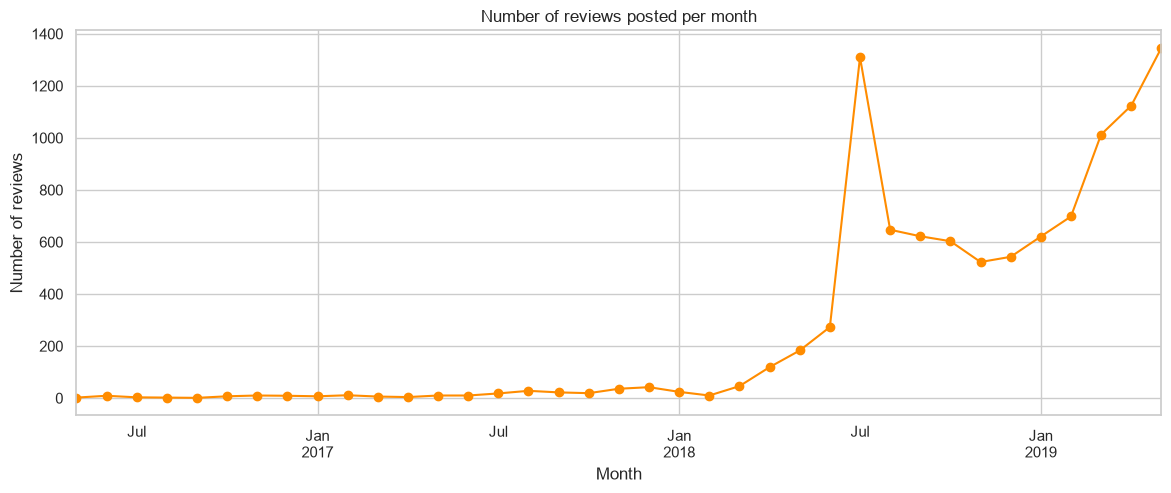

In [19]:
# Chart - 6 visualization code
monthly = rev.set_index("Time").resample("ME").size()   # count the reviews posted each month

plt.figure(figsize=(14, 5))
monthly.plot(marker="o", color="darkorange")
plt.title("Number of reviews posted per month")
plt.xlabel("Month")
plt.ylabel("Number of reviews")
plt.show()

##### 1. Why did you pick the specific chart?

I wanted to see how the reviews are spread over time, and a line chart is the best way to show a trend month by month. The markers make each month easy to spot.

##### 2. What is/are the insight(s) found from the chart?

- Almost nothing happens before 2018. There are only a handful of reviews per month in 2016 and 2017.
- Activity starts growing in spring 2018, then there's a huge spike in July 2018 with around 1,300 reviews.
- After that it drops back to around 500 to 650 per month, then climbs again from January 2019 up to around 1,350 in May 2019.
- The data stops on 25 May 2019, so May isn't even a full month, and it's still the highest one.

But I need to be careful here. Each restaurant has exactly 100 reviews, so the dataset only kept the latest 100 reviews of each restaurant. For a busy restaurant, 100 reviews cover just a few weeks, so they all land in 2019. For a quieter one, they go back to 2017 or even 2016. So this chart mostly shows how recent the reviews are, not the real growth of Zomato. The July 2018 spike could be a few restaurants that opened or joined Zomato around then and got a lot of reviews at once.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, but mostly for how I use the data. Knowing that the dataset is capped at 100 reviews per restaurant stops me from making a wrong conclusion like "Zomato tripled in 2019". It also means the reviews mostly reflect how the restaurants were doing in 2018 and 2019, which is good, because recent reviews matter more for customers today.

For Zomato, the spikes show that review activity can jump fast around certain periods, like openings or events. Those are the moments to have staff ready to answer reviews quickly. The negative side is that some restaurants rely on reviews that are 2 or 3 years old, which might not reflect their current quality anymore. Zomato could push customers to review those restaurants more, so their rating stays up to date.

#### Chart - 7

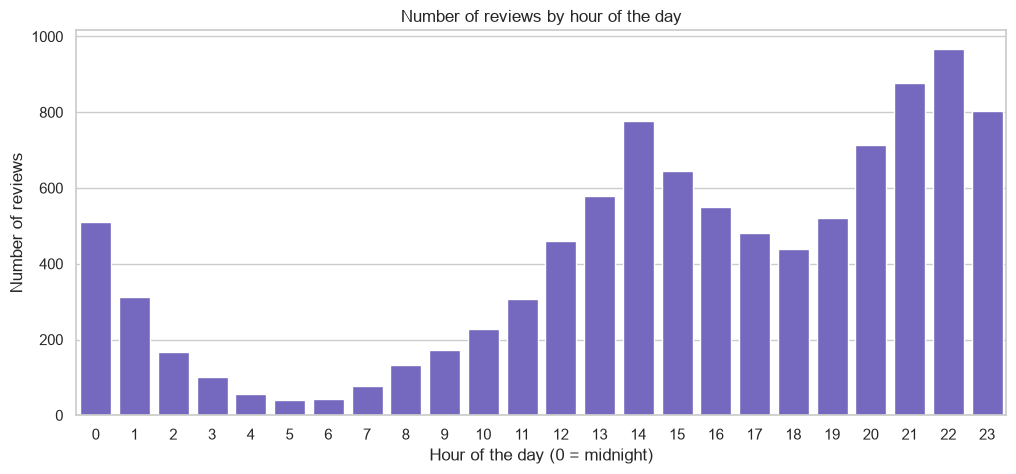

In [20]:
# Chart - 7 visualization code
hourly = rev["Hour"].value_counts().sort_index()   # number of reviews for each hour of the day (0 to 23)

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=hourly.index, y=hourly.values, color="slateblue")
plt.title("Number of reviews by hour of the day")
plt.xlabel("Hour of the day (0 = midnight)")
plt.ylabel("Number of reviews")
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart because the hours of the day are fixed categories from 0 to 23, and I wanted to compare how many reviews are posted at each hour. Keeping them in order shows the daily rhythm, like a timeline of a full day.

##### 2. What is/are the insight(s) found from the chart?

- There are two clear peaks that match meal times. The first is at 14h (around 780 reviews), right after lunch. The second and biggest is at 22h (around 960 reviews), after dinner.
- The evening is the busiest part of the day overall: from 20h to 23h there are always more than 700 reviews per hour.
- There's a dip between 17h and 18h, the gap between lunch and dinner.
- Activity is still high at midnight (around 500) and only really dies between 3h and 7h in the morning, when people are asleep.
- So people usually write their review right after they eat, while the experience is still fresh.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Since people review right after their meal, Zomato can send the "rate your order" notification at these moments, around 14h and 22h, when customers are most likely to answer. More reviews means more reliable ratings for everyone.

It also helps with planning. The evening peak is when customers are most active, so it's when Zomato should have the most support staff available to handle complaints, and when restaurants should be most careful with quality. If a restaurant messes up during dinner rush, that's exactly when the bad reviews will come in. I don't see any negative growth here, just the risk of not being ready during the peaks.

#### Chart - 8

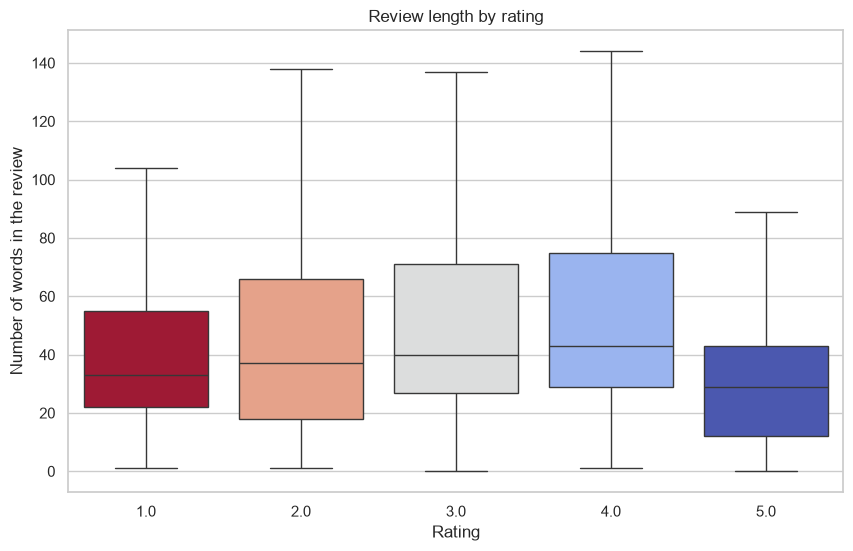

Median number of words per rating:
Rating
1.0    33.0
2.0    37.0
3.0    40.0
4.0    43.0
5.0    29.0
Name: Review_Length, dtype: float64


In [21]:
# Chart - 8 visualization code
whole = rev[rev["Rating"].isin([1, 2, 3, 4, 5])]   # keep whole ratings only, the half stars are too rare to compare

plt.figure(figsize=(10, 6))
sns.boxplot(x="Rating", y="Review_Length", data=whole, hue="Rating",
            palette="coolwarm_r", legend=False, showfliers=False)
plt.title("Review length by rating")
plt.xlabel("Rating")
plt.ylabel("Number of words in the review")
plt.show()

print("Median number of words per rating:")
print(whole.groupby("Rating")["Review_Length"].median())

##### 1. Why did you pick the specific chart?

I used a box plot because I wanted to compare the spread of review lengths across the ratings, not just one average. The box shows where most reviews sit and the line in the middle is the median, which isn't affected by the few very long reviews. I hid the extreme outliers so the boxes stay readable.

##### 2. What is/are the insight(s) found from the chart?

- 5-star reviews are the shortest: the median is only 29 words. Happy customers just say something like "great food, great service" and move on.
- The longest reviews are the 4-star ones (median 43 words), then 3 stars (40). These customers liked it but have something to add, so they explain what was good and what could be better.
- I expected the 1-star reviews to be the longest, but they're not. Their median is 33 words, so angry customers say what went wrong but don't write essays.
- The 2, 3 and 4-star boxes are the tallest, so the length of those reviews varies a lot. The 5-star box is the most compact.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The 3 and 4-star reviews are the most detailed, so they're the most useful feedback for restaurants. They come from customers who were almost satisfied and explain exactly what was missing. Zomato could highlight these reviews to restaurant owners, because fixing those small issues is the easiest way to turn a 4 into a 5.

There's a small negative side: 5-star reviews are short and don't say much, so they don't really help other customers choose. Zomato could encourage happy customers to write a bit more, for example by asking "what did you like the most?". For my sentiment model, it also means some positive reviews have very little text, so the model will have fewer words to learn from.

#### Chart - 9

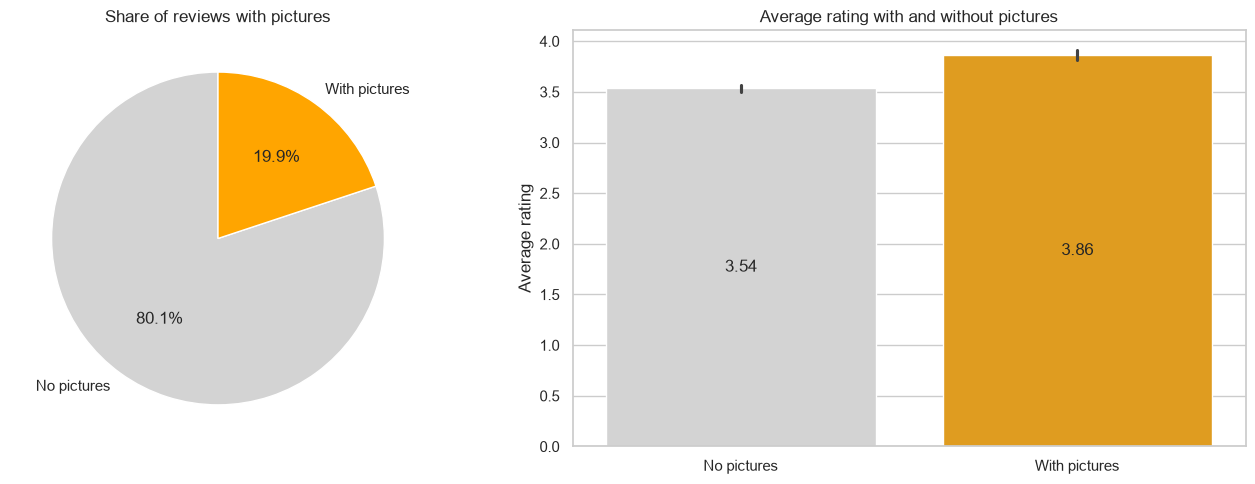

In [22]:
# Chart - 9 visualization code
rev["Has_Pictures"] = np.where(rev["Pictures"] > 0, "With pictures", "No pictures")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: how many reviews have pictures
counts = rev["Has_Pictures"].value_counts()
axes[0].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["lightgray", "orange"], startangle=90)
axes[0].set_title("Share of reviews with pictures")

# Right: average rating in each group
sns.barplot(x="Has_Pictures", y="Rating", data=rev, hue="Has_Pictures",
            palette=["lightgray", "orange"], legend=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", label_type="center")
axes[1].set_title("Average rating with and without pictures")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average rating")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I combined two charts. The pie chart shows how common pictures are, since it's a simple part of a whole (with vs without). The bar chart compares the average rating of the two groups, and the black lines on top show the confidence interval, so I can see if the difference is real or just luck.

##### 2. What is/are the insight(s) found from the chart?

- Only about 1 review in 5 (19.9%) has pictures. Most people just write text.
- Reviews with pictures have a higher average rating: 3.86 vs 3.54 without pictures. That's a difference of about 0.3 points.
- The black lines on the two bars don't overlap, so the difference looks real and not just random. I'll confirm it with a statistical test in the hypothesis testing part.
- My guess is that people take pictures when they're happy and proud of what they're eating, while an unhappy customer usually just wants to complain.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Pictures come with better ratings, and they also make a restaurant page look more attractive to other customers. Zomato can encourage people to add pictures, for example with a small reward or badge, because that brings more positive content to the platform.

Restaurants also benefit: good-looking dishes get photographed, so presentation matters. On the negative side, 80% of reviews have no pictures, so most restaurant pages rely only on text. And a restaurant that gets almost no pictures might be a sign that the food isn't very appealing, which Zomato could use as an early warning.

#### Chart - 10

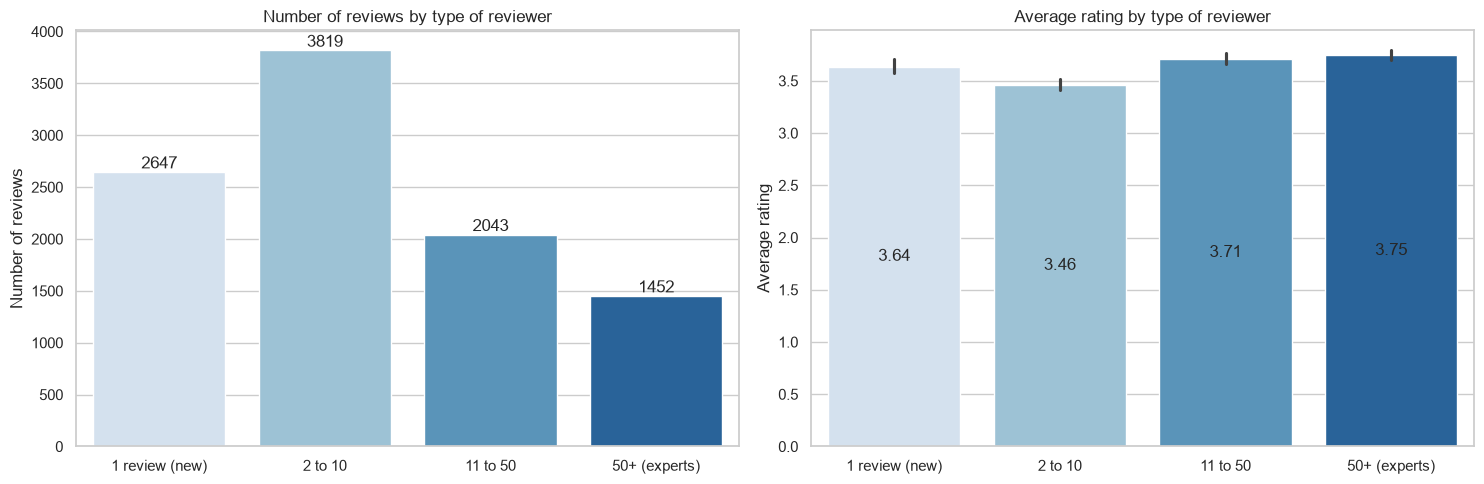

In [23]:
# Chart - 10 visualization code
# Group reviewers by how many reviews they have written in total on Zomato
bins = [0, 1, 10, 50, rev["Reviewer_Reviews"].max()]
labels = ["1 review (new)", "2 to 10", "11 to 50", "50+ (experts)"]
rev["Reviewer_Type"] = pd.cut(rev["Reviewer_Reviews"], bins=bins, labels=labels, include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: how many reviews come from each type of reviewer
# dodge=False keeps each bar full width and centered (Reviewer_Type is a category column)
sns.countplot(x="Reviewer_Type", data=rev, hue="Reviewer_Type", palette="Blues",
              legend=False, dodge=False, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container)
axes[0].set_title("Number of reviews by type of reviewer")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of reviews")

# Right: average rating given by each type
sns.barplot(x="Reviewer_Type", y="Rating", data=rev, hue="Reviewer_Type", palette="Blues",
            legend=False, dodge=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", label_type="center")
axes[1].set_title("Average rating by type of reviewer")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average rating")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I grouped reviewers into 4 levels based on how many reviews they've written, then used two bar charts: one to see who writes most of the reviews, and one to compare the average rating each group gives. The black lines show the confidence interval, so I can see if the differences are real.

##### 2. What is/are the insight(s) found from the chart?

- Most reviews come from casual users. 2,647 reviews are from people who only ever wrote 1 review, and 3,819 from people with 2 to 10. Together that's around 65% of all reviews.
- Experts (50+ reviews) only wrote 1,452 reviews, about 15%.
- I expected experts to be harsher, but it's the opposite: they give the highest average rating (3.75), followed by the 11 to 50 group (3.71).
- The lowest group is the 2 to 10 reviewers with 3.46, and its confidence line doesn't overlap with the experts, so that gap looks real.
- Still, the differences are small (0.3 points max). Overall, the reviewer's experience doesn't change the rating that much.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most of the content on Zomato comes from casual users, so Zomato needs to keep reviewing simple and quick for them. Making it complicated would cut a big part of the reviews.

The experts are a small group but they write a lot and tend to be positive. They're also the ones with followers, so their reviews reach more people. Zomato could reward them (badges, invites to restaurant events) to keep them active. The slightly lower ratings from the 2 to 10 group could be a sign that newer users are more easily disappointed, maybe because their expectations come from photos and ratings. If they have a bad first experience, they might stop using the app, so that's a group worth watching.

#### Chart - 11

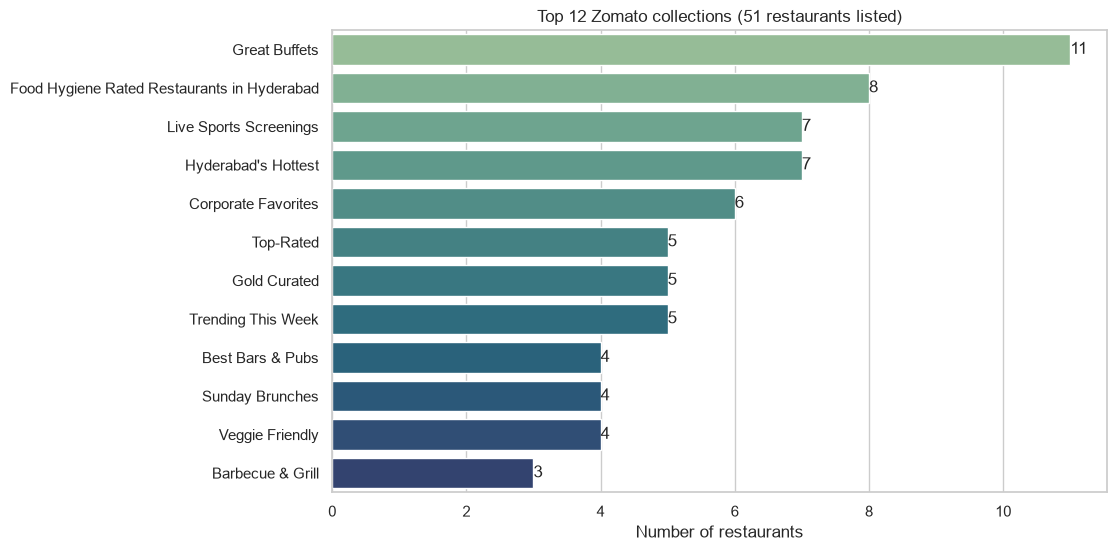

In [24]:
# Chart - 11 visualization code
coll = df.dropna(subset=["Collections"]).copy()          # only the 51 restaurants that are in a collection
coll["Collections_List"] = coll["Collections"].str.split(",").apply(lambda x: [c.strip() for c in x])
coll_counts = coll["Collections_List"].explode().value_counts().head(12)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=coll_counts.values, y=coll_counts.index,
                 hue=coll_counts.index, palette="crest", legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Top 12 Zomato collections (51 restaurants listed)")
plt.xlabel("Number of restaurants")
plt.ylabel("")
plt.show()

##### 1. Why did you pick the specific chart?

I used a horizontal bar chart again because I'm comparing categories with long names (the collection titles). Sorting them shows straight away which collections have the most restaurants.

##### 2. What is/are the insight(s) found from the chart?

- Great Buffets is the biggest collection with 11 restaurants, so buffets are a big thing in Hyderabad.
- Food Hygiene Rated comes second with 8, which shows that cleanliness matters to customers and to Zomato.
- After that, the collections are about experiences and occasions: Live Sports Screenings (7), Hyderabad's Hottest (7), Corporate Favorites (6), Sunday Brunches and Best Bars & Pubs (4 each).
- Most collections only have between 3 and 7 restaurants, so they're very selective.
- And the big one: only 51 of the 105 restaurants are in any collection at all. More than half get no extra visibility from them.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The collections show what customers look for besides the food itself: buffets, hygiene, watching sports, eating out with colleagues, brunch on Sunday. Restaurants can use this to see which experiences sell, and Zomato can create more collections around these themes.

The negative side is that 54 restaurants aren't in any collection, so they're harder to discover in the app. For a new or smaller restaurant, that's a real disadvantage compared to the ones that keep showing up in lists. Zomato could create more collections or rotate them more often, so more restaurants get a chance to be seen. For my model, it also confirms that Collections has too many missing values to be a reliable feature for clustering.

#### Chart - 12

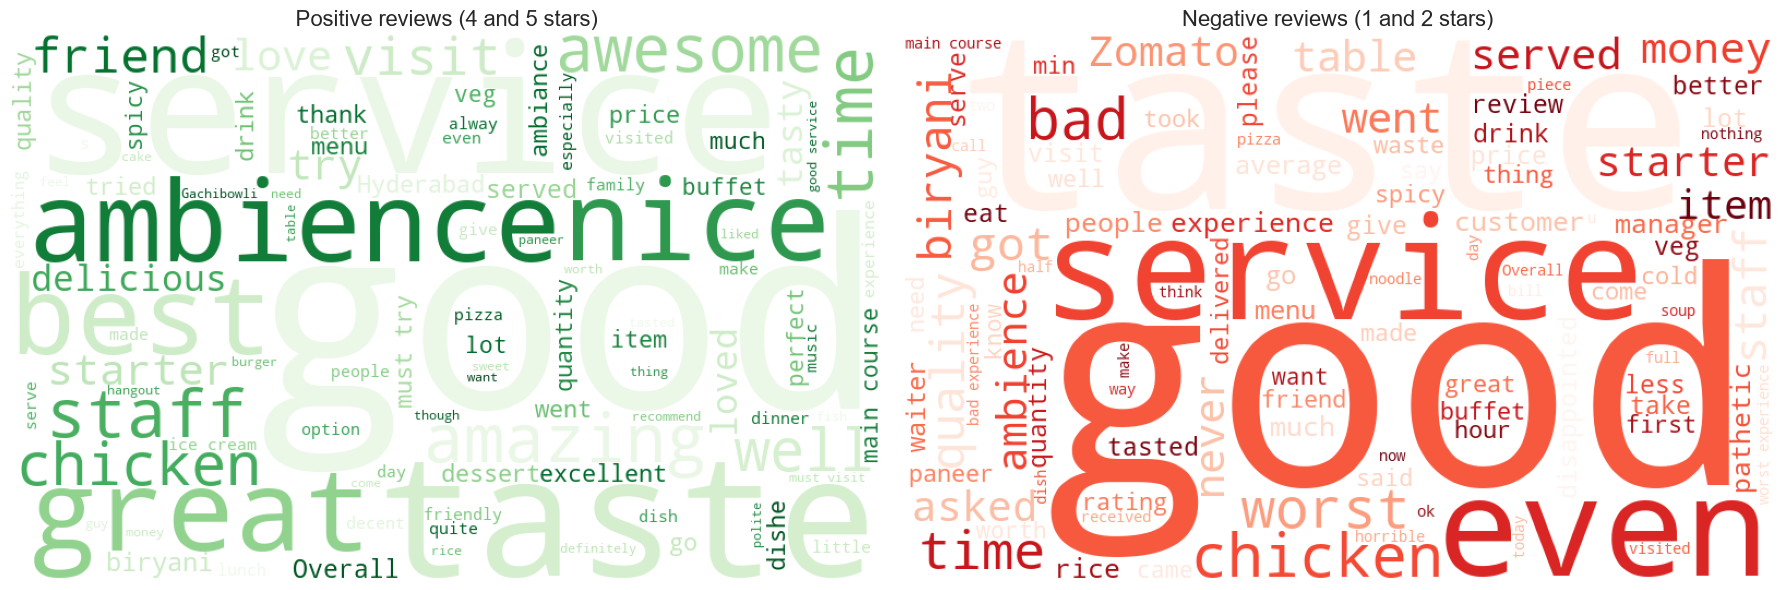

In [25]:
# Chart - 12 visualization code
from wordcloud import WordCloud, STOPWORDS

# Common words that appear everywhere and don't tell us anything
stop_words = set(STOPWORDS) | {"food", "place", "restaurant", "order", "ordered", "one", "also", "will", "really", "us"}

positive_text = " ".join(rev.loc[rev["Rating"] >= 4, "Review"])   # all 4 and 5-star reviews in one big text
negative_text = " ".join(rev.loc[rev["Rating"] <= 2, "Review"])   # all 1 and 2-star reviews

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

wc_pos = WordCloud(width=800, height=500, background_color="white", stopwords=stop_words,
                   colormap="Greens", max_words=100, random_state=42).generate(positive_text)
axes[0].imshow(wc_pos)
axes[0].set_title("Positive reviews (4 and 5 stars)", fontsize=16)
axes[0].axis("off")

wc_neg = WordCloud(width=800, height=500, background_color="white", stopwords=stop_words,
                   colormap="Reds", max_words=100, random_state=42).generate(negative_text)
axes[1].imshow(wc_neg)
axes[1].set_title("Negative reviews (1 and 2 stars)", fontsize=16)
axes[1].axis("off")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I used two word clouds side by side to compare what happy and unhappy customers write about. The bigger the word, the more often it shows up, so I can see the main topics of each group at a glance. I removed filler words and words like "food" or "place" that appear in every review, so the differences stand out more.

##### 2. What is/are the insight(s) found from the chart?

- In positive reviews, the main words are good, great, taste, service, ambience, nice, best, awesome, amazing, delicious and staff. Happy customers talk about the overall experience: the taste, the service and the atmosphere.
- Words like "friend", "visit" and "must try" show that happy customers recommend the place and want to come back.
- In negative reviews, the clear complaint words are bad, worst, pathetic, waste, money, cold, never and hour. So people complain about bad taste, bad value for money, cold food and long waiting times.
- Words like waiter, manager, asked, table and served show that a lot of complaints are about the service and the staff, not only the food.
- "Zomato" itself shows up in the negative reviews, so some unhappy customers blame the app too, probably for delivery problems.
- The most interesting part: "good" is the biggest word in the negative cloud. That's because people write "not good". The word cloud counts each word separately, so it loses the "not". That's a big lesson for my sentiment model: I need to keep words like "not" and "never" when I clean the text, otherwise the model will get the meaning wrong.
- "Taste", "service" and "chicken" are big on both sides, so these are the topics that make or break a review.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The positive cloud shows what customers value: taste, service and ambience. Restaurants can focus on these three things, since they're what makes people come back and recommend the place.

The negative cloud is like a list of the main problems to fix: slow service, rude or absent staff, cold food and feeling like the money was wasted. Zomato can share this with restaurant partners so they know exactly what customers hate. The negative growth risk is that some customers blame Zomato itself, so bad restaurant experiences, especially on delivery, can hurt Zomato's image. Fixing delivery times and following up on complaints quickly would protect both the restaurants and the app.

#### Chart - 13

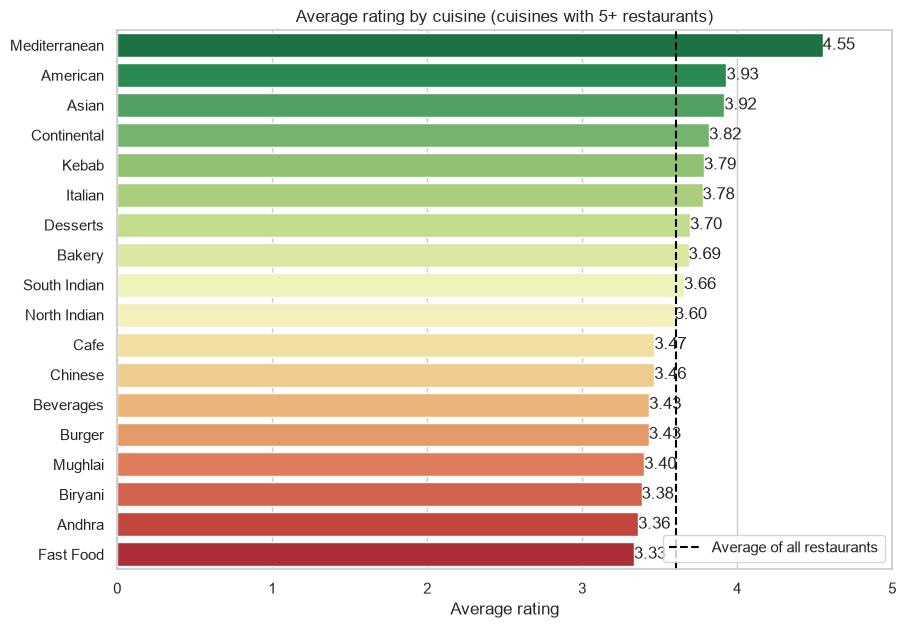

               Avg_Rating  Num_Restaurants
Cuisines_List                             
Mediterranean    4.552000                5
American         3.930671                6
Asian            3.917143               14
Continental      3.818459               21
Kebab            3.785833                6
Italian          3.776429               14
Desserts         3.695769               13
Bakery           3.686027                6
South Indian     3.656667                9
North Indian     3.597583               60
Cafe             3.465833                6
Chinese          3.465000               41
Beverages        3.432000                5
Burger           3.429805                5
Mughlai          3.400833                6
Biryani          3.383333               15
Andhra           3.360833                6
Fast Food        3.334156               13


In [26]:
# Chart - 13 visualization code
# One row per restaurant per cuisine, then average the rating for each cuisine
cuisine_rating = (df.dropna(subset=["Avg_Rating"])
                    .explode("Cuisines_List")
                    .groupby("Cuisines_List")
                    .agg(Avg_Rating=("Avg_Rating", "mean"), Num_Restaurants=("Name", "count")))

# Keep cuisines served by at least 5 restaurants, so one single restaurant can't decide the result
cuisine_rating = cuisine_rating[cuisine_rating["Num_Restaurants"] >= 5].sort_values("Avg_Rating", ascending=False)

plt.figure(figsize=(10, 7))
# RdYlGn_r = reversed palette, so the best cuisines (top) are green and the worst (bottom) are red
ax = sns.barplot(x=cuisine_rating["Avg_Rating"], y=cuisine_rating.index,
                 hue=cuisine_rating.index, palette="RdYlGn_r", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.axvline(df["Avg_Rating"].mean(), color="black", linestyle="--", label="Average of all restaurants")
plt.title("Average rating by cuisine (cuisines with 5+ restaurants)")
plt.xlabel("Average rating")
plt.ylabel("")
plt.xlim(0, 5)
plt.legend(loc="lower right")   # moved so it doesn't cover the top bar
plt.show()

print(cuisine_rating)

##### 1. Why did you pick the specific chart?

I used a sorted horizontal bar chart to rank the cuisines by their average rating, with a colour scale from green (best) to red (worst) and a dashed line for the overall average. That way I can see at a glance which cuisines do better or worse than the rest. I only kept cuisines served by at least 5 restaurants, so one single restaurant can't decide the result.

##### 2. What is/are the insight(s) found from the chart?

- Mediterranean is clearly on top with 4.55, way ahead of American in second place (3.93). But it's only based on 5 restaurants, so it's more about those specific places being great than the cuisine itself.
- Asian (3.92) and Continental (3.82) are the most solid results at the top, because they're based on more restaurants (14 and 21). So these cuisines are consistently well rated.
- The local and everyday cuisines are below the average: Mughlai (3.40), Biryani (3.38, 15 restaurants), Andhra (3.36), and Fast Food is last with 3.33 (13 restaurants).
- The two most common cuisines aren't the best rated. North Indian (60 restaurants) is right on the average at 3.60, and Chinese (41 restaurants) is below it at 3.46.
- So when a lot of restaurants serve the same thing, the quality varies a lot more and the average drops.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Cuisines like Mediterranean, American and Asian get great ratings but aren't served by many restaurants, so there's demand and not much competition. That's a real opportunity for new restaurants, and Zomato could push to bring more of them onto the platform.

The negative side is that the cuisines people order the most, like Chinese, Biryani and Fast Food, are among the lowest rated. Since they bring a lot of the volume, a lot of customers end up having average experiences, which can hurt how they see Zomato overall. Zomato could work with these restaurants on quality, and highlight the best biryani or fast food places so customers find the good ones more easily.

#### Chart - 14 - Correlation Heatmap

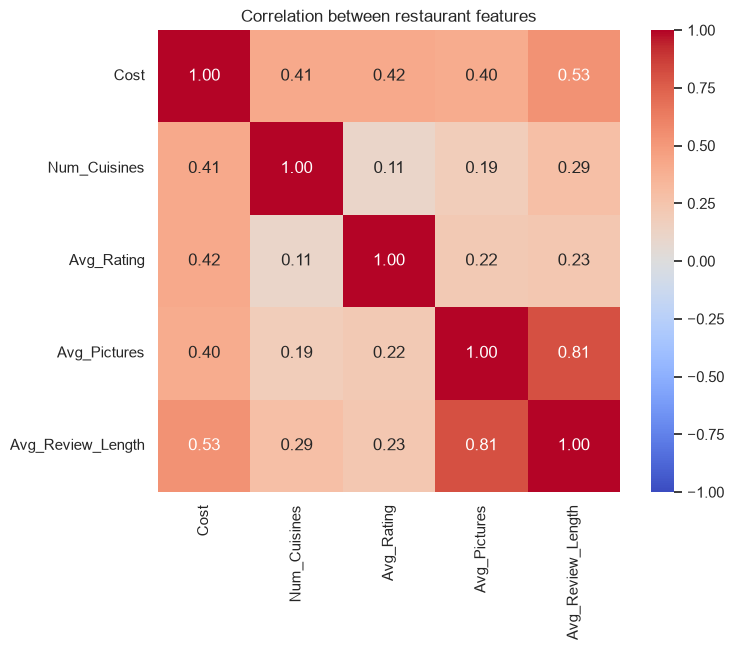

In [27]:
# Correlation Heatmap visualization code
num_cols = ["Cost", "Num_Cuisines", "Avg_Rating", "Avg_Pictures", "Avg_Review_Length"]
# Num_Reviews is left out: it's 100 for every restaurant, so it can't correlate with anything

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation between restaurant features")
plt.show()

##### 1. Why did you pick the specific chart?

I used a correlation heatmap because it shows the link between every pair of numerical features in one grid. The colours make the strong links stand out right away (red = they go up together, blue = they move in opposite directions), and the numbers give the exact value. It's the best way to spot features that repeat the same information before I build the clustering model.

##### 2. What is/are the insight(s) found from the chart?

- The strongest link by far is between Avg_Pictures and Avg_Review_Length (0.81). Restaurants where people post pictures are also the ones where they write longer reviews. Basically, both measure how engaged the customers are.
- Cost is moderately linked to everything: review length (0.53), rating (0.42), number of cuisines (0.41) and pictures (0.40). So the more expensive restaurants get better ratings, longer reviews, more pictures, and they serve more cuisines.
- The number of cuisines has almost no link with the rating (0.11). Serving more cuisines doesn't make customers happier.
- The rating is only weakly linked to pictures (0.22) and review length (0.23). At the restaurant level, Cost is the feature most related to the rating.
- There are no negative correlations at all: every feature moves in the same direction as the others.

For my clustering model, the 0.81 between pictures and review length means these two features say almost the same thing. If I keep both, I'd give that information double the weight, so I'll probably keep only one of them.

#### Chart - 15 - Pair Plot

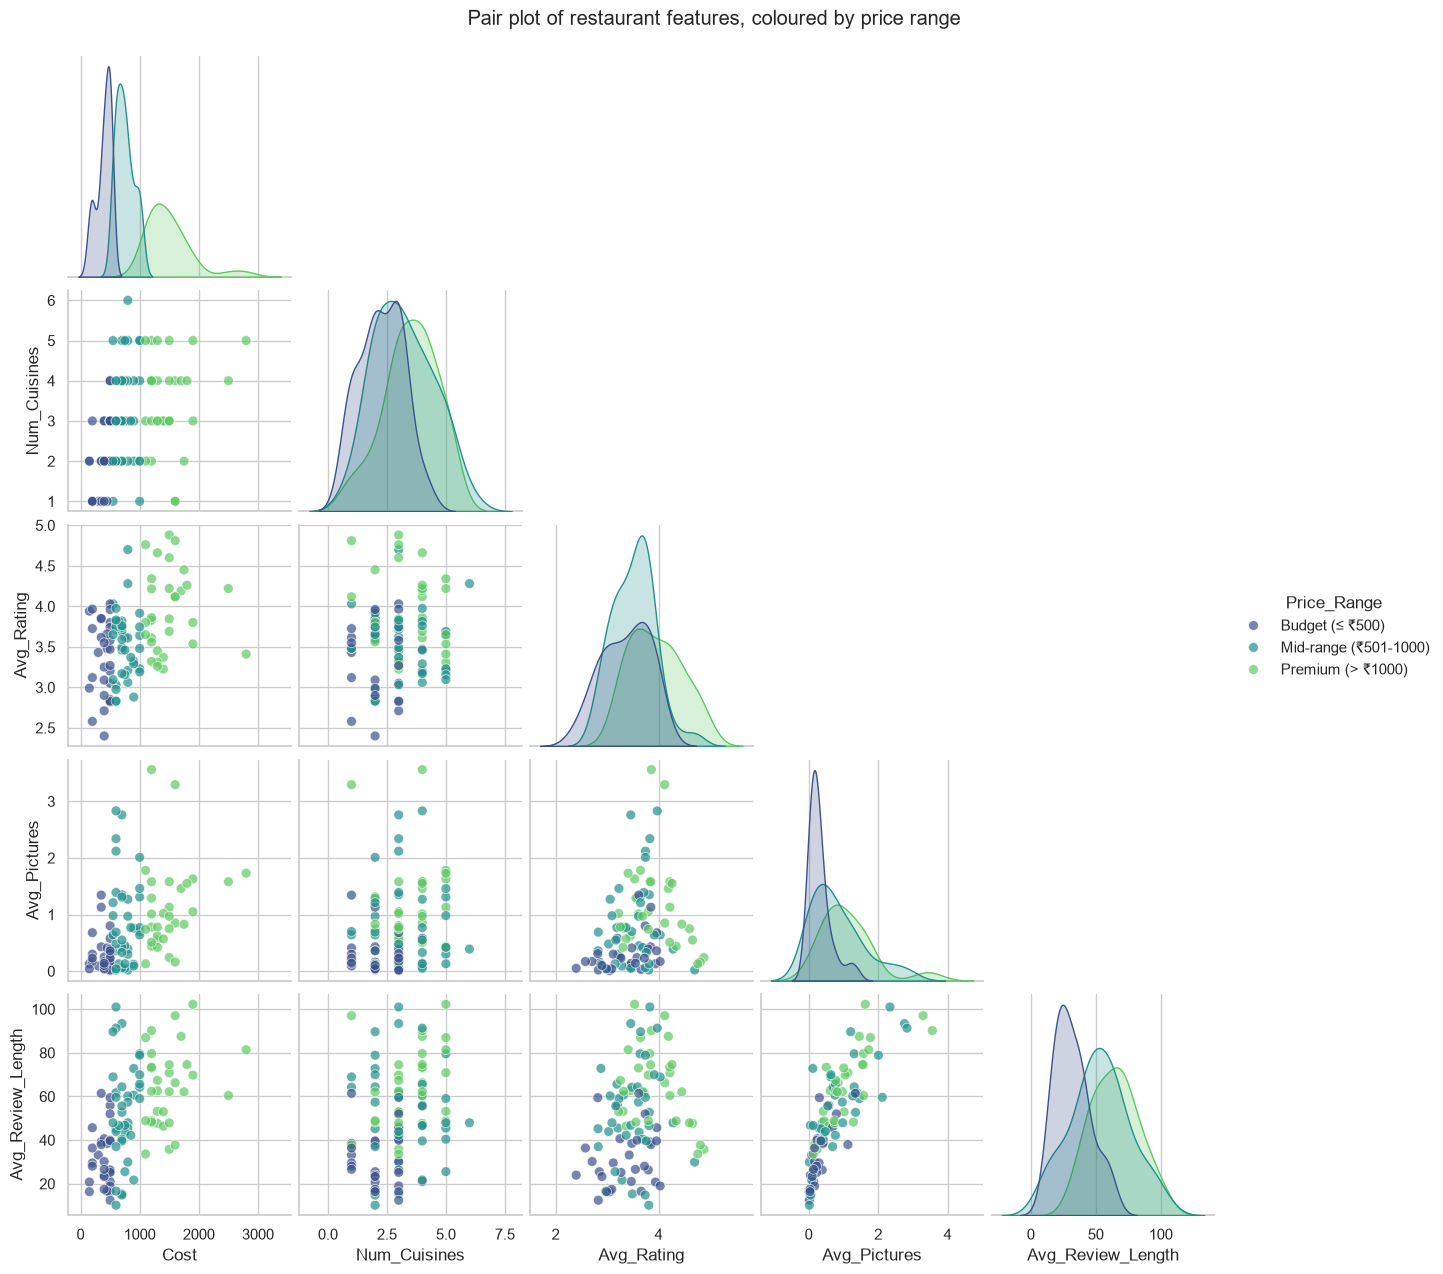

In [28]:
# Pair Plot visualization code
# Add a price range so the dots are coloured by budget level
df["Price_Range"] = pd.cut(df["Cost"], bins=[0, 500, 1000, df["Cost"].max()],
                           labels=["Budget (≤ ₹500)", "Mid-range (₹501-1000)", "Premium (> ₹1000)"])

pair_cols = ["Cost", "Num_Cuisines", "Avg_Rating", "Avg_Pictures", "Avg_Review_Length", "Price_Range"]

sns.pairplot(df[pair_cols].dropna(), hue="Price_Range", palette="viridis",
             diag_kind="kde", corner=True, plot_kws={"alpha": 0.7, "s": 50})
plt.suptitle("Pair plot of restaurant features, coloured by price range", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

I used a pair plot because it shows every numerical feature against every other one in a single figure, with the distribution of each feature on the diagonal. It's like the correlation heatmap, but with the real dots, so I can see the shape of the relationships and not just one number. I coloured the dots by price range to check if restaurants already form natural groups before I do the clustering.

##### 2. What is/are the insight(s) found from the chart?

- The three price ranges separate quite clearly on most charts. Budget restaurants (dark blue) sit at the bottom left almost everywhere: lower ratings, almost no pictures and short reviews.
- Premium restaurants (light green) are shifted to the right on the rating curve. Most of them are above 3.5, and they have the most pictures and the longest reviews.
- Mid-range restaurants are in the middle and overlap with both groups, so the border between groups isn't sharp.
- The clearest relationship is between Avg_Pictures and Avg_Review_Length: the dots form an almost straight line going up. That confirms the 0.81 correlation from the heatmap.
- Budget restaurants have the widest spread of ratings (from 2.4 to 4.0), while premium ones are more consistent.
- The number of cuisines doesn't separate the groups much. The dots form horizontal lines because it's a whole number (1 to 6), and all price ranges are mixed on each line.

This is promising for my clustering: price, engagement (pictures and review length) and rating seem to create natural groups of restaurants. But since the groups overlap, I don't expect the clusters to be perfectly separated.

#### Chart - 16 - Distribution of cost across cuisines

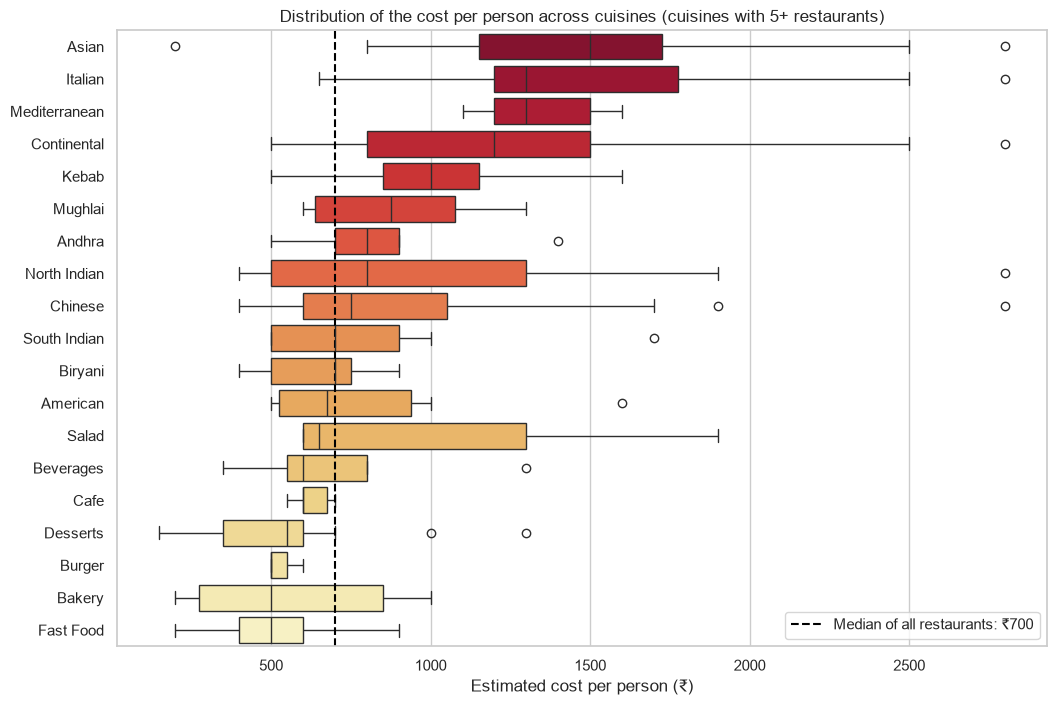

In [29]:
# Chart - 16 visualization code
# One row per restaurant per cuisine, then keep the cuisines served by at least 5 restaurants
cost_cuisine = df.explode("Cuisines_List")
main = cost_cuisine["Cuisines_List"].value_counts()
cost_cuisine = cost_cuisine[cost_cuisine["Cuisines_List"].isin(main[main >= 5].index)]

# Sort the cuisines from the most expensive to the cheapest (by median cost)
order = cost_cuisine.groupby("Cuisines_List")["Cost"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 8))
# hue_order=order makes the colours follow the price order: dark red = most expensive, light yellow = cheapest
sns.boxplot(x="Cost", y="Cuisines_List", data=cost_cuisine, order=order,
            hue="Cuisines_List", hue_order=order, palette="YlOrRd_r", legend=False)
plt.axvline(df["Cost"].median(), color="black", linestyle="--", label=f"Median of all restaurants: ₹{df['Cost'].median():.0f}")
plt.title("Distribution of the cost per person across cuisines (cuisines with 5+ restaurants)")
plt.xlabel("Estimated cost per person (₹)")
plt.ylabel("")
plt.legend(loc="lower right")
plt.show()

##### 1. Why did you pick the specific chart?

I used a box plot for each cuisine because I wanted to see the whole price range, not just one average. The line in each box is the median cost, the box shows where the middle half of the restaurants sit, and the whiskers and dots show the cheapest and most expensive ones. I sorted the cuisines from the most expensive to the cheapest and added the overall median (₹700) as a dashed line, so it's easy to see which cuisines are above or below it.

##### 2. What is/are the insight(s) found from the chart?

- The most expensive cuisines are Asian (median ₹1,500 per person), then Italian and Mediterranean (₹1,300) and Continental (₹1,200). They're mostly served in upscale and hotel restaurants.
- The cheapest are Fast Food, Bakery and Burger (₹500) and Desserts (₹550), all below the overall median of ₹700.
- North Indian and Chinese have the widest ranges, from about ₹400 up to ₹2,800. They're everywhere, from small budget places to 5-star hotels, which also explains why their ratings vary so much.
- Biryani stays affordable (₹400 to ₹900), and Cafe and Burger have very narrow ranges, so their prices are very predictable.
- When I put this next to Chart 13, there's a clear pattern: the expensive cuisines (Asian, Mediterranean, Continental, Italian) are also among the best rated, and the cheap ones (Fast Food, Biryani) are among the lowest rated. That's the cost vs benefit link the brief asked about.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Zomato can use this to set the right expectations and filters for customers: someone looking for Asian or Italian food should expect to pay around double what they'd pay for fast food or biryani. It also helps with cost vs benefit: the premium cuisines cost more but are also rated higher, so customers mostly get what they pay for.

The negative side is in the cheap cuisines. Fast food and biryani are affordable and ordered a lot, but they're also among the lowest rated, so a lot of customers end up paying little for an experience that disappoints them. That's where Zomato could highlight the best budget options, so customers find good value instead of just low prices. Also, cuisines like North Indian and Chinese cover every price level, so for them the cuisine alone says nothing about the price. Zomato should show the cost clearly in the app, so customers don't get a surprise on the bill.

#### Chart - 17 - Most popular restaurants grouped by cuisines

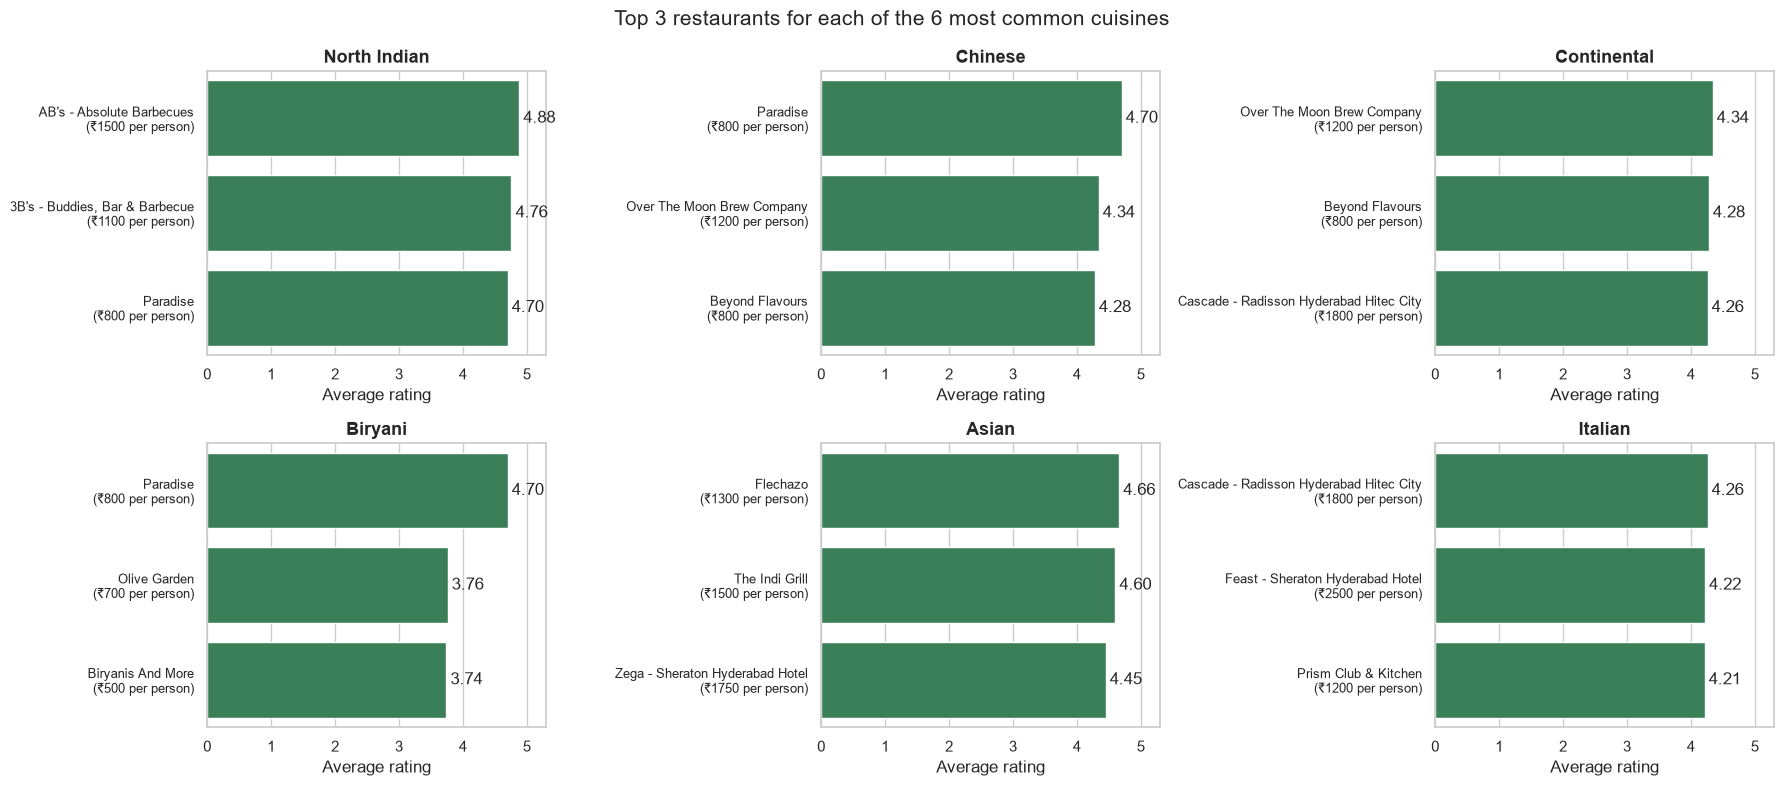

In [30]:
# Chart - 17 visualization code
# Every restaurant has exactly 100 reviews, so popularity is measured by the average rating customers give
rated_cuisine = df.dropna(subset=["Avg_Rating"]).explode("Cuisines_List")
top_cuisines = rated_cuisine["Cuisines_List"].value_counts().head(6).index   # the 6 most common cuisines

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, cuisine in zip(axes.flatten(), top_cuisines):
    # Top 3 restaurants of this cuisine by average rating
    top3 = rated_cuisine[rated_cuisine["Cuisines_List"] == cuisine].nlargest(3, "Avg_Rating")
    labels = [f"{name}\n(₹{cost} per person)" for name, cost in zip(top3["Name"], top3["Cost"])]
    sns.barplot(x=top3["Avg_Rating"].values, y=labels, color="seagreen", ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
    ax.set_xlim(0, 5.3)
    ax.set_title(f"{cuisine}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Average rating")
    ax.tick_params(axis="y", labelsize=9)

plt.suptitle("Top 3 restaurants for each of the 6 most common cuisines", fontsize=15)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The brief asks to help customers find the best restaurant, so I wanted a "best of" for each type of food. I used a grid of small horizontal bar charts, one per cuisine, for the 6 most common cuisines, with the 3 best-rated restaurants in each. Every restaurant in the dataset has exactly 100 reviews, so the number of reviews can't show popularity. That's why I used the average rating, which is what customers actually think of the place. I also added the cost per person under each name, so the chart shows quality and price together.

##### 2. What is/are the insight(s) found from the chart?

- Paradise is the big winner: it's in the top 3 for North Indian, Chinese and Biryani, with a rating of 4.70 for only ₹800 per person. It's the best value in the whole dataset.
- North Indian has the strongest top 3: AB's - Absolute Barbecues (4.88), 3B's (4.76) and Paradise (4.70).
- Biryani has a huge gap: Paradise is at 4.70, but the next best are only Olive Garden (3.76) and Biryanis And More (3.74). So outside Paradise, there's no really great biryani place in this data.
- Asian has the best top 3 overall (Flechazo 4.66, The Indi Grill 4.60, Zega at the Sheraton 4.45), but they're all expensive, from ₹1,300 to ₹1,750 per person.
- For Italian and Continental, the best places are mostly hotel restaurants like Cascade at the Radisson (₹1,800) and Feast at the Sheraton (₹2,500).
- Multi-cuisine restaurants like Over The Moon Brew Company, Beyond Flavours and Cascade show up in several lists, so they do several cuisines well.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This is exactly what a customer needs when they know what they want to eat: Zomato could show a "best for each cuisine" list in the app, with the price, so customers find a great place quickly. Restaurants like Paradise (top rated for ₹800) are perfect to promote as "best value", and Zomato can use these places as an example for other restaurants of the same cuisine.

The negative side is the biryani market. Biryani is one of the most common cuisines, but apart from Paradise, the best ones are only rated around 3.7. That's a weakness: if Paradise has a bad day or is too busy, customers don't have a great alternative. It's also an opportunity for Zomato to bring in, or help improve, good biryani restaurants. And the best Asian, Italian and Continental places are all expensive, so there's a gap for good quality at a lower price in those cuisines.

#### Chart - 18 - Identifying the critics in the industry

7446 reviewers in total, 220 critics with 1,000+ followers (3.0%)
Average rating given: critics = 3.83 | everyone else = 3.57



,Reviews_In_Data,Total_Reviews,Followers,Avg_Rating_Given,Pictures_Posted
Reviewer,,,,,
Satwinder Singh,3,186,13410,3.67,12
Eat_vth_me,1,60,13320,5.00,25
Samar Sardar,2,8,11329,3.50,6
Foodies Hyderabad,4,31,9494,4.50,3
Srinivas,7,34,7628,3.71,0
Aman Arora,1,30,7589,4.00,0
ASH&B2,3,98,6931,3.33,0
Hasanthi Mula,1,31,5879,3.00,9
#FOODPORN,1,35,5873,5.00,0


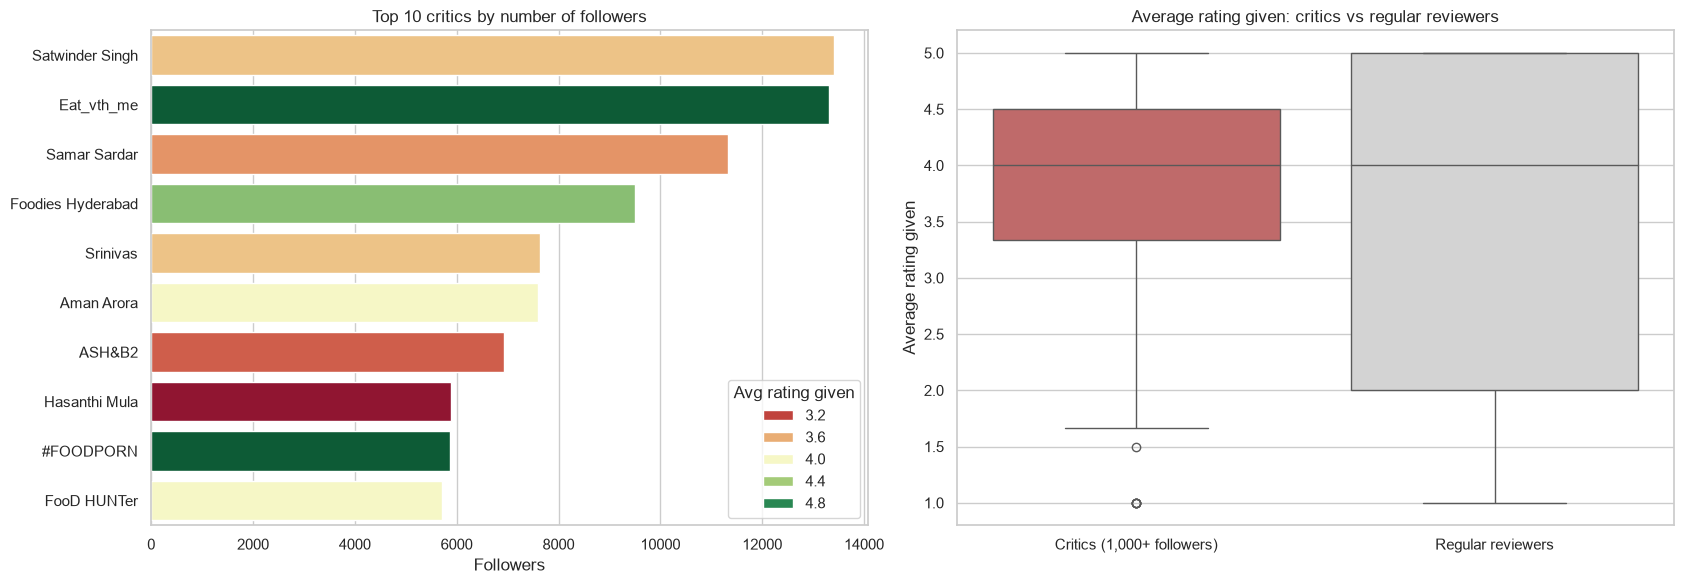

In [31]:
# Chart - 18 visualization code
# One row per reviewer: their reach (followers), their experience (total reviews on Zomato),
# and how they rate restaurants on average
reviewers = rev.groupby("Reviewer").agg(
    Reviews_In_Data=("Rating", "count"),
    Total_Reviews=("Reviewer_Reviews", "max"),
    Followers=("Reviewer_Followers", "max"),
    Avg_Rating_Given=("Rating", "mean"),
    Pictures_Posted=("Pictures", "sum"),
)

# Critics = reviewers with the biggest audience (1,000+ followers)
critics = reviewers[reviewers["Followers"] >= 1000]
print(f"{len(reviewers)} reviewers in total, {len(critics)} critics with 1,000+ followers "
      f"({len(critics) / len(reviewers):.1%})")
print(f"Average rating given: critics = {critics['Avg_Rating_Given'].mean():.2f} | "
      f"everyone else = {reviewers.loc[reviewers['Followers'] < 1000, 'Avg_Rating_Given'].mean():.2f}\n")

top10 = reviewers.sort_values("Followers", ascending=False).head(10)
display(top10.round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Left: the 10 most followed reviewers, coloured by the average rating they give
sns.barplot(x=top10["Followers"], y=top10.index, hue=top10["Avg_Rating_Given"].round(1),
            palette="RdYlGn", dodge=False, ax=axes[0])
axes[0].set_title("Top 10 critics by number of followers")
axes[0].set_xlabel("Followers")
axes[0].set_ylabel("")
axes[0].legend(title="Avg rating given", loc="lower right")

# Right: how critics rate compared to regular reviewers
group = np.where(reviewers["Followers"] >= 1000, "Critics (1,000+ followers)", "Regular reviewers")
sns.boxplot(x=group, y=reviewers["Avg_Rating_Given"], hue=group,
            palette=["indianred", "lightgray"], legend=False, ax=axes[1])
axes[1].set_title("Average rating given: critics vs regular reviewers")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average rating given")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The brief asks to use the reviewer metadata to identify the critics in the industry. I grouped the reviews by reviewer and defined critics as reviewers with 1,000 followers or more, since they have the biggest audience. On the left, a bar chart ranks the 10 most followed critics, coloured by the average rating they give, so I can see who they are and how tough they are at the same time. On the right, a box plot compares the ratings given by critics and regular reviewers, to see if critics rate differently.

##### 2. What is/are the insight(s) found from the chart?

- Out of 7,446 reviewers, only 220 are critics with 1,000+ followers, so about 3%. A very small group, but each of them reaches thousands of people.
- The most followed critic is Satwinder Singh, with 13,410 followers and 186 reviews on Zomato. Next are Eat_vth_me (13,320) and Samar Sardar (11,329).
- Some critics are clearly food blogs or influencer pages, like Eat_vth_me, Foodies Hyderabad and #FOODPORN, and they give very high ratings (4.5 to 5).
- Others are much tougher: Hasanthi Mula gives 3.0 on average and ASH&B2 gives 3.33.
- I expected critics to be harsher, but it's the opposite: they give an average of 3.83, against 3.57 for everyone else.
- Critics are also more consistent: most of their ratings are between 3.3 and 4.5. Regular reviewers go from 2 to 5, because a lot of them only write one review, usually after a really great or really bad experience.
- Most critics only appear 1 to 7 times in this data, so they spread their visits across a lot of different restaurants.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Critics are a small group with a huge reach, so they're very valuable for Zomato and for restaurants. Zomato could identify them automatically with this kind of analysis, invite them to new restaurants, give them badges or early access, and use their reviews to promote good places. Since they tend to be positive and fair, their reviews can help good restaurants get noticed.

The negative side is that one bad review from a critic with 13,000 followers can damage a restaurant much more than a normal review. Restaurants should know who these critics are and make sure they get a great experience. There's also a trust risk: some of the most followed accounts give almost only 5 stars, so if customers start to feel these reviews are too generous or sponsored, they may stop trusting the ratings on Zomato. One limitation of my analysis: reviewers are only identified by their name, so two people with the same common name would be counted as one.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on my charts, I picked three things I noticed and want to check properly with statistics:

1. **Reviews with pictures get higher ratings than reviews without pictures.** In Chart 9, reviews with pictures had an average of 3.86 against 3.54 without.
2. **Premium restaurants (more than ₹1,000 per person) get higher ratings than budget and mid-range restaurants.** In Charts 5 and 15, the expensive restaurants seemed better rated.
3. **There's a positive correlation between the cost of a restaurant and its average rating.** In Chart 5, the correlation was 0.42, but I want to check that it's statistically significant and not just luck with only 100 restaurants.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** There's no difference between the average rating of reviews with pictures and reviews without pictures.
- **Alternate hypothesis (H1):** Reviews with pictures have a higher average rating than reviews without pictures.

#### 2. Perform an appropriate statistical test.

In [32]:
# Perform Statistical Test to obtain P-Value
from scipy import stats

with_pics = rev.loc[rev["Pictures"] > 0, "Rating"]
without_pics = rev.loc[rev["Pictures"] == 0, "Rating"]

print(f"With pictures   : {len(with_pics)} reviews, mean rating = {with_pics.mean():.2f}")
print(f"Without pictures: {len(without_pics)} reviews, mean rating = {without_pics.mean():.2f}")

# Welch's t-test, one-sided: is the 'with pictures' mean greater?
t_stat, p_value = stats.ttest_ind(with_pics, without_pics, equal_var=False, alternative="greater")
print(f"\nT-statistic = {t_stat:.3f}")
print(f"P-value     = {p_value:.2e}")

if p_value < 0.05:
    print("Result: p < 0.05, so I reject H0. Reviews with pictures have a significantly higher rating.")
else:
    print("Result: p >= 0.05, so I fail to reject H0. No significant difference.")

With pictures   : 1983 reviews, mean rating = 3.86
Without pictures: 7978 reviews, mean rating = 3.54

T-statistic = 10.981
P-value     = 5.49e-28
Result: p < 0.05, so I reject H0. Reviews with pictures have a significantly higher rating.


##### Which statistical test have you done to obtain P-Value?

I used a one-sided Welch's t-test (independent two-sample t-test with unequal variances). It gave me a t-statistic of 10.98 and a p-value of 5.49e-28, which is way below 0.05. So I reject H0: reviews with pictures (mean 3.86, 1,983 reviews) have a significantly higher rating than reviews without pictures (mean 3.54, 7,978 reviews).

##### Why did you choose the specific statistical test?

I'm comparing the average of a numerical variable (the rating) between two independent groups (reviews with and without pictures), and that's exactly what a t-test is for.

I chose the Welch version because the two groups are very different in size (about 2,000 vs 8,000 reviews) and I can't assume they have the same spread. Welch's test doesn't need that assumption, so it's safer than the classic t-test. The ratings aren't perfectly normal, but with this many reviews in each group the t-test is still reliable.

I made it one-sided because my hypothesis isn't just that the ratings are different, it's that they're higher with pictures.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** Premium restaurants (more than ₹1,000 per person) have the same average rating as the other restaurants (₹1,000 or less).
- **Alternate hypothesis (H1):** Premium restaurants have a higher average rating than the other restaurants.

#### 2. Perform an appropriate statistical test.

In [33]:
# Perform Statistical Test to obtain P-Value
rated = df.dropna(subset=["Avg_Rating"])    # the 100 restaurants that have reviews

premium = rated.loc[rated["Cost"] > 1000, "Avg_Rating"]
others = rated.loc[rated["Cost"] <= 1000, "Avg_Rating"]

print(f"Premium (> ₹1000): {len(premium)} restaurants, mean rating = {premium.mean():.2f}")
print(f"Others  (≤ ₹1000): {len(others)} restaurants, mean rating = {others.mean():.2f}")

# Step 1: check if each group is normally distributed (Shapiro-Wilk test)
print(f"\nShapiro-Wilk p-value, premium: {stats.shapiro(premium).pvalue:.3f}")
print(f"Shapiro-Wilk p-value, others : {stats.shapiro(others).pvalue:.3f}")

# Step 2: Mann-Whitney U test, one-sided: are premium ratings greater?
u_stat, p_value = stats.mannwhitneyu(premium, others, alternative="greater")
print(f"\nU-statistic = {u_stat:.1f}")
print(f"P-value     = {p_value:.2e}")

if p_value < 0.05:
    print("Result: p < 0.05, so I reject H0. Premium restaurants have a significantly higher rating.")
else:
    print("Result: p >= 0.05, so I fail to reject H0. No significant difference.")
# Confirmation with Welch's t-test, since Shapiro-Wilk didn't reject normality
t_stat, p_value_t = stats.ttest_ind(premium, others, equal_var=False, alternative="greater")
print(f"\nWelch t-test confirmation: t = {t_stat:.3f}, p-value = {p_value_t:.2e}")

Premium (> ₹1000): 31 restaurants, mean rating = 3.95
Others  (≤ ₹1000): 69 restaurants, mean rating = 3.45

Shapiro-Wilk p-value, premium: 0.131
Shapiro-Wilk p-value, others : 0.380

U-statistic = 1622.5
P-value     = 1.91e-05
Result: p < 0.05, so I reject H0. Premium restaurants have a significantly higher rating.

Welch t-test confirmation: t = 4.837, p-value = 6.18e-06


##### Which statistical test have you done to obtain P-Value?

I used a one-sided Mann-Whitney U test, and I confirmed it with a one-sided Welch's t-test. The Mann-Whitney test gave me a p-value of 1.91e-05, and the Welch t-test gave t = 4.84 with a p-value of 6.18e-06. Both are way below 0.05, so I reject H0: premium restaurants (mean rating 3.95, 31 restaurants) have a significantly higher rating than the others (mean 3.45, 69 restaurants).

##### Why did you choose the specific statistical test?

This time I'm comparing restaurants, not reviews, so the groups are small: 31 premium restaurants against 69 others. With small groups, a t-test only really works if the data is normally distributed, so I checked that first with the Shapiro-Wilk test.

I chose the Mann-Whitney U test as my main test because it doesn't need the data to be normal. It ranks all the restaurants from the lowest to the highest rating and checks if the premium ones tend to be ranked higher. It's the safer option when the samples are small.

The Shapiro-Wilk p-values were 0.131 and 0.380, both above 0.05, so I couldn't reject normality. That means the t-test was also valid here, so I ran a Welch's t-test as a confirmation, and both tests agree. I made both tests one-sided because my hypothesis is that premium restaurants are rated higher, not just differently.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** There's no correlation between the cost of a restaurant and its average rating (the correlation is 0).
- **Alternate hypothesis (H1):** There's a positive correlation between the cost of a restaurant and its average rating.

#### 2. Perform an appropriate statistical test.

In [34]:
# Perform Statistical Test to obtain P-Value
# 'rated' = the 100 restaurants that have reviews (created in the previous test)

# Pearson: measures a straight-line relationship
r, p_pearson = stats.pearsonr(rated["Cost"], rated["Avg_Rating"], alternative="greater")
print(f"Pearson correlation  r   = {r:.3f}, p-value = {p_pearson:.2e}")

# Spearman: measures any relationship that always goes in the same direction, based on ranks
rho, p_spearman = stats.spearmanr(rated["Cost"], rated["Avg_Rating"], alternative="greater")
print(f"Spearman correlation rho = {rho:.3f}, p-value = {p_spearman:.2e}")

if p_pearson < 0.05 and p_spearman < 0.05:
    print("\nResult: both p < 0.05, so I reject H0. Cost and rating are significantly positively correlated.")
else:
    print("\nResult: at least one p >= 0.05, so I can't clearly reject H0.")

Pearson correlation  r   = 0.421, p-value = 6.37e-06
Spearman correlation rho = 0.383, p-value = 4.27e-05

Result: both p < 0.05, so I reject H0. Cost and rating are significantly positively correlated.


##### Which statistical test have you done to obtain P-Value?

I used two correlation tests, both one-sided: the Pearson correlation test and the Spearman rank correlation test.
- Pearson gave r = 0.421 with a p-value of 6.37e-06.
- Spearman gave rho = 0.383 with a p-value of 4.27e-05.

Both p-values are way below 0.05, so I reject H0. There's a significant positive correlation between the cost of a restaurant and its average rating: the more expensive the restaurant, the better it tends to be rated. The

##### Why did you choose the specific statistical test?

I'm checking the link between two numerical variables (cost and average rating), so a correlation test is the right tool. It gives me the strength of the link and a p-value to check if it's real.

I used Pearson because it's the standard test for a straight-line relationship. But Pearson is sensitive to extreme values, and Cost has a few outliers (like the ₹2,800 restaurant), plus it's right-skewed. So I also ran Spearman, which works on ranks instead of the actual values, so the outliers can't pull the result. Both tests give a similar correlation and both are significant, so I'm confident the result is solid and not caused by a few extreme restaurants.

I made them one-sided because my hypothesis is specifically a positive correlation.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [35]:
# Handling Missing Values & Missing Value Imputation

# 1. Where are the gaps now?
print("Missing values in the restaurant table:\n", df.isnull().sum()[df.isnull().sum() > 0], "\n")
print("Missing values in the reviews table:\n", rev.isnull().sum()[rev.isnull().sum() > 0], "\n")

# 2. Collections: missing just means the restaurant isn't in any Zomato collection
df["Collections"] = df["Collections"].fillna("Not Listed")
df["In_Collection"] = (df["Collections"] != "Not Listed").astype(int)   # 1 = in at least one collection, 0 = none

# 3. Timings: only 1 missing, and I won't use it as a feature, so a simple label is enough
df["Timings"] = df["Timings"].fillna("Not Available")

# 4. The 5 restaurants with no reviews: no rating, pictures or review length to work with
print("Restaurants with no reviews:", df.loc[df["Avg_Rating"].isnull(), "Name"].tolist())
df_model = df.dropna(subset=["Avg_Rating"]).reset_index(drop=True)   # table used for clustering

print("\nRestaurant table for modelling:", df_model.shape)
print("Missing values left:", df_model.isnull().sum().sum())

Missing values in the restaurant table:
 Collections          54
Timings               1
Avg_Rating            5
Num_Reviews           5
Avg_Pictures          5
Avg_Review_Length     5
dtype: int64 

Missing values in the reviews table:
 Series([], dtype: int64) 

Restaurants with no reviews: ['IndiBlaze', 'Sweet Basket', 'Angaara Counts 3', 'Wich Please', 'Republic Of Noodles - Lemon Tree Hotel']

Restaurant table for modelling: (100, 14)
Missing values left: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

I didn't use one single technique for everything. I looked at why each value was missing and picked the fix that made sense for that case:

- **Collections (54 missing): I filled them with a constant label, "Not Listed".** Here, missing doesn't mean the information was lost. It means the restaurant just isn't part of any Zomato collection. So I made it its own category and I also created a new 0/1 column, `In_Collection`, which turns that into something useful for the analysis.
- **Timings (1 missing): I filled it with "Not Available".** It's only one value and I don't use Timings as a feature in my models, so a simple placeholder is enough. There was no point in guessing the opening hours.
- **Avg_Rating, Avg_Pictures, Avg_Review_Length and Num_Reviews (5 missing): I removed those 5 restaurants from the modelling table.** These are the 5 restaurants that have no reviews at all (IndiBlaze, Sweet Basket, Angaara Counts 3, Wich Please and Republic Of Noodles). I could have filled them with the average or the median, but that would mean inventing a rating for restaurants nobody has reviewed, and adding fake data to my clustering. It's only 5 out of 105, so removing them loses very little. I still keep them in the full table `df`, I just don't use them for the model.
- **Reviews table: nothing left to fix.** I already handled it in the wrangling step (removed the empty rows and the "Like" rating, and left the 7 missing review texts as empty strings).

In the end, my modelling table has 100 restaurants and no missing values.

### 2. Handling Outliers

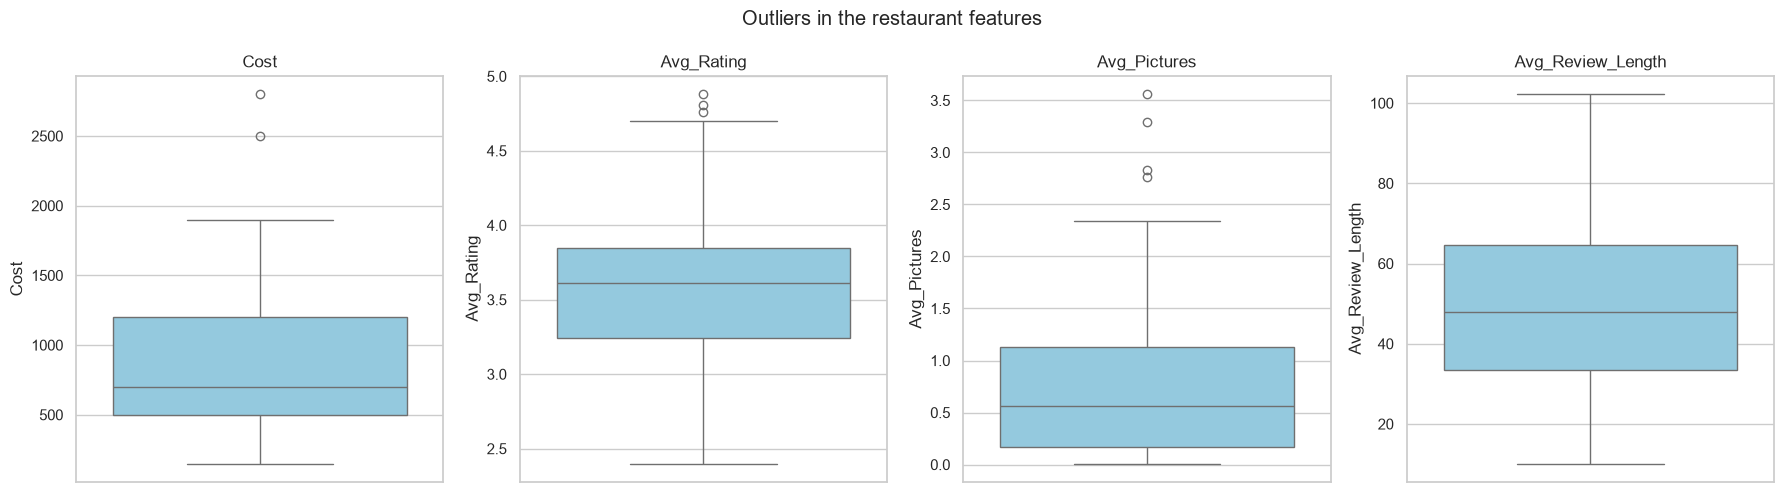

Cost              : 2 outliers (outside -550.0 to 2250.0)
   -> ['Feast - Sheraton Hyderabad Hotel', 'Collage - Hyatt Hyderabad Gachibowli']
Avg_Rating        : 3 outliers (outside 2.3 to 4.7)
   -> ["AB's - Absolute Barbecues", 'B-Dubs', "3B's - Buddies, Bar & Barbecue"]
Avg_Pictures      : 4 outliers (outside -1.3 to 2.6)
   -> ['Marsala Food Company', 'PourHouse7', 'American Wild Wings', 'Arena Eleven']
Avg_Review_Length : 0 outliers (outside -13.3 to 111.5)

Rows before: 100, rows after: 100 (no restaurant removed)


In [36]:
# Handling Outliers & Outlier treatments
outlier_cols = ["Cost", "Avg_Rating", "Avg_Pictures", "Avg_Review_Length"]

# 1. Visualize them with box plots
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df_model[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.suptitle("Outliers in the restaurant features")
plt.tight_layout()
plt.show()

# 2. Count them with the IQR rule
for col in outlier_cols:
    q1, q3 = df_model[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df_model[(df_model[col] < lower) | (df_model[col] > upper)]
    print(f"{col:18}: {len(outliers)} outliers (outside {lower:.1f} to {upper:.1f})")
    if len(outliers) > 0:
        print("   ->", outliers["Name"].tolist())

# 3. Decision: all these outliers are genuine restaurants (premium hotels, top-rated places, very active pubs),
#    not data errors. I keep them, and I'll reduce their influence later with a log transformation and scaling.
print(f"\nRows before: {len(df_model)}, rows after: {len(df_model)} (no restaurant removed)")

##### What all outlier treatment techniques have you used and why did you use those techniques?

I used the IQR method to detect the outliers, with box plots to see them. Anything more than 1.5 times the interquartile range below Q1 or above Q3 counts as an outlier. I found 9 in total:
- **Cost:** 2 restaurants above ₹2,250, Feast at the Sheraton and Collage at the Hyatt. These are 5-star hotel restaurants, so their price really is that high.
- **Avg_Rating:** 3 restaurants above 4.7, AB's - Absolute Barbecues, B-Dubs and 3B's - Buddies, Bar & Barbecue. They're just the best rated restaurants in the dataset.
- **Avg_Pictures:** 4 restaurants above 2.6 pictures per review (Marsala Food Company, PourHouse7, American Wild Wings and Arena Eleven), where customers post a lot more pictures than usual.
- **Avg_Review_Length:** no outliers at all.

I decided to keep all of them, so I still have 100 restaurants before and after. They're not mistakes in the data, they're real restaurants that are just different from the rest. Removing them would mean removing the premium restaurants and the best rated ones, which are exactly the kind of groups I want my clustering to find. And with only 100 restaurants, every row counts.

Instead of deleting or capping them, I'll handle them in the next steps: I'll apply a log transformation to the skewed features (Cost and Avg_Pictures) to bring the extreme values closer to the rest, and then scale all the features so that no single feature dominates the clustering.

### 3. Categorical Encoding

In [37]:
# Encode your categorical columns
from sklearn.preprocessing import MultiLabelBinarizer

# ---------- 1. Cuisines -> one 0/1 column per cuisine (multi-hot encoding) ----------
# Keep only cuisines served by at least 5 restaurants, the rare ones are grouped as "Other"
cuisine_freq = df_model["Cuisines_List"].explode().value_counts()
main_cuisines = cuisine_freq[cuisine_freq >= 5].index

df_model["Cuisines_Grouped"] = df_model["Cuisines_List"].apply(
    lambda lst: sorted(set(c if c in main_cuisines else "Other" for c in lst)))

mlb = MultiLabelBinarizer()
cuisine_dummies = pd.DataFrame(mlb.fit_transform(df_model["Cuisines_Grouped"]),
                               columns=["Cuisine_" + c for c in mlb.classes_],
                               index=df_model.index)
df_model = pd.concat([df_model, cuisine_dummies], axis=1)

print(f"{len(cuisine_freq)} cuisines in total, {len(main_cuisines)} kept + 'Other'")
print("New cuisine columns:", cuisine_dummies.shape[1])
display(df_model[["Name", "Cuisines"] + cuisine_dummies.columns.tolist()[:6]].head())

# ---------- 2. Rating -> Sentiment label (binary encoding) ----------
# 4 and above = positive (1), 2 and below = negative (0), the middle ratings are dropped
rev_sent = rev[(rev["Rating"] >= 4) | (rev["Rating"] <= 2)].copy()
rev_sent["Sentiment"] = (rev_sent["Rating"] >= 4).astype(int)

print("\nReviews kept for sentiment analysis:", len(rev_sent), "out of", len(rev))
print(rev_sent["Sentiment"].value_counts().rename({1: "Positive (1)", 0: "Negative (0)"}))

42 cuisines in total, 18 kept + 'Other'
New cuisine columns: 19


,Name,Cuisines,Cuisine_American,Cuisine_Andhra,Cuisine_Asian,Cuisine_Bakery,Cuisine_Beverages,Cuisine_Biryani
0,Beyond Flavours,"Chinese, Continental, Kebab, European, South Indian, North Indian",0,0,0,0,0,0
1,Paradise,"Biryani, North Indian, Chinese",0,0,0,0,0,1
2,Flechazo,"Asian, Mediterranean, North Indian, Desserts",0,0,1,0,0,0
3,Shah Ghouse Hotel & Restaurant,"Biryani, North Indian, Chinese, Seafood, Beverages",0,0,0,0,1,1
4,Over The Moon Brew Company,"Asian, Continental, North Indian, Chinese, Mediterranean",0,0,1,0,0,0



Reviews kept for sentiment analysis: 8702 out of 9961
Sentiment
Positive (1)    6274
Negative (0)    2428
Name: count, dtype: int64


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used two encoding techniques, one for each part of my project.

**1. Multi-hot encoding for Cuisines (for the clustering)**
A restaurant can serve several cuisines at the same time (Paradise serves Biryani, North Indian and Chinese), so normal one-hot encoding doesn't work, since it assumes one category per row. I used scikit-learn's MultiLabelBinarizer, which creates one 0/1 column per cuisine, and a restaurant can have a 1 in several columns.

I didn't use label encoding (turning each cuisine into a number like 1, 2, 3...) because it would create a fake order, as if Chinese was "bigger" than Biryani. That would mess up the distances in the clustering.

There are 42 different cuisines for only 100 restaurants, and a lot of them appear only once or twice. If I kept all of them, I'd get 42 columns that are almost all zeros, which makes the clustering worse. So I kept the 18 cuisines served by at least 5 restaurants and grouped all the rare ones into "Other". That gives me 19 cuisine columns.

**2. Binary encoding of Rating into Sentiment (for the classification)**
To train a sentiment model, I need a clear label for each review. I turned the rating into a 0/1 variable:
- 4 stars and above = positive (1)
- 2 stars and below = negative (0)

I removed the middle ratings (2.5, 3 and 3.5) because those customers are neither clearly happy nor clearly unhappy, and those reviews would confuse the model while it learns the difference. I kept 8,702 reviews out of 9,961: 6,274 positive and 2,428 negative. So the classes are imbalanced (about 72% vs 28%), which I'll need to handle later.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [38]:
# Expand Contraction
import contractions

# "didn't" -> "did not", "it's" -> "it is". Important to keep the word "not" visible for sentiment
rev_sent["Clean_Review"] = rev_sent["Review"].apply(contractions.fix)

#### 2. Lower Casing

In [39]:
# Lower Casing
# "Good", "GOOD" and "good" should all be the same word for the model
rev_sent["Clean_Review"] = rev_sent["Clean_Review"].str.lower()

#### 3. Removing Punctuations

In [40]:
# Remove Punctuations
# Replace anything that isn't a letter, digit or space (punctuation, emojis) with a space
rev_sent["Clean_Review"] = rev_sent["Clean_Review"].str.replace(r"[^\w\s]", " ", regex=True)

#### 4. Removing URLs & Removing words and digits contain digits.

In [41]:
# Remove URLs & Remove words and digits contain digits
rev_sent["Clean_Review"] = rev_sent["Clean_Review"].str.replace(r"http\S+|www\S+", " ", regex=True)   # links
rev_sent["Clean_Review"] = rev_sent["Clean_Review"].str.replace(r"\w*\d\w*", " ", regex=True)        # "5", "2nd", "100rs"

#### 5. Removing Stopwords & Removing White spaces

In [42]:
# Remove Stopwords
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

# Standard English stopwords, BUT I keep the negations: removing them would turn "not good" into "good"
negations = {"not", "no", "nor", "never"}
stop_words_nlp = set(stopwords.words("english")) - negations

rev_sent["Clean_Review"] = rev_sent["Clean_Review"].apply(
    lambda text: " ".join(word for word in text.split() if word not in stop_words_nlp))

In [43]:
# Remove White spaces
# The previous steps left double spaces behind, this squeezes them into single spaces
rev_sent["Clean_Review"] = rev_sent["Clean_Review"].str.split().str.join(" ")

# Compare before and after on a few reviews
for i in range(3):
    print("BEFORE:", rev_sent["Review"].iloc[i][:200])
    print("AFTER :", rev_sent["Clean_Review"].iloc[i][:200], "\n")

BEFORE: The ambience was good, food was quite good . had Saturday lunch , which was cost effective .
Good place for a sate brunch. One can also chill with friends and or parents.
Waiter Soumen Das was really 
AFTER : ambience good food quite good saturday lunch cost effective good place sate brunch one also chill friends parents waiter soumen das really courteous helpful 

BEFORE: Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soumen Das - kudos to the service
AFTER : ambience good pleasant evening service prompt food good good experience soumen das kudos service 

BEFORE: A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is Penne Alfredo Pasta:) ....... Also the music in the background is amazing.
AFTER : must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta also music background amazing 



#### 6. Rephrase Text

In [44]:
# Rephrase Text
# Replace common slang and abbreviations with the full word, so "thnx" and "thanks" count as the same word
slang_dict = {
    "thnx": "thanks", "thanx": "thanks", "thx": "thanks", "gud": "good", "awsm": "awesome",
    "plz": "please", "pls": "please", "u": "you", "ur": "your", "coz": "because",
    "bcoz": "because", "bcz": "because", "nyc": "nice", "dlvry": "delivery", "yummm": "yummy",
}
rev_sent["Clean_Review"] = rev_sent["Clean_Review"].apply(
    lambda text: " ".join(slang_dict.get(word, word) for word in text.split()))

print(rev_sent["Clean_Review"].iloc[2])

must try great food great ambience thanks service pradeep subroto personal recommendation penne alfredo pasta also music background amazing


#### 7. Tokenization

In [45]:
# Tokenization
nltk.download("punkt_tab", quiet=True)
from nltk.tokenize import word_tokenize

# Split each review into a list of individual words (tokens)
rev_sent["Tokens"] = rev_sent["Clean_Review"].apply(word_tokenize)
print(rev_sent["Tokens"].iloc[0])

['ambience', 'good', 'food', 'quite', 'good', 'saturday', 'lunch', 'cost', 'effective', 'good', 'place', 'sate', 'brunch', 'one', 'also', 'chill', 'friends', 'parents', 'waiter', 'soumen', 'das', 'really', 'courteous', 'helpful']


#### 8. Text Normalization

In [46]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from nltk.stem import WordNetLemmatizer, PorterStemmer

lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

# Quick comparison to show why I picked lemmatization over stemming
for word in ["friends", "dishes", "waiters", "tasty", "delicious", "ordered"]:
    print(f"{word:10} -> stem: {stemmer.stem(word):10} lemma: {lemmatizer.lemmatize(word)}")

# Lemmatization (default noun mode: handles plurals without cutting words wrongly)
rev_sent["Lemmas"] = rev_sent["Tokens"].apply(lambda tokens: [lemmatizer.lemmatize(w) for w in tokens])
rev_sent["Final_Review"] = rev_sent["Lemmas"].str.join(" ")    # back to one string, ready for vectorization

print("\n", rev_sent["Final_Review"].iloc[0])

friends    -> stem: friend     lemma: friend
dishes     -> stem: dish       lemma: dish
waiters    -> stem: waiter     lemma: waiter
tasty      -> stem: tasti      lemma: tasty
delicious  -> stem: delici     lemma: delicious
ordered    -> stem: order      lemma: ordered

 ambience good food quite good saturday lunch cost effective good place sate brunch one also chill friend parent waiter soumen da really courteous helpful


##### Which text normalization technique have you used and why?

I used lemmatization with NLTK's WordNet lemmatizer.

Before choosing, I compared it with stemming (Porter Stemmer) on a few words from the reviews. Stemming just chops off the end of words with fixed rules, so it often creates words that don't exist: "tasty" became "tasti" and "delicious" became "delici". Lemmatization looks the word up in a dictionary and gives back the real base word, so "friends" becomes "friend", "dishes" becomes "dish" and "waiters" becomes "waiter", while "tasty" and "delicious" stay as they are. For sentiment analysis I want to keep real, readable words, because I need to be able to explain what words drive the predictions.

I used the default noun mode. I also tested lemmatizing words as verbs, but it cut some words wrongly, for example "evening" became "even" and "amazing" became "amaze". The noun mode is safer: it mainly merges plurals with their singular, which is what helps the most here, and it doesn't damage words.

It's not perfect. For example the name "Das" (a waiter's name) became "da" because the dictionary treats it as a plural. But names don't carry any sentiment, so it doesn't affect the model.

#### 9. Part of speech tagging

In [47]:
# POS Taging
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

# Tag every word with its grammatical role (noun, adjective, verb...)
rev_sent["POS_Tags"] = rev_sent["Tokens"].apply(nltk.pos_tag)
print(rev_sent["POS_Tags"].iloc[0][:10])

# Adjectives (tags starting with JJ) carry most of the opinion, so compare them between the two classes
def top_adjectives(sentiment, n=12):
    tags = rev_sent.loc[rev_sent["Sentiment"] == sentiment, "POS_Tags"].explode().dropna()
    adjectives = [word for word, tag in tags if tag.startswith("JJ")]
    return pd.Series(adjectives).value_counts().head(n)

print("\nTop adjectives in POSITIVE reviews:\n", top_adjectives(1))
print("\nTop adjectives in NEGATIVE reviews:\n", top_adjectives(0))

[('ambience', 'RB'), ('good', 'JJ'), ('food', 'NN'), ('quite', 'RB'), ('good', 'JJ'), ('saturday', 'NN'), ('lunch', 'NN'), ('cost', 'NN'), ('effective', 'JJ'), ('good', 'JJ')]

Top adjectives in POSITIVE reviews:
 good         5244
great        1621
nice         1165
best         1096
awesome       642
delicious     585
overall       485
excellent     378
main          370
tasty         339
chicken       338
friendly      324
Name: count, dtype: int64

Top adjectives in NEGATIVE reviews:
 good            783
bad             539
worst           443
pathetic        187
chicken         124
great           118
much            117
disappointed    116
poor            111
main            109
table           108
horrible        106
Name: count, dtype: int64


#### 10. Text Vectorization

In [48]:
# Vectorizing Text
from sklearn.feature_extraction.text import TfidfVectorizer

# Remove reviews that became empty after cleaning (they have no words left to learn from)
print("Empty reviews after cleaning:", (rev_sent["Final_Review"].str.strip() == "").sum())
rev_sent = rev_sent[rev_sent["Final_Review"].str.strip() != ""].reset_index(drop=True)
print("Reviews left:", len(rev_sent))

# TF-IDF with single words AND pairs of words (so "not good" is kept as one feature)
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5)
X_text_preview = tfidf.fit_transform(rev_sent["Final_Review"])
print("\nTF-IDF matrix shape:", X_text_preview.shape)

# Show a few of the word pairs it learned that include "not"
not_pairs = [w for w in tfidf.get_feature_names_out() if w.startswith("not ")]
print("Examples of 'not' pairs:", not_pairs[:15])

Empty reviews after cleaning: 28
Reviews left: 8674

TF-IDF matrix shape: (8674, 5000)
Examples of 'not' pairs: ['not able', 'not accept', 'not acceptable', 'not allow', 'not allowed', 'not anything', 'not available', 'not bad', 'not believe', 'not best', 'not big', 'not care', 'not clean', 'not come', 'not cooked']


##### Which text vectorization technique have you used and why?

I used TF-IDF (Term Frequency - Inverse Document Frequency) with scikit-learn's TfidfVectorizer.

A model can't read text, it only understands numbers, so I need to turn each review into a row of numbers. TF-IDF gives each word a score in each review: the score is high when the word appears a lot in that review but rarely in the others. So words that are everywhere, like "food" or "place", get a low score, and words that really say something, like "pathetic" or "delicious", get a high one. That's better than a simple word count (Bag of Words), where the most common words would dominate even though they don't help tell a positive review from a negative one.

The settings I chose:
- **ngram_range=(1, 2):** I keep single words and pairs of words. This was really important for me, because my word cloud showed that "good" was the biggest word in the negative reviews, since people write "not good". With pairs, "not good", "not cooked" or "not clean" become their own features, so the model can catch the negation.
- **max_features=5000:** I keep the 5,000 most useful words and pairs, so the matrix doesn't get huge and slow.
- **min_df=5:** a word has to appear in at least 5 reviews to be kept. That removes typos and very rare words that would only add noise.

Before vectorizing, I removed 28 reviews that were empty after cleaning, which left me with 8,674 reviews and a TF-IDF matrix of 8,674 x 5,000. This was just a preview. In the data splitting step, I fit the TF-IDF on the training reviews only, so the test reviews stay completely unseen and the evaluation is fair.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [49]:
# Manipulate Features to minimize feature correlation and create new features

# Candidate numerical features for the clustering
candidate_features = ["Cost", "Avg_Rating", "Avg_Pictures", "Avg_Review_Length", "Num_Cuisines"]
print("Correlation BEFORE:")
display(df_model[candidate_features].corr().round(2))

# Avg_Pictures and Avg_Review_Length are 0.81 correlated: they both measure how engaged customers are.
# Keeping both would count that information twice, so I keep only Avg_Review_Length
# (it has no outliers, while Avg_Pictures has 4).
cluster_num_features = ["Cost", "Avg_Rating", "Avg_Review_Length", "Num_Cuisines"]
print("Correlation AFTER:")
display(df_model[cluster_num_features].corr().round(2))

# Cuisine columns created in the encoding step
cuisine_cols = [c for c in df_model.columns if c.startswith("Cuisine_")]
print(f"\nClustering features: {len(cluster_num_features)} numerical + {len(cuisine_cols)} cuisine columns")

Correlation BEFORE:


,Cost,Avg_Rating,Avg_Pictures,Avg_Review_Length,Num_Cuisines
Cost,1.00,0.42,0.40,0.53,0.39
Avg_Rating,0.42,1.00,0.22,0.23,0.11
Avg_Pictures,0.40,0.22,1.00,0.81,0.19
Avg_Review_Length,0.53,0.23,0.81,1.00,0.29
Num_Cuisines,0.39,0.11,0.19,0.29,1.00


Correlation AFTER:


,Cost,Avg_Rating,Avg_Review_Length,Num_Cuisines
Cost,1.00,0.42,0.53,0.39
Avg_Rating,0.42,1.00,0.23,0.11
Avg_Review_Length,0.53,0.23,1.00,0.29
Num_Cuisines,0.39,0.11,0.29,1.00



Clustering features: 4 numerical + 19 cuisine columns


#### 2. Feature Selection

Removed because they never change: []
Final clustering table: (100, 23)


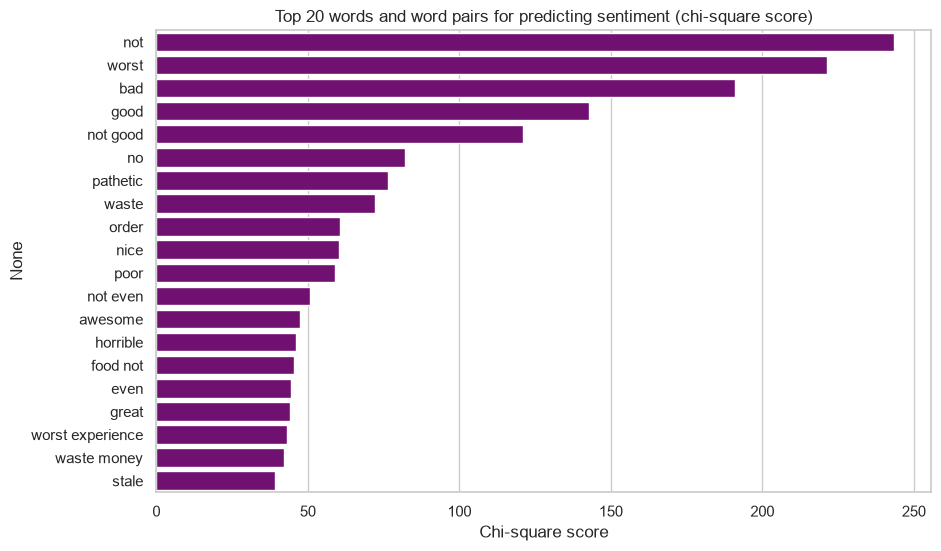

In [50]:
# Select your features wisely to avoid overfitting
from sklearn.feature_selection import VarianceThreshold, chi2

# ---------- Clustering: remove features that don't vary at all ----------
check = df_model[cluster_num_features + ["Num_Reviews"]]
vt = VarianceThreshold(threshold=0.0).fit(check)
print("Removed because they never change:", check.columns[~vt.get_support()].tolist())

X_cluster = df_model[cluster_num_features + cuisine_cols].copy()
print("Final clustering table:", X_cluster.shape)

# ---------- Sentiment: which words best separate positive and negative reviews? ----------
chi_scores, _ = chi2(X_text_preview, rev_sent["Sentiment"])
top_words = pd.Series(chi_scores, index=tfidf.get_feature_names_out()).sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_words.values, y=top_words.index, color="purple")
plt.title("Top 20 words and word pairs for predicting sentiment (chi-square score)")
plt.xlabel("Chi-square score")
plt.show()

##### What all feature selection methods have you used  and why?

I used three methods, because my two models need different features.

**1. Correlation analysis (for the clustering)**
I checked the correlation between my numerical features. Avg_Pictures and Avg_Review_Length had a correlation of 0.81, so they basically measure the same thing: how engaged customers are with a restaurant. If I kept both, that information would count twice in the clustering distances. I kept Avg_Review_Length because it has no outliers, while Avg_Pictures had 4. After that, no pair of features is above 0.53, so each feature brings its own information.

**2. Variance Threshold (for the clustering)**
I removed features that never change. Num_Reviews is 100 for every restaurant, so it can't help tell restaurants apart. VarianceThreshold confirmed it and removed it.

**3. Chi-square test (for the sentiment model)**
For the text, I already limited the TF-IDF to 5,000 words and pairs, and only kept words that appear in at least 5 reviews, which removes typos and rare noise. Then I used the chi-square test to score how strongly each word is linked to the positive or negative label. I didn't use it to cut more words, since 5,000 features is fine for the models I'll use, but it helped me check that the model has the right information to learn from.

In the end, my clustering table has 100 restaurants and 23 features: 4 numerical (Cost, Avg_Rating, Avg_Review_Length, Num_Cuisines) and 19 cuisine columns.

##### Which all features you found important and why?

**For the clustering:**
- **Cost:** it's the feature most linked to everything else (rating, review length, number of cuisines), and the hypothesis tests showed premium restaurants are rated significantly higher. It's the main thing that separates restaurant types.
- **Avg_Rating:** it tells the good restaurants from the bad ones, which is the most useful information for customers and for Zomato.
- **Avg_Review_Length:** it represents customer engagement. Longer reviews (and more pictures) come with the more upscale dine-in places.
- **Num_Cuisines and the cuisine columns:** they describe what kind of food the restaurant serves, like a biryani place vs a multi-cuisine restaurant vs a cafe.

**For the sentiment model:**
The chi-square test showed the most important words. The top one is "not", even ahead of "worst" and "bad". Then come "good", "not good", "no", "pathetic", "waste", "nice", "poor", "not even", "awesome" and "horrible". Pairs like "not good", "worst experience" and "waste money" are in the top 20 too. This confirms two choices I made in the preprocessing: keeping the negation words when I removed stopwords, and using word pairs in the TF-IDF. Without them, the model would see "not good" as "good" and get it wrong.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Skewness BEFORE:
 Cost                 1.17
Avg_Rating           0.28
Avg_Review_Length    0.26
Num_Cuisines         0.15
dtype: float64 

Skewness AFTER:
 Cost                -0.37
Avg_Rating           0.28
Avg_Review_Length    0.26
Num_Cuisines         0.15
dtype: float64


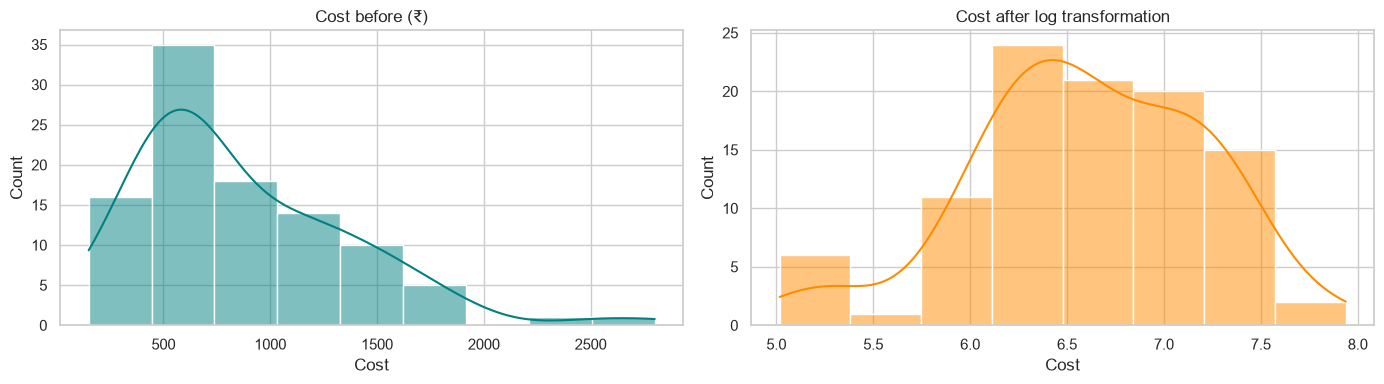

In [51]:
# Transform Your data
# Check how skewed the numerical clustering features are (0 = symmetric, above 1 = strongly skewed)
print("Skewness BEFORE:\n", X_cluster[cluster_num_features].skew().round(2), "\n")

# Cost is right-skewed with 2 premium outliers: log1p = log(1 + x) pulls the big values closer to the rest
X_cluster["Cost"] = np.log1p(X_cluster["Cost"])

print("Skewness AFTER:\n", X_cluster[cluster_num_features].skew().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_model["Cost"], kde=True, ax=axes[0], color="teal").set_title("Cost before (₹)")
sns.histplot(X_cluster["Cost"], kde=True, ax=axes[1], color="darkorange").set_title("Cost after log transformation")
plt.tight_layout()
plt.show()

Yes, but only one feature needed it.

I checked the skewness of my 4 numerical clustering features (0 means perfectly symmetric, and above 1 means strongly skewed):
- Cost: 1.17
- Avg_Rating: 0.28
- Avg_Review_Length: 0.26
- Num_Cuisines: 0.15

Cost was the only one that was strongly right-skewed: most restaurants cost between ₹300 and ₹1,200, and a few premium hotel restaurants go up to ₹2,800. Clustering algorithms like K-Means work with distances, so those expensive restaurants would sit far away from everything else and pull the clusters towards them.

I used a log transformation, np.log1p (log of 1 + x). It squeezes the big values a lot more than the small ones, so the expensive restaurants get closer to the others without being removed. After the transformation, the skewness of Cost went from 1.17 to -0.37, so it's now close to symmetric, and the histogram looks much more balanced. This is also how I handled the 2 Cost outliers, as I planned in the outlier treatment step.

I didn't transform the other features because they were already close to symmetric. The cuisine columns are 0/1, so a transformation wouldn't make sense for them either.

### 6. Data Scaling

In [52]:
# Scaling your data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scale only the 4 numerical features: the cuisine columns are already 0/1 and stay as they are
X_cluster_scaled = X_cluster.copy()
X_cluster_scaled[cluster_num_features] = scaler.fit_transform(X_cluster[cluster_num_features])

print("BEFORE scaling:")
display(X_cluster[cluster_num_features].describe().loc[["mean", "std", "min", "max"]].round(2))
print("AFTER scaling:")
display(X_cluster_scaled[cluster_num_features].describe().loc[["mean", "std", "min", "max"]].round(2))

BEFORE scaling:


,Cost,Avg_Rating,Avg_Review_Length,Num_Cuisines
mean,6.60,3.60,50.30,3.01
std,0.60,0.51,22.65,1.21
min,5.02,2.40,10.13,1.00
max,7.94,4.88,102.24,6.00


AFTER scaling:


,Cost,Avg_Rating,Avg_Review_Length,Num_Cuisines
mean,0.00,-0.00,0.00,0.00
std,1.01,1.01,1.01,1.01
min,-2.64,-2.38,-1.78,-1.67
max,2.22,2.53,2.30,2.48


##### Which method have you used to scale you data and why?

I used Standardization with scikit-learn's StandardScaler. It transforms each feature so it has a mean of 0 and a standard deviation of 1.

I needed scaling because K-Means and hierarchical clustering work with distances between restaurants. Before scaling, my features were on very different scales: Avg_Rating went from 2.4 to 4.88, while Avg_Review_Length went from 10 to 102. Without scaling, review length would decide almost everything in the distances, just because its numbers are bigger, and the rating would barely count. After scaling, all 4 numerical features are on the same scale (roughly between -2.6 and 2.5), so each one has a fair weight.

I chose StandardScaler over MinMaxScaler because MinMaxScaler squeezes everything between 0 and 1 using the minimum and the maximum, so it's very sensitive to extreme values. I kept my outliers on purpose (the premium and top-rated restaurants), so standardization is the safer option.

I only scaled the 4 numerical features (Cost after the log transformation, Avg_Rating, Avg_Review_Length and Num_Cuisines). I left the 19 cuisine columns as 0 and 1, since they're already on a small, clear scale and represent yes/no information.

For the sentiment model, I don't need extra scaling: TF-IDF already produces normalized values for each review.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Answer Here.

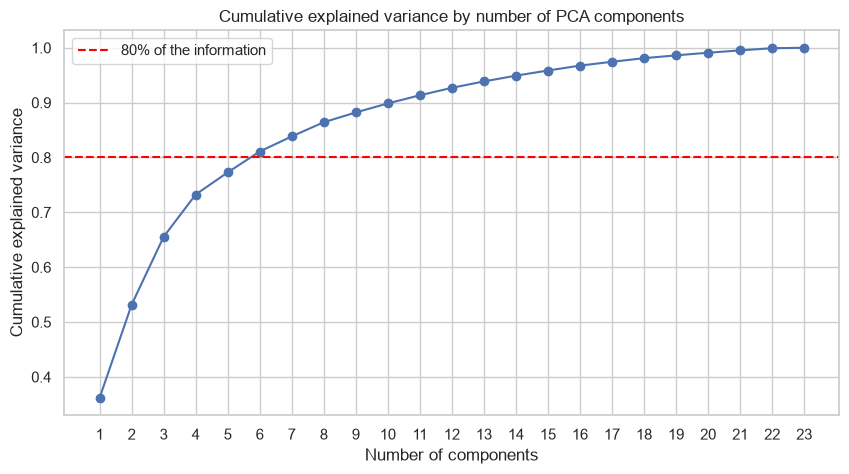

Variance explained by each of the first 6 components: [0.362 0.17  0.124 0.077 0.04  0.038]

From 23 features to 6 components, keeping 81.1% of the information


In [53]:
# DImensionality Reduction (If needed)
from sklearn.decomposition import PCA

# 1. Fit PCA with all components to see how much information each one keeps
pca_full = PCA(random_state=42).fit(X_cluster_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.80, color="red", linestyle="--", label="80% of the information")
plt.title("Cumulative explained variance by number of PCA components")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.xticks(range(1, len(cum_var) + 1))
plt.legend()
plt.show()

print("Variance explained by each of the first 6 components:", pca_full.explained_variance_ratio_[:6].round(3))

# 2. Keep just enough components to explain 80% of the variance
pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_cluster_scaled)
print(f"\nFrom {X_cluster_scaled.shape[1]} features to {X_pca.shape[1]} components, "
      f"keeping {pca.explained_variance_ratio_.sum():.1%} of the information")

Yes, for the clustering. After the encoding, I have 23 features for only 100 restaurants: 4 numerical features and 19 cuisine columns that are mostly zeros. That's a lot of dimensions for so few rows.

Clustering algorithms like K-Means rely on distances, and with too many dimensions the distances between restaurants start to look more and more alike, so it gets harder to find clear groups. This is called the curse of dimensionality. The 19 cuisine columns would also outweigh the 4 numerical features just because there are more of them, so price, rating and engagement would end up counting less than the cuisines.

For the sentiment model, I don't use dimensionality reduction. The TF-IDF matrix is big (5,000 features) but it's sparse, which means mostly zeros, and models like Logistic Regression and Naive Bayes handle that very well. I already controlled the size with max_features and min_df.

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I used PCA (Principal Component Analysis).

PCA combines the original features into new ones called components. Each component is a mix of the original features, and they're sorted from the one that keeps the most information to the one that keeps the least. They're also not correlated with each other, which helps the clustering.

To choose how many components to keep, I plotted the cumulative explained variance. The first component alone keeps 36.2% of the information, the second 17%, and the third 12.4%. After the 6th component, each new one only adds less than 3%, so the curve gets flat. I kept 6 components, which explain 81.1% of the information.

So I went from 23 features down to 6, and I only lost about 19% of the information. The clustering will work on cleaner, more compact data, and it will also be faster.

I chose PCA because my data is numerical after scaling, and PCA is the standard and easiest technique to explain for this kind of data. I applied it after scaling, because PCA is sensitive to the scale of the features.

### 8. Data Splitting

In [54]:
# Split your data to train and test. Choose Splitting ratio wisely.
from sklearn.model_selection import train_test_split

X_text = rev_sent["Final_Review"]
y = rev_sent["Sentiment"]

# 80% train / 20% test, stratified so both sets keep the same positive/negative ratio
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y)

# Fit TF-IDF on the TRAINING reviews only, then apply the same vocabulary to the test reviews
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nPositive share in train:", round(y_train.mean(), 3))
print("Positive share in test :", round(y_test.mean(), 3))

Train: (6939, 5000) | Test: (1735, 5000)

Positive share in train: 0.721
Positive share in test : 0.72


##### What data splitting ratio have you used and why?

I used an 80/20 split: 80% of the reviews for training (6,939 reviews) and 20% for testing (1,735 reviews).

With about 8,700 reviews, 80% gives the model plenty of examples to learn from, and 20% still leaves more than 1,700 reviews to test it, which is enough to get reliable scores. If I kept less for testing, the scores could depend too much on which reviews end up in the test set.

I used stratify on the sentiment label, so both sets keep the same mix of positive and negative reviews. The share of positive reviews is 72.1% in the training set and 72.0% in the test set, so they're basically identical. I also set random_state=42 so I get the same split every time I run the notebook.

One important detail: I fitted the TF-IDF on the training reviews only, and then used it to transform the test reviews. That way, the test reviews stay completely unseen during training, just like new reviews would be in real life, and my scores are honest.

I only split the data for the sentiment model. The clustering is unsupervised, so there's no right answer to test against, and I use all 100 restaurants.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, the sentiment data is imbalanced. About 72% of the reviews are positive and only 28% are negative, so there are around 2.6 positive reviews for each negative one. I already saw it in Chart 1, where the 4 and 5-star ratings clearly dominate.

It's not an extreme imbalance (like 99% vs 1%), but it's enough to cause a problem. A lazy model that predicts "positive" for every single review would already get 72% accuracy without learning anything. And the negative reviews are the most important ones for the business, since they're the unhappy customers Zomato needs to catch. So I need to make sure the model doesn't just ignore them.

In [55]:
# Handling Imbalanced Dataset (If needed)
from sklearn.utils.class_weight import compute_class_weight

print("Training set class counts:\n", y_train.value_counts().rename({1: "Positive (1)", 0: "Negative (0)"}), "\n")

# 'balanced' gives each class a weight inversely proportional to its size
weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
class_weights = dict(zip([0, 1], weights))
print("Class weights:", {k: round(v, 3) for k, v in class_weights.items()})
print("-> A mistake on a negative review will cost about", round(weights[0] / weights[1], 1),
      "times more than a mistake on a positive one.")

Training set class counts:
 Sentiment
Positive (1)    5001
Negative (0)    1938
Name: count, dtype: int64 

Class weights: {0: np.float64(1.79), 1: np.float64(0.694)}
-> A mistake on a negative review will cost about 2.6 times more than a mistake on a positive one.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I used class weights instead of resampling. With class_weight="balanced", the model gives more importance to the minority class during training. In my training set, a negative review gets a weight of about 1.79 and a positive one about 0.69, so a mistake on a negative review costs about 2.6 times more.

I didn't use undersampling, because it would mean throwing away around 3,000 real positive reviews, and that's a lot of useful data lost.

I also didn't use oversampling with SMOTE. SMOTE creates new fake examples by mixing existing ones, which works for normal numbers, but on text TF-IDF vectors it creates "reviews" that don't really make sense. Class weights keep all my real data and don't invent anything, and they're built directly into Logistic Regression with class_weight="balanced".

To check that it works, I won't only look at accuracy, which is misleading with imbalanced classes. I'll focus on the F1-score, recall and the confusion matrix for the negative class.

## ***7. ML Model Implementation***

### ML Model - 1

In [56]:
# ML Model - 1 Implementation
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

kmeans_base = KMeans(n_clusters=3, n_init=10, random_state=42)

# Fit the Algorithm
kmeans_base.fit(X_pca)

# Predict on the model
labels_base = kmeans_base.predict(X_pca)
print("Restaurants per cluster:", pd.Series(labels_base).value_counts().sort_index().to_dict())

Restaurants per cluster: {0: 24, 1: 39, 2: 37}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Silhouette (higher = better)          : 0.187
Davies-Bouldin (lower = better)       : 1.552
Calinski-Harabasz (higher = better)   : 32.664


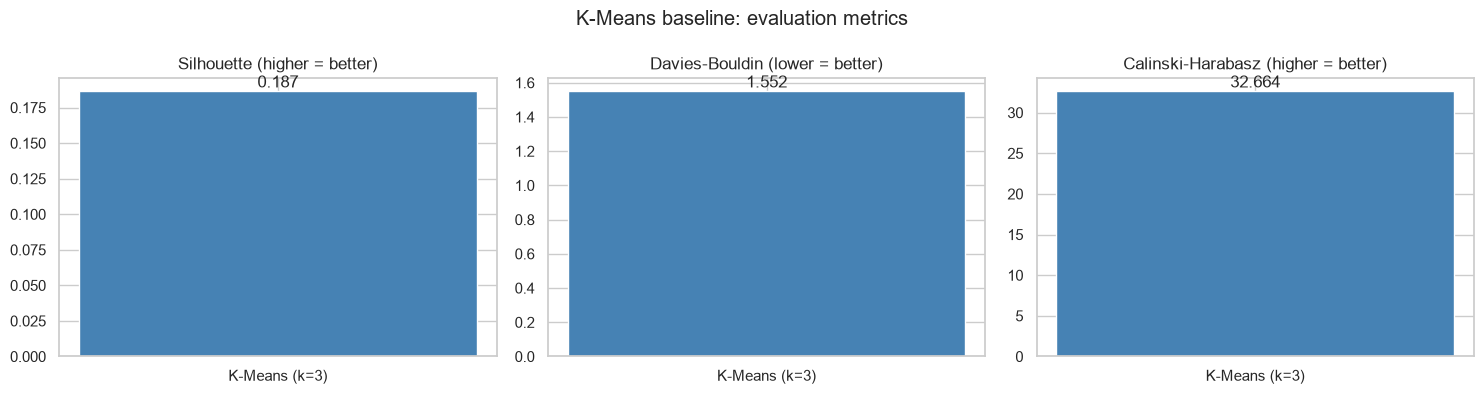

In [57]:
# Visualizing evaluation Metric Score chart
def cluster_scores(X, labels):
    return {"Silhouette (higher = better)": silhouette_score(X, labels),
            "Davies-Bouldin (lower = better)": davies_bouldin_score(X, labels),
            "Calinski-Harabasz (higher = better)": calinski_harabasz_score(X, labels)}

scores_base = cluster_scores(X_pca, labels_base)
for name, value in scores_base.items():
    print(f"{name:38}: {value:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, value) in zip(axes, scores_base.items()):
    ax.bar(["K-Means (k=3)"], [value], color="steelblue")
    ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.set_title(name)
plt.suptitle("K-Means baseline: evaluation metrics")
plt.tight_layout()
plt.show()

For my first model, I used K-Means clustering to group the restaurants into segments. I ran it on the 6 PCA components (which keep 81.1% of the information from my 23 features).

**How K-Means works:** I choose a number of clusters k. The algorithm places k centers, assigns each restaurant to its closest center, then moves each center to the middle of its group. It repeats these two steps until the groups stop changing. I used n_init=10, so it runs 10 times with different starting points and keeps the best result, and random_state=42 so I get the same result every time.

For this first version, I picked k = 3 as a simple starting guess (like budget, mid-range and premium). It gave 3 groups of 24, 39 and 37 restaurants.

**Performance:** since clustering has no "right answer" to compare with, I used three internal metrics:
- **Silhouette score: 0.187.** It goes from -1 to 1 and measures how much closer each restaurant is to its own cluster than to the nearest other cluster. 0.187 is positive, so the restaurants are in the right groups overall, but it's low, so the groups overlap quite a lot.
- **Davies-Bouldin index: 1.552.** It measures how similar each cluster is to its closest neighbour cluster. Lower is better, and 1.55 confirms the clusters aren't very well separated.
- **Calinski-Harabasz index: 32.66.** It compares how far apart the clusters are with how tight they are. Higher is better. It's mostly useful to compare different values of k.

So this first model works, but k = 3 was just a guess. In the next step, I'll test different values of k to find the best number of clusters.

#### 2. Cross- Validation & Hyperparameter Tuning

,Inertia,Silhouette (higher = better),Davies-Bouldin (lower = better),Calinski-Harabasz (higher = better)
k,,,,
2,341.324,0.256,1.415,42.581
3,292.583,0.187,1.552,32.664
4,250.837,0.196,1.474,30.464
5,217.110,0.228,1.265,29.812
6,192.175,0.223,1.333,29.099
7,180.265,0.211,1.279,26.601
8,166.034,0.210,1.271,25.615
9,155.809,0.200,1.286,24.371
10,142.850,0.219,1.179,24.276


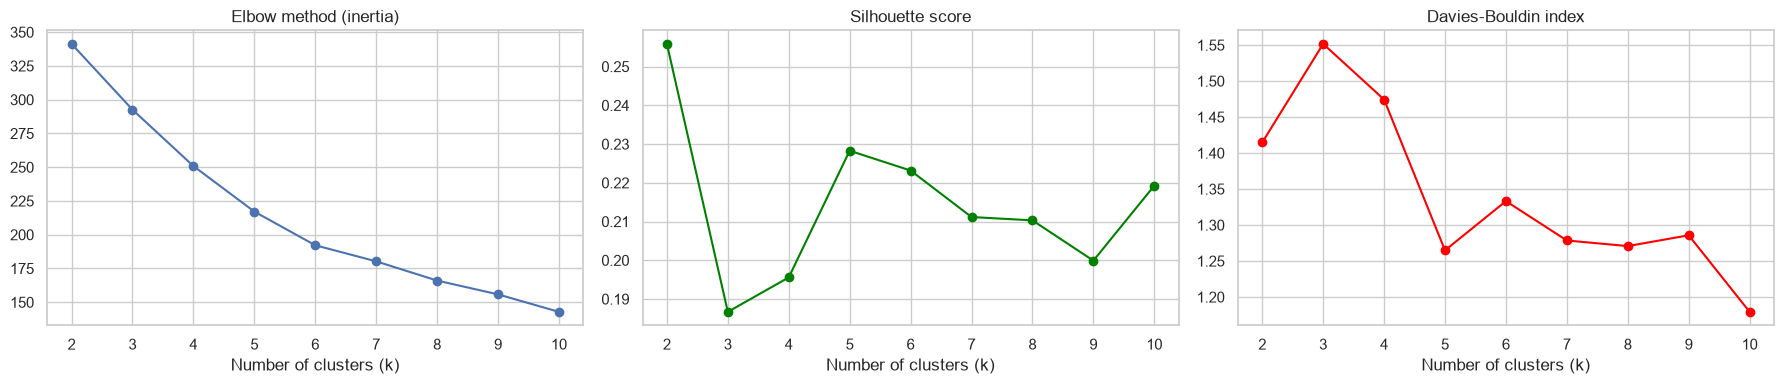

In [58]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Clustering has no labels, so GridSearchCV can't score it. Instead I search over k myself
# and score each value with the elbow method and the 3 clustering metrics.

results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    results.append({"k": k, "Inertia": km.inertia_, **cluster_scores(X_pca, km.labels_)})
results = pd.DataFrame(results).set_index("k")
display(results.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
results["Inertia"].plot(marker="o", ax=axes[0], title="Elbow method (inertia)")
results["Silhouette (higher = better)"].plot(marker="o", ax=axes[1], color="green", title="Silhouette score")
results["Davies-Bouldin (lower = better)"].plot(marker="o", ax=axes[2], color="red", title="Davies-Bouldin index")
for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(range(2, 11))
plt.tight_layout()
plt.show()

,K-Means k=3 (baseline),K-Means k=5 (tuned)
Silhouette (higher = better),0.187,0.228
Davies-Bouldin (lower = better),1.552,1.265
Calinski-Harabasz (higher = better),32.664,29.812


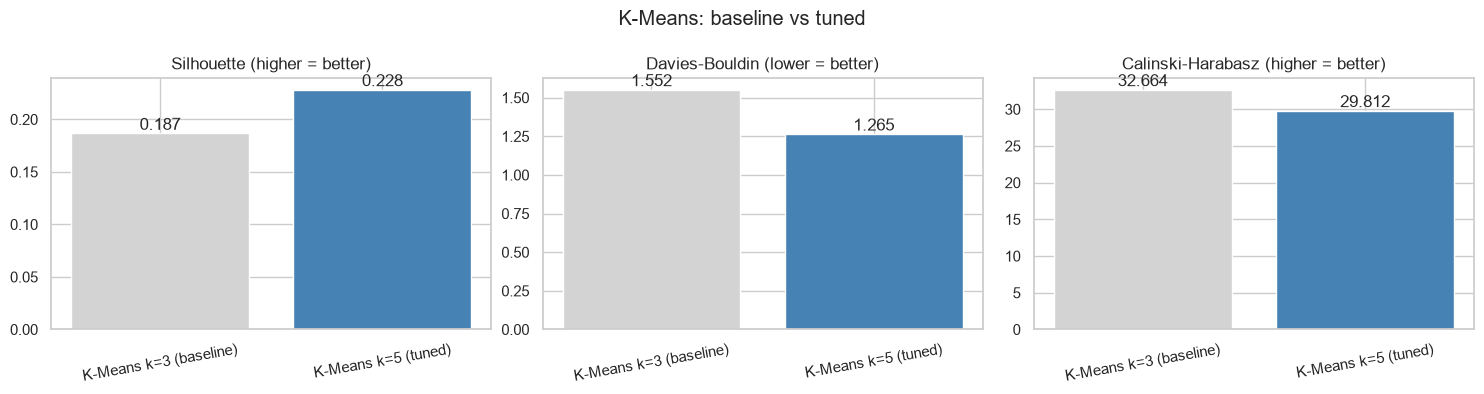

,Restaurants,Median_Cost,Avg_Rating,Avg_Review_Length,Avg_Num_Cuisines
KMeans_Cluster,,,,,
0,18,700.0,3.70,71.19,2.17
1,32,450.0,3.33,27.84,2.16
2,7,1500.0,4.69,42.09,2.71
3,25,800.0,3.34,49.36,3.84
4,18,1500.0,3.93,73.85,4.33


Cluster 0 | top cuisines: ['North Indian', 'Continental', 'Fast Food', 'Cafe']
   examples: ['NorFest - The Dhaba', 'Tiki Shack', 'Marsala Food Company', 'Club Rogue', 'Deli 9 Bistro']
Cluster 1 | top cuisines: ['North Indian', 'Chinese', 'Desserts', 'Fast Food']
   examples: ['Shah Ghouse Spl Shawarma', 'Cream Stone', "Sardarji's Chaats & More", 'KFC', 'Hotel Zara Hi-Fi']
Cluster 2 | top cuisines: ['North Indian', 'Asian', 'Mediterranean', 'European']
   examples: ['Paradise', 'Flechazo', "AB's - Absolute Barbecues", 'B-Dubs', "3B's - Buddies, Bar & Barbecue"]
Cluster 3 | top cuisines: ['North Indian', 'Chinese', 'Biryani', 'Andhra']
   examples: ['Shah Ghouse Hotel & Restaurant', 'eat.fit', 'Absolute Sizzlers', 'The Lal Street - Bar Exchange', 'SKYHY']
Cluster 4 | top cuisines: ['North Indian', 'Continental', 'Italian', 'Chinese']
   examples: ['Beyond Flavours', 'Over The Moon Brew Company', "The Fisherman's Wharf", 'Hyper Local', 'Barbeque Nation']


In [59]:
# Final K-Means model with the best k
best_k = 5
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)

# Fit the Algorithm
kmeans.fit(X_pca)

# Predict on the model
df_model["KMeans_Cluster"] = kmeans.predict(X_pca)
scores_tuned = cluster_scores(X_pca, df_model["KMeans_Cluster"])

# Compare baseline (k=3) and tuned (k=5)
comparison = pd.DataFrame({"K-Means k=3 (baseline)": scores_base, f"K-Means k={best_k} (tuned)": scores_tuned})
display(comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, comparison.index):
    ax.bar(comparison.columns, comparison.loc[metric], color=["lightgray", "steelblue"])
    ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=10)
plt.suptitle("K-Means: baseline vs tuned")
plt.tight_layout()
plt.show()

# What does each cluster look like? (using the original, unscaled values)
profile = df_model.groupby("KMeans_Cluster").agg(
    Restaurants=("Name", "count"),
    Median_Cost=("Cost", "median"),
    Avg_Rating=("Avg_Rating", "mean"),
    Avg_Review_Length=("Avg_Review_Length", "mean"),
    Avg_Num_Cuisines=("Num_Cuisines", "mean"),
).round(2)
display(profile)

# Top cuisines and a few example restaurants in each cluster
for c in range(best_k):
    members = df_model[df_model["KMeans_Cluster"] == c]
    top_cuisines = members["Cuisines_List"].explode().value_counts().head(4).index.tolist()
    print(f"Cluster {c} | top cuisines: {top_cuisines}")
    print("   examples:", members["Name"].head(5).tolist())

#### Visualizing the clusters

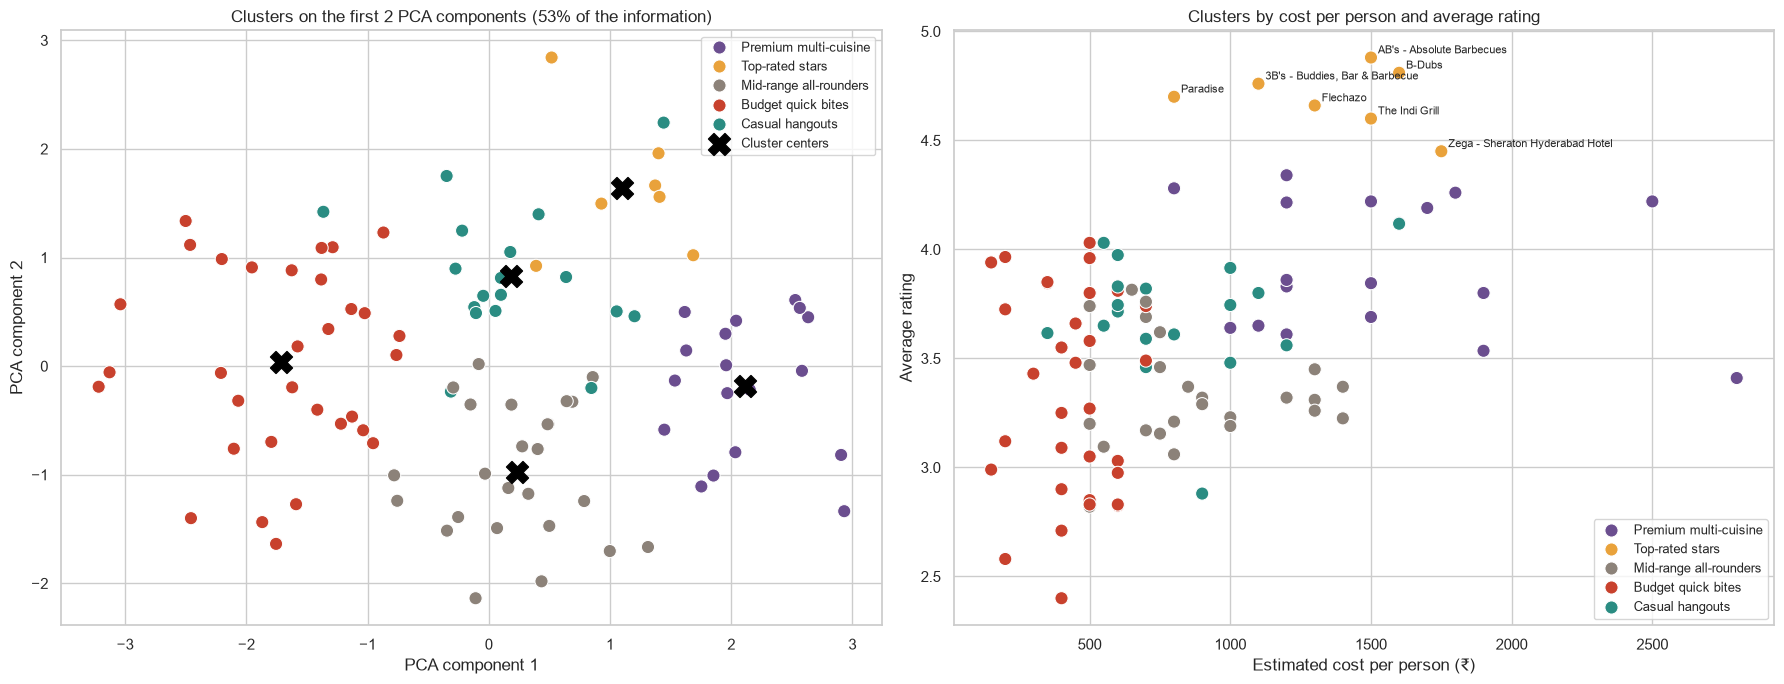

In [60]:
# Visualizing the clusters
segment_names = {0: "Casual hangouts", 1: "Budget quick bites", 2: "Top-rated stars",
                 3: "Mid-range all-rounders", 4: "Premium multi-cuisine"}
df_model["Segment"] = df_model["KMeans_Cluster"].map(segment_names)
palette = {"Casual hangouts": "#2A8C82", "Budget quick bites": "#C8412D", "Top-rated stars": "#E9A23B",
           "Mid-range all-rounders": "#8C8279", "Premium multi-cuisine": "#6B4E8F"}

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: the clusters in the space the model actually used (first 2 PCA components)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_model["Segment"], palette=palette, s=90, ax=axes[0])
centers = kmeans.cluster_centers_
axes[0].scatter(centers[:, 0], centers[:, 1], marker="X", s=250, c="black", label="Cluster centers")
axes[0].set_title(f"Clusters on the first 2 PCA components "
                  f"({pca.explained_variance_ratio_[:2].sum():.0%} of the information)")
axes[0].set_xlabel("PCA component 1")
axes[0].set_ylabel("PCA component 2")
axes[0].legend(loc="best", fontsize=9)

# Right: the same clusters on real, easy-to-read features
sns.scatterplot(x="Cost", y="Avg_Rating", hue="Segment", data=df_model, palette=palette, s=90, ax=axes[1])
for _, row in df_model[df_model["KMeans_Cluster"] == 2].iterrows():   # label the top-rated stars
    axes[1].annotate(row["Name"], (row["Cost"], row["Avg_Rating"]), fontsize=8,
                     xytext=(5, 3), textcoords="offset points")
axes[1].set_title("Clusters by cost per person and average rating")
axes[1].set_xlabel("Estimated cost per person (₹)")
axes[1].set_ylabel("Average rating")
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

**What the cluster visualization shows**

On the left, I plotted the restaurants on the first 2 PCA components, which is how the model actually sees them (these 2 components hold 53% of the information), with the black X marks as the cluster centers. The segments are clearly separated: the budget quick bites on the left, the premium multi-cuisine places on the right, the top-rated stars at the top and the mid-range all-rounders at the bottom. The casual hangouts sit in the middle and overlap a bit with their neighbours, which is expected since this flat view only shows 2 of the 6 components the model used.

On the right, I plotted the same segments on cost per person and average rating, which is easier to read for the business:
- The **top-rated stars** are all above 4.45, and they're not all expensive: Paradise is the cheapest of them at ₹800 per person.
- The **budget quick bites** fill the bottom left: cheap places with the widest range of ratings, from 2.4 up to about 4.0. A few of them are still rated around 4, so good budget options do exist.
- The **premium multi-cuisine** places cost the most (₹800 to ₹2,800) and are rated between 3.4 and 4.35, so paying more doesn't guarantee the very best experience.
- The **mid-range all-rounders** are stuck between 2.8 and 3.8 whatever their price, so serving a bit of everything doesn't make customers happier.
- The **casual hangouts** sit in the middle, mostly between ₹350 and ₹1,500 with ratings around 3.5 to 4.1.

This confirms the 5 segments are not random: each one has its own clear position on price and quality.

##### Which hyperparameter optimization technique have you used and why?

The main hyperparameter of K-Means is k, the number of clusters. I couldn't use GridSearchCV or RandomizedSearchCV, because they need labels to score each model, and clustering is unsupervised: there's no right answer to compare with.

So I did my own grid search: I trained K-Means for every k from 2 to 10 and scored each one with the elbow method (inertia) and the three clustering metrics (Silhouette, Davies-Bouldin and Calinski-Harabasz). Then I picked k by looking at all of them together and at what makes sense for the business:
- k = 2 had the best silhouette (0.256), but 2 clusters would only split the restaurants into "cheap" and "expensive", which is too broad to be useful.
- k = 5 is the second peak of the silhouette (0.228), it has the lowest Davies-Bouldin of all k from 2 to 9 (1.265), and the elbow curve starts to flatten around 5.
- k = 10 had a slightly lower Davies-Bouldin, but 10 groups for 100 restaurants means around 10 restaurants each, which is too fragmented.

So I chose k = 5. I kept n_init=10 (10 runs with different starting points) and random_state=42 so the result is stable and reproducible.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. Going from k = 3 (my first guess) to k = 5 improved the clustering:
- **Silhouette score:** from 0.187 to 0.228, so +22%. The restaurants are more clearly in the right group.
- **Davies-Bouldin index:** from 1.552 to 1.265, so 18% lower, which means the clusters overlap less.
- **Calinski-Harabasz index:** went down from 32.66 to 29.81. That's expected, because this score naturally decreases when there are more clusters, so it's mainly useful to compare models with the same k.

The silhouette is still moderate, because restaurants don't fall into perfectly separate boxes (a mid-range place can be close to both a budget and a premium one). But the 5 clusters make a lot of sense when I look at them:

- **Cluster 0, Casual hangouts (18 restaurants):** about ₹700, a good rating (3.70) and the most engaged reviews. Cafes, pubs and bistros like Tiki Shack, Club Rogue and Deli 9 Bistro.
- **Cluster 1, Budget quick bites (32 restaurants):** about ₹450, the lowest rating (3.33) and the shortest reviews. Fast food, desserts and quick meals like KFC, Cream Stone and Shah Ghouse Spl Shawarma.
- **Cluster 2, Top-rated stars (7 restaurants):** about ₹1,500 and by far the best rating (4.69). AB's, B-Dubs, 3B's, Flechazo and Paradise.
- **Cluster 3, Mid-range all-rounders (25 restaurants):** about ₹800, a low rating (3.34) and the most cuisines on the menu. A lot of North Indian, Chinese, Biryani and Andhra.
- **Cluster 4, Premium multi-cuisine dining (18 restaurants):** about ₹1,500, a good rating (3.93), long reviews and more than 4 cuisines. Places like Beyond Flavours, Barbeque Nation and The Fisherman's Wharf.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

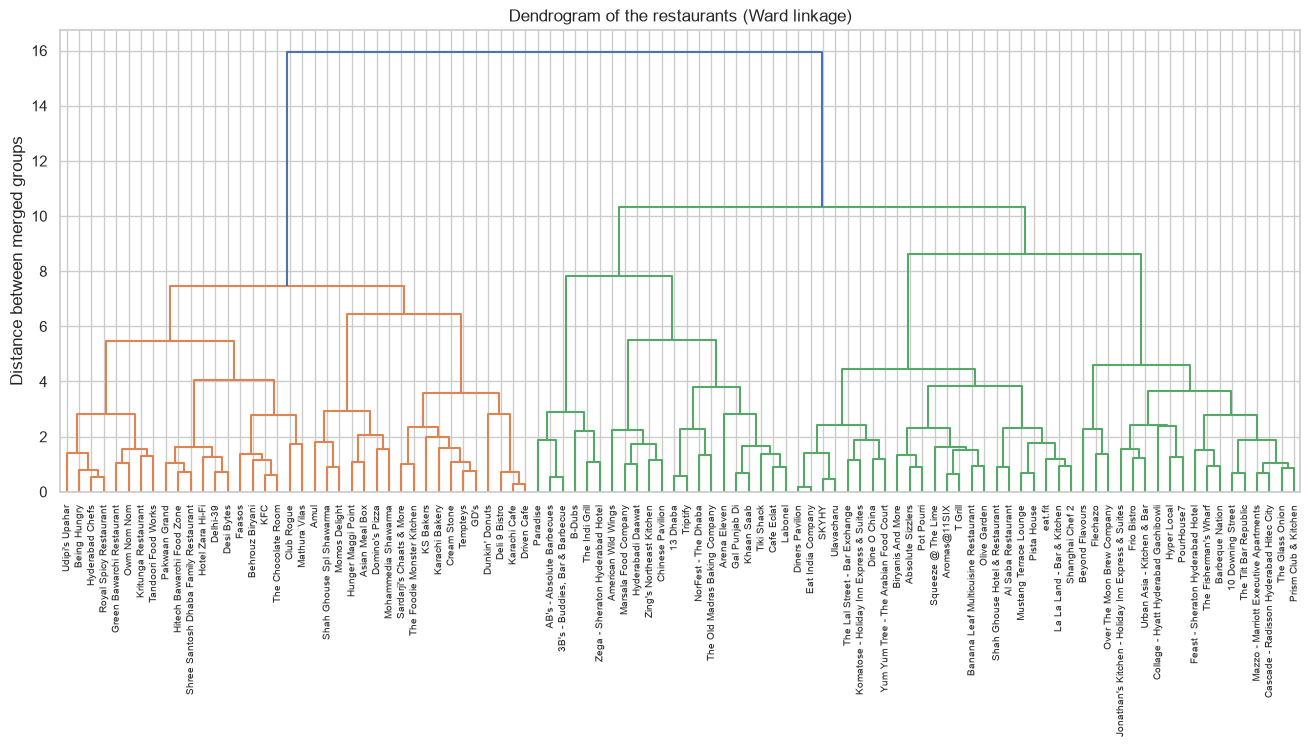

Restaurants per cluster: {0: 38, 1: 15, 2: 18, 3: 23, 4: 6}


In [61]:
# ML Model - 2 Implementation
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Dendrogram: shows how restaurants get merged step by step
plt.figure(figsize=(16, 6))
dendrogram(linkage(X_pca, method="ward"), labels=df_model["Name"].values, leaf_font_size=7, color_threshold=None)
plt.title("Dendrogram of the restaurants (Ward linkage)")
plt.ylabel("Distance between merged groups")
plt.show()

# 2. Fit the Algorithm: same k as K-Means so the two models are compared fairly
hc_base = AgglomerativeClustering(n_clusters=5, linkage="ward")

# 3. Predict on the model
labels_hc_base = hc_base.fit_predict(X_pca)
print("Restaurants per cluster:", pd.Series(labels_hc_base).value_counts().sort_index().to_dict())

,K-Means k=5,"Hierarchical (ward, k=5)"
Silhouette (higher = better),0.228,0.183
Davies-Bouldin (lower = better),1.265,1.375
Calinski-Harabasz (higher = better),29.812,24.485


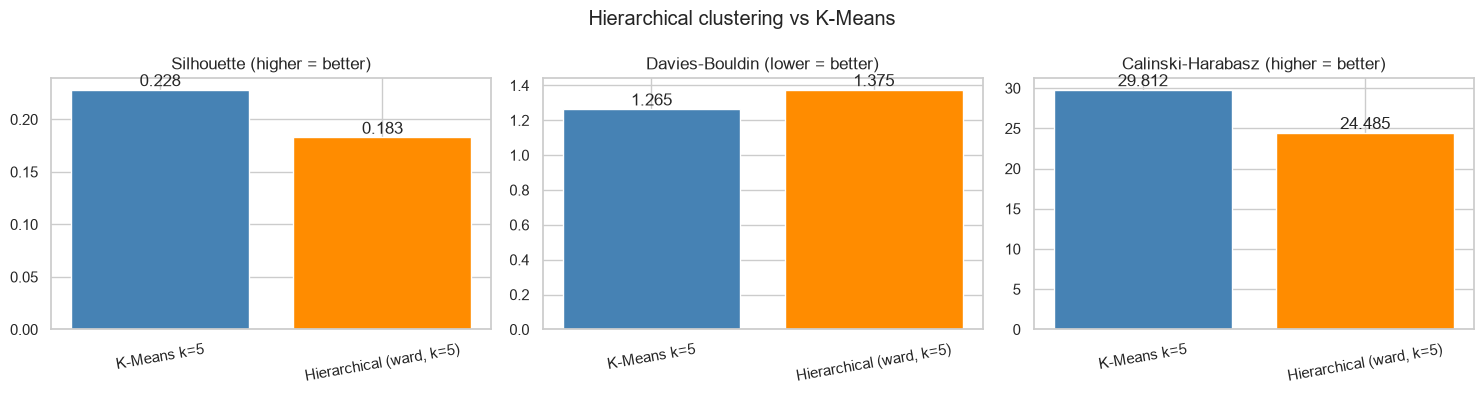

In [62]:
# Visualizing evaluation Metric Score chart
scores_hc_base = cluster_scores(X_pca, labels_hc_base)
compare_m2 = pd.DataFrame({"K-Means k=5": scores_tuned, "Hierarchical (ward, k=5)": scores_hc_base})
display(compare_m2.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, compare_m2.index):
    ax.bar(compare_m2.columns, compare_m2.loc[metric], color=["steelblue", "darkorange"])
    ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=10)
plt.suptitle("Hierarchical clustering vs K-Means")
plt.tight_layout()
plt.show()

For my second model, I used Agglomerative Hierarchical Clustering on the same 6 PCA components, to compare it with K-Means.

**How it works:** it's a bottom-up approach. It starts with each restaurant as its own cluster, then it keeps merging the two closest clusters, step by step, until all the restaurants are in one big group. The dendrogram shows this whole merging history like a family tree, and cutting the tree at a certain height gives the clusters. I used Ward linkage, which merges the two clusters that increase the spread inside the clusters the least, so it creates compact groups (it's the closest to how K-Means thinks). For this first version, I used k = 5, the same as my final K-Means, so I can compare them fairly.

**What the dendrogram shows:** the biggest split separates the restaurants into two families. On one side, the budget and quick-food places (Udipi's Upahar, KFC, Domino's, Behrouz Biryani, Cream Stone...). On the other side, the mid-range and premium places. A small group branches off on its own early: AB's, 3B's, B-Dubs, The Indi Grill and Paradise, almost exactly the "Top-rated stars" cluster that K-Means found. The hotel restaurants (Hyatt, Sheraton, Radisson, Marriott) also end up together. So both models see the same overall structure.

**Performance compared with K-Means (k = 5):**
- **Silhouette:** 0.183 vs 0.228 for K-Means.
- **Davies-Bouldin:** 1.375 vs 1.265 for K-Means (lower is better).
- **Calinski-Harabasz:** 24.49 vs 29.81 for K-Means.

With the same number of clusters, hierarchical clustering is a bit weaker than K-Means on all three metrics. That makes sense: once hierarchical clustering merges two restaurants, it can never separate them again, while K-Means keeps moving restaurants between clusters until it finds the best arrangement.

#### 2. Cross- Validation & Hyperparameter Tuning

,linkage,k,smallest_cluster,Silhouette (higher = better),Davies-Bouldin (lower = better),Calinski-Harabasz (higher = better)
0,ward,3,21,0.194,1.708,28.356
1,ward,4,18,0.162,1.519,25.645
2,ward,5,6,0.183,1.375,24.485
3,ward,6,6,0.194,1.457,24.363
4,ward,7,6,0.205,1.334,23.910
5,ward,8,5,0.216,1.260,23.128
6,complete,3,23,0.108,2.473,20.051
7,complete,4,13,0.133,1.838,22.908
8,complete,5,8,0.170,1.521,24.117
9,complete,6,8,0.146,1.546,21.829



Best combination: linkage = ward, k = 8


,Hierarchical ward k=5 (baseline),Hierarchical ward k=8 (tuned),K-Means k=5 (tuned)
Silhouette (higher = better),0.183,0.216,0.228
Davies-Bouldin (lower = better),1.375,1.260,1.265
Calinski-Harabasz (higher = better),24.485,23.128,29.812


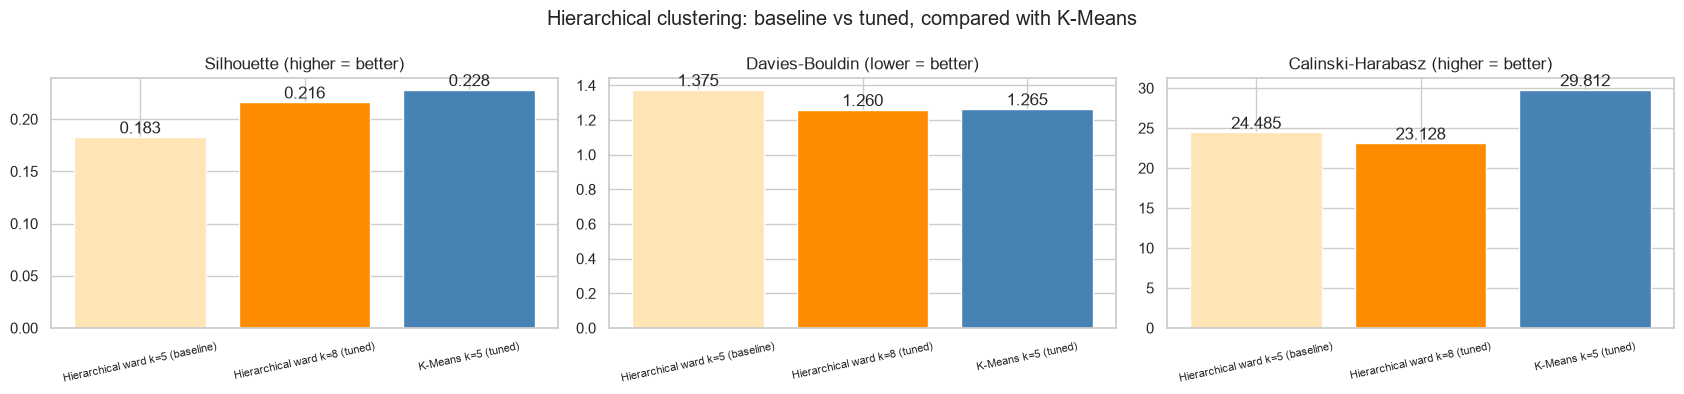

In [63]:
# ML Model - 2 Implementation with hyperparameter optimization techniques
# Grid search over 2 hyperparameters: the linkage method and the number of clusters

hc_results = []
for link in ["ward", "complete", "average"]:
    for k in range(3, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_pca)
        sizes = np.bincount(labels)
        hc_results.append({"linkage": link, "k": k, "smallest_cluster": sizes.min(),
                           **cluster_scores(X_pca, labels)})
hc_results = pd.DataFrame(hc_results)
display(hc_results.round(3))

# Keep only solutions where every cluster has at least 5 restaurants (no useless 1-restaurant clusters),
# then pick the one with the best silhouette
valid = hc_results[hc_results["smallest_cluster"] >= 5]
best = valid.sort_values("Silhouette (higher = better)", ascending=False).iloc[0]
print(f"\nBest combination: linkage = {best['linkage']}, k = {best['k']}")

# Fit the Algorithm with the best hyperparameters
hc = AgglomerativeClustering(n_clusters=int(best["k"]), linkage=best["linkage"])

# Predict on the model
df_model["HC_Cluster"] = hc.fit_predict(X_pca)
scores_hc_tuned = cluster_scores(X_pca, df_model["HC_Cluster"])

# Compare: baseline hierarchical, tuned hierarchical, and the final K-Means
compare_all = pd.DataFrame({"Hierarchical ward k=5 (baseline)": scores_hc_base,
                            f"Hierarchical {best['linkage']} k={best['k']} (tuned)": scores_hc_tuned,
                            "K-Means k=5 (tuned)": scores_tuned})
display(compare_all.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, metric in zip(axes, compare_all.index):
    ax.bar(compare_all.columns, compare_all.loc[metric], color=["moccasin", "darkorange", "steelblue"])
    ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=12, labelsize=8)
plt.suptitle("Hierarchical clustering: baseline vs tuned, compared with K-Means")
plt.tight_layout()
plt.show()

##### Which hyperparameter optimization technique have you used and why?

I used a grid search over two hyperparameters of hierarchical clustering:
- **linkage:** how the distance between two clusters is measured. I tested ward (merges the clusters that stay the most compact), complete (uses the two farthest restaurants between two clusters) and average (uses the average distance between all their restaurants).
- **number of clusters (k):** from 3 to 8.

That's 18 combinations. Like with K-Means, I couldn't use GridSearchCV, because it needs labels to score each model, and clustering is unsupervised. So I looped over all the combinations myself and scored each one with the Silhouette, Davies-Bouldin and Calinski-Harabasz metrics.

I added one important rule: every cluster must have at least 5 restaurants. When I looked at the results, all the "average" linkage solutions had a cluster with only 1 restaurant. They can score okay on paper, but a "cluster" with a single restaurant is useless for the business. Among the valid combinations, I picked the one with the best silhouette score, which was Ward linkage with k = 8.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, the tuning improved hierarchical clustering:
- **Silhouette:** from 0.183 (ward, k=5) to 0.216 (ward, k=8), so +18%.
- **Davies-Bouldin:** from 1.375 to 1.260, so the clusters overlap less.
- **Calinski-Harabasz:** went down a little, from 24.49 to 23.13, which is normal when the number of clusters goes up.

But even after tuning, hierarchical clustering doesn't beat K-Means. K-Means with k = 5 still has a better silhouette (0.228 vs 0.216) and a much better Calinski-Harabasz (29.81 vs 23.13), and the Davies-Bouldin is almost the same (1.265 vs 1.260). On top of that, K-Means gets these results with only 5 clusters instead of 8, so its segments are bigger and easier to use for the business. Ward linkage was also clearly the best linkage, which makes sense because it builds compact groups, just like K-Means.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

**What each metric means for the business:**
- **Silhouette score:** it tells me how clearly each restaurant belongs to its segment. A higher score means the segments are more distinct, so if Zomato builds a marketing campaign or a recommendation for one segment, it really fits the restaurants in it. A low score means some restaurants sit between two segments and could be treated the wrong way.
- **Davies-Bouldin index:** it tells me how much the segments overlap. Lower means the segments are well separated, so Zomato can give each one a different strategy (pricing, promotions, quality follow-up) without mixing them up.
- **Calinski-Harabasz index:** it compares how different the segments are from each other with how similar the restaurants are inside each segment. A higher score means each segment is consistent inside, so the decisions made for a segment apply well to all of its restaurants.

**Business impact of the clustering:**
Instead of handling 100 restaurants one by one, Zomato gets a few clear restaurant types it can manage with different strategies:
- It can promote the top-rated restaurants more in the app and in collections.
- It can focus quality support on the budget and mid-range segments, where the ratings are the lowest and where most of the order volume is.
- It can recommend similar restaurants to customers (if you liked a place in one segment, here are others like it).
- It can spot gaps in the market, like the lack of good-quality restaurants in the budget range.

Both models found the same main structure, which makes me more confident the segments are real and not just random. In the end, I'll keep K-Means as my final clustering model, since it has the best scores with fewer, more useful segments.

### ML Model - 3

In [64]:
# ML Model - 3 Implementation
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

# class_weight="balanced" applies the weights from the imbalance step (negative reviews count more)
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

# Fit the Algorithm
log_reg.fit(X_train, y_train)

# Predict on the model
y_pred_lr = log_reg.predict(X_test)
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]   # probability of being positive, needed for ROC-AUC

print(classification_report(y_test, y_pred_lr, target_names=["Negative (0)", "Positive (1)"]))

              precision    recall  f1-score   support

Negative (0)       0.90      0.97      0.93       485
Positive (1)       0.99      0.96      0.97      1250

    accuracy                           0.96      1735
   macro avg       0.94      0.96      0.95      1735
weighted avg       0.96      0.96      0.96      1735



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

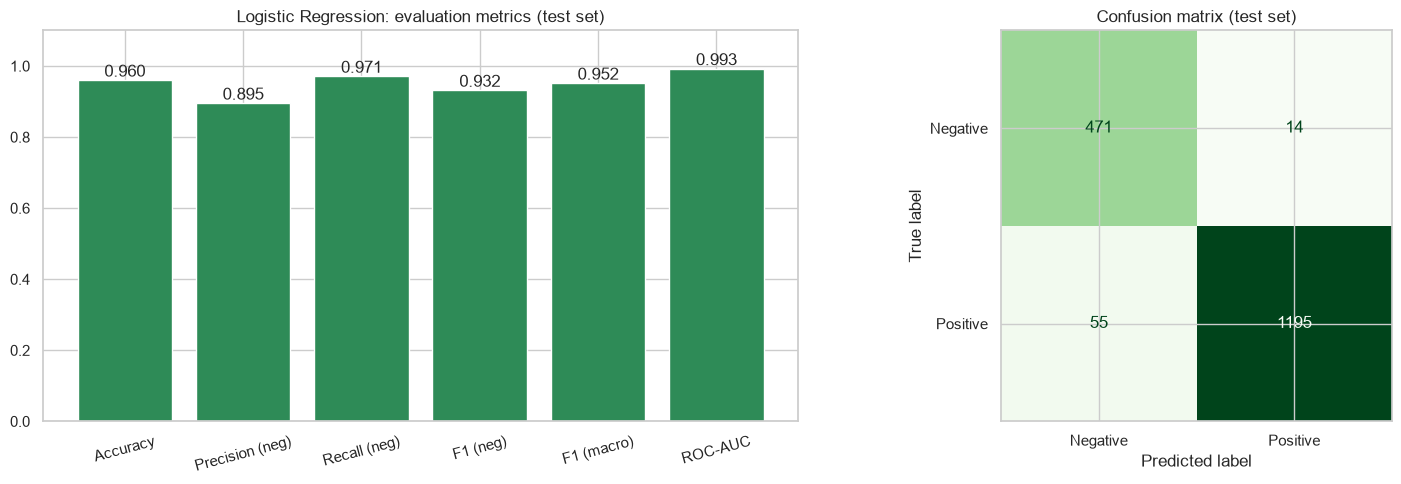

In [65]:
# Visualizing evaluation Metric Score chart
def classification_scores(y_true, y_pred, y_proba):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision (neg)": precision_score(y_true, y_pred, pos_label=0),
            "Recall (neg)": recall_score(y_true, y_pred, pos_label=0),
            "F1 (neg)": f1_score(y_true, y_pred, pos_label=0),
            "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
            "ROC-AUC": roc_auc_score(y_true, y_proba)}

scores_lr = classification_scores(y_test, y_pred_lr, y_proba_lr)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: metric bars
axes[0].bar(scores_lr.keys(), scores_lr.values(), color="seagreen")
axes[0].bar_label(axes[0].containers[0], fmt="%.3f")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Logistic Regression: evaluation metrics (test set)")
axes[0].tick_params(axis="x", rotation=15)

# Right: confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=["Negative", "Positive"],
                                        cmap="Greens", ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix (test set)")

plt.tight_layout()
plt.show()

For my third model, I used Logistic Regression to classify the reviews as positive or negative, using the TF-IDF features (5,000 words and word pairs).

**How it works:** the model learns a weight for each word. Words like "delicious" or "awesome" get a positive weight and push the review towards positive, and words like "worst", "pathetic" or "not good" get a negative weight. For each review, it adds up the weights of its words and turns the total into a probability between 0 and 1. If the probability is above 0.5, the review is predicted positive. I used class_weight="balanced" so the model pays more attention to the negative reviews, since they're the minority class (28%). I chose Logistic Regression because it works really well on TF-IDF text data, it's fast, and I can read the weights to see which words matter, which makes it easy to explain.

**Performance on the test set (1,735 reviews it never saw during training):**
- **Accuracy: 96.0%.** That's way above the 72% a lazy model would get by predicting "positive" every time.
- **Recall on negative reviews: 97.1%.** Out of 485 negative reviews, the model caught 471 and missed only 14. That's the most important metric for me, because the negative reviews are the unhappy customers Zomato needs to catch.
- **Precision on negative reviews: 89.5%.** When the model says a review is negative, it's right about 9 times out of 10. It flagged 55 positive reviews as negative by mistake.
- **F1 on negative reviews: 0.932**, and **macro F1: 0.952**, so the model is good on both classes, not only the big one.
- **ROC-AUC: 0.993.** The model is almost perfect at ranking negative reviews below positive ones.

The confusion matrix shows the model makes more mistakes on positive reviews (55) than on negative ones (14). That's the effect of the class weights: I told the model a missed negative review costs more, so it prefers to flag a few extra reviews rather than miss an unhappy customer. For Zomato, that's the right trade-off.

#### 2. Cross- Validation & Hyperparameter Tuning

Baseline 5-fold CV macro F1: 0.9384
Best C: 5 | Best 5-fold CV macro F1: 0.9416
CV macro F1 for each C: {0.01: np.float64(0.8947), 0.1: np.float64(0.9182), 0.5: np.float64(0.9348), 1: np.float64(0.9384), 2: np.float64(0.9408), 5: np.float64(0.9416), 10: np.float64(0.9408), 20: np.float64(0.94)}


,Baseline (C=1),Tuned (C=5)
Accuracy,0.9602,0.9620
Precision (neg),0.8954,0.9068
Recall (neg),0.9711,0.9629
F1 (neg),0.9318,0.9340
F1 (macro),0.9518,0.9536
ROC-AUC,0.9925,0.9931


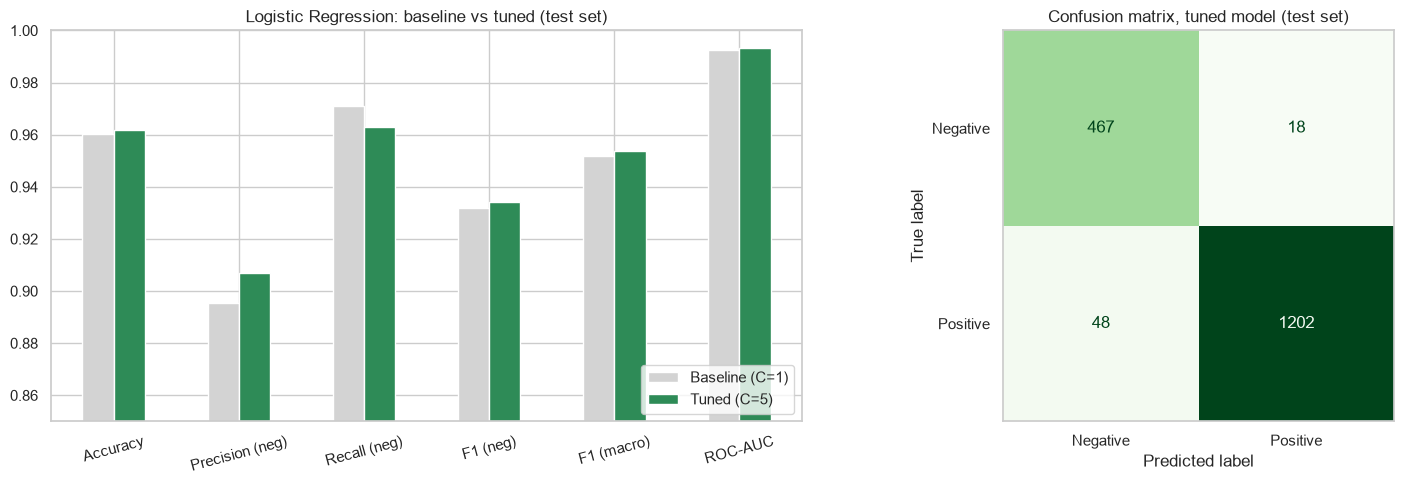

In [66]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cross-validation score of the baseline model, for comparison
cv_base = cross_val_score(log_reg, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"Baseline 5-fold CV macro F1: {cv_base.mean():.4f}")

# Grid search over C (the regularization strength)
param_grid = {"C": [0.01, 0.1, 0.5, 1, 2, 5, 10, 20]}
grid = GridSearchCV(LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
                    param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)

# Fit the Algorithm
grid.fit(X_train, y_train)
print(f"Best C: {grid.best_params_['C']} | Best 5-fold CV macro F1: {grid.best_score_:.4f}")
print("CV macro F1 for each C:",
      dict(zip(param_grid["C"], grid.cv_results_["mean_test_score"].round(4))))

# Predict on the model
log_reg_tuned = grid.best_estimator_
y_pred_lr_t = log_reg_tuned.predict(X_test)
y_proba_lr_t = log_reg_tuned.predict_proba(X_test)[:, 1]
scores_lr_tuned = classification_scores(y_test, y_pred_lr_t, y_proba_lr_t)

# Compare baseline vs tuned on the test set
compare_lr = pd.DataFrame({"Baseline (C=1)": scores_lr, f"Tuned (C={grid.best_params_['C']})": scores_lr_tuned})
display(compare_lr.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
compare_lr.plot(kind="bar", ax=axes[0], color=["lightgray", "seagreen"], rot=15)
axes[0].set_ylim(0.85, 1.0)
axes[0].set_title("Logistic Regression: baseline vs tuned (test set)")
axes[0].legend(loc="lower right")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_t, display_labels=["Negative", "Positive"],
                                        cmap="Greens", ax=axes[1], colorbar=False)
axes[1].grid(False)
axes[1].set_title("Confusion matrix, tuned model (test set)")
plt.tight_layout()
plt.show()

# Predict on the model

##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 5-fold Stratified Cross-Validation, tuning the C parameter of Logistic Regression.

C controls how strict the model is (regularization). A small C keeps the word weights small, so the model stays simple but can miss details. A big C lets the model follow the training data very closely, but it can start memorizing it instead of learning general patterns. I tested 8 values: 0.01, 0.1, 0.5, 1, 2, 5, 10 and 20.

I chose Grid Search because there's only one main parameter to tune and a small number of values, so testing every combination is fast and guarantees I find the best one in the grid. Random Search or Bayesian Optimization are more useful when there are a lot of parameters and testing everything would take too long.

For each value, the cross-validation splits the training set into 5 parts, trains on 4 and tests on the 5th, 5 times. I used Stratified folds so each part keeps the same 72/28 mix of positive and negative reviews. I scored with the macro F1, because it gives the same importance to both classes, so the model can't look good just by being right on the positive majority. The test set stayed untouched during all of this, I only used it at the end to check the final model.

The best value was C = 5, with a cross-validation macro F1 of 0.9416. The scores went up from C = 0.01 (0.8947) to C = 5, then started to drop slightly at 10 and 20, so C = 5 is the right balance.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, but it's a small improvement, because the baseline model was already very good.

- **Cross-validation macro F1:** from 0.9384 to 0.9416.
- **On the test set:**
  - Accuracy: 0.9602 to 0.9620
  - Precision (negative): 0.8954 to 0.9068
  - F1 (negative): 0.9318 to 0.9340
  - Macro F1: 0.9518 to 0.9536
  - ROC-AUC: 0.9925 to 0.9931
  - Recall (negative): 0.9711 to 0.9629, so this one went down slightly.

Looking at the confusion matrix, the tuned model makes fewer false alarms (48 positive reviews flagged as negative instead of 55), but it misses a few more negative reviews (18 instead of 14). So it's a trade-off: the tuned model is more precise, and the baseline catches slightly more unhappy customers. Overall, the tuned model is better balanced, which is why the F1 scores improved.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**For the sentiment model**, I focused on the metrics for the negative class and on the macro F1, not on accuracy:
- **Recall on negative reviews** is the most important one for me. Each negative review is an unhappy customer. If the model misses one, Zomato doesn't react, the problem doesn't get fixed and the customer may never come back. A high recall means almost no unhappy customer slips through.
- **Precision on negative reviews** matters too. Each false alarm means time wasted by the support team or a restaurant being flagged for nothing. Precision keeps that under control.
- **F1 score** balances the two, and the **macro F1** gives the same weight to the positive and negative classes. Since 72% of the reviews are positive, accuracy alone would be misleading: a useless model predicting "positive" every time would already get 72%.
- **ROC-AUC** shows how well the model ranks reviews from most negative to most positive. That's useful if Zomato wants to sort reviews by urgency instead of just using a yes/no answer.

**For the clustering**, I used the Silhouette score, Davies-Bouldin index and Calinski-Harabasz index. Together they tell me if the segments are clearly separated and consistent inside, which means Zomato can trust that a strategy built for one segment really fits the restaurants in it.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I'm keeping two final models, one for each part of the project:

**For the restaurant segmentation: K-Means with k = 5.**
It had the best scores of all my clustering models: a silhouette of 0.228, a Davies-Bouldin of 1.265 and a Calinski-Harabasz of 29.81. The tuned hierarchical clustering came close on two metrics, but it needed 8 clusters to get there, while K-Means does better with only 5. Five segments are easier to understand and to act on for the business, and they make a lot of sense: casual hangouts, budget quick bites, top-rated stars, mid-range all-rounders and premium multi-cuisine dining. K-Means can also place a new restaurant into an existing segment directly, which hierarchical clustering can't do.

**For the sentiment analysis: the tuned Logistic Regression (C = 5).**
It got the best cross-validation macro F1 (0.9416), and on the test set it reached 96.2% accuracy, a negative F1 of 0.934 and a ROC-AUC of 0.993. I picked C = 5 based on the cross-validation, not on the test set, so the choice is fair. Logistic Regression is also fast, light enough to run on thousands of new reviews every day, and easy to explain, since I can see exactly which words push a review towards positive or negative.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

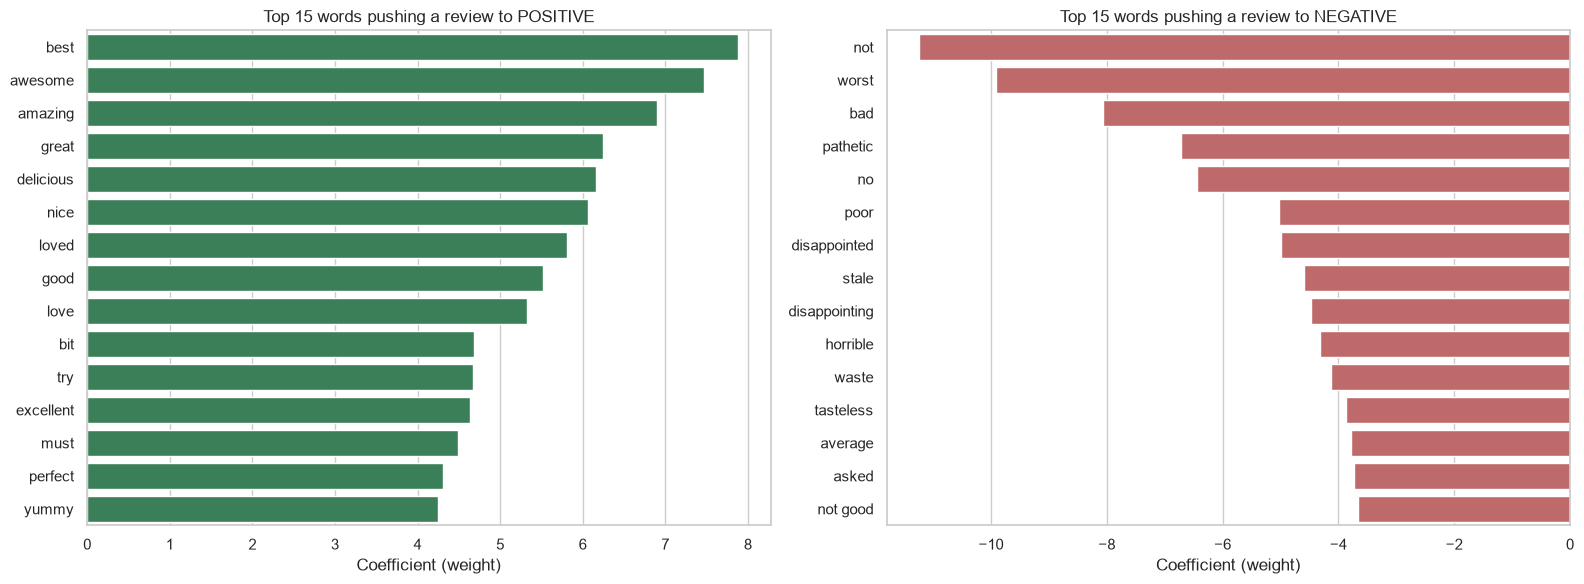

Review: good place visit promise not find better place combination best price list ambience staff
Predicted probability of being positive: 0.854
Words pushing it down: {'not': -1.146, 'better place': -0.666, 'better': -0.356, 'staff': -0.141, 'not find': -0.07}
Words pushing it up  : {'ambience': 0.367, 'good place': 0.372, 'good': 0.464, 'place': 0.657, 'best': 1.142}


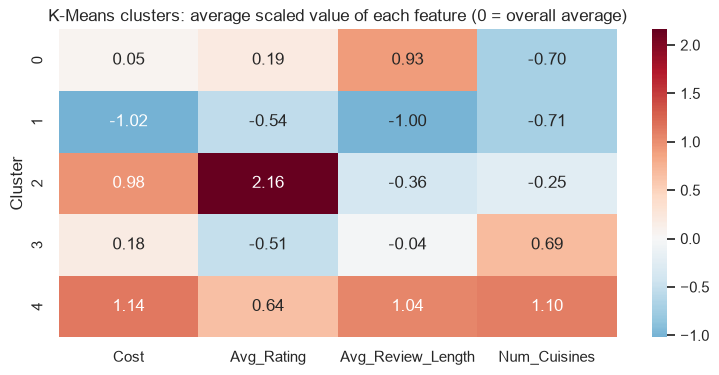

In [67]:
# Model explainability

# ---------- 1. Sentiment model: which words matter most? (Logistic Regression coefficients) ----------
coefs = pd.Series(log_reg_tuned.coef_[0], index=tfidf.get_feature_names_out())
top_pos = coefs.sort_values(ascending=False).head(15)
top_neg = coefs.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=top_pos.values, y=top_pos.index, color="seagreen", ax=axes[0])
axes[0].set_title("Top 15 words pushing a review to POSITIVE")
sns.barplot(x=top_neg.values, y=top_neg.index, color="indianred", ax=axes[1])
axes[1].set_title("Top 15 words pushing a review to NEGATIVE")
for ax in axes:
    ax.set_xlabel("Coefficient (weight)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Explain one single prediction word by word
example = X_test_text.iloc[0]
vec = tfidf.transform([example])
contributions = pd.Series(vec.toarray()[0] * log_reg_tuned.coef_[0], index=tfidf.get_feature_names_out())
contributions = contributions[contributions != 0].sort_values()
print("Review:", example)
print(f"Predicted probability of being positive: {log_reg_tuned.predict_proba(vec)[0, 1]:.3f}")
print("Words pushing it down:", contributions.head(5).round(3).to_dict())
print("Words pushing it up  :", contributions.tail(5).round(3).to_dict())

# ---------- 2. Clustering: which features drive the segments? ----------
cluster_importance = X_cluster_scaled.groupby(df_model["KMeans_Cluster"]).mean()[cluster_num_features]
plt.figure(figsize=(9, 4))
sns.heatmap(cluster_importance, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("K-Means clusters: average scaled value of each feature (0 = overall average)")
plt.ylabel("Cluster")
plt.show()

**Sentiment model: Logistic Regression**

Logistic Regression is a model that explains itself: it learns one weight (coefficient) for each word or word pair in the TF-IDF. A positive weight pushes the review towards positive, a negative weight pushes it towards negative, and the bigger the number, the stronger the push. So I used the model coefficients as my explainability tool, and I also broke down one single prediction word by word.

The most important words:
- **Positive:** best (7.9), awesome (7.5), amazing (6.9), great, delicious, nice, loved, good, love, excellent, perfect and yummy. "Must" and "try" are also there, from "must try", which is a strong recommendation.
- **Negative:** "not" is the single most important word of the whole model (-11.2), then worst (-9.9), bad (-8.1), pathetic, no, poor, disappointed, stale, horrible, waste and tasteless. "Not good" is also in the top 15 as a pair.

This confirms the choices I made in the preprocessing. Keeping "not" and "no" when I removed the stopwords was essential, since "not" ended up being the strongest negative signal. Words like "stale", "tasteless" and "waste" show that customers mostly complain about food quality and value for money, and "asked" (asking the staff for something) points to service problems. "Average" also counts as negative, so for customers an average experience is already a disappointment.

To explain one prediction, I multiplied each word's TF-IDF value by its weight. For the review "good place visit promise not find better place combination best price list ambience staff", the model predicted 85.4% positive. "Best" (+1.14), "place", "good" and "ambience" pushed it up, and "not" (-1.15) and "better place" pushed it down. This example also shows the model's main limit: "not find a better place" is actually a compliment, but the model only sees "not" as negative. It still got the right answer here, but sarcasm and double negatives are hard for a model that reads words one by one or in pairs. A more advanced model like BERT, which reads the whole sentence in context, could handle that better.

**Clustering model: K-Means**

For K-Means, I looked at the average scaled value of each feature in each cluster (0 = the overall average, positive = above average, negative = below). It shows what defines each segment:
- **Cluster 2, Top-rated stars:** Avg_Rating is at +2.16, by far the strongest value in the whole table. The rating is what defines this segment.
- **Cluster 1, Budget quick bites:** below average on everything, especially Cost (-1.02) and review length (-1.00).
- **Cluster 4, Premium multi-cuisine dining:** above average on everything: Cost (+1.14), number of cuisines (+1.10) and review length (+1.04).
- **Cluster 0, Casual hangouts:** average price but long, engaged reviews (+0.93) and few cuisines (-0.70), so specialized places that people love to talk about.
- **Cluster 3, Mid-range all-rounders:** a lot of cuisines (+0.69) but a below-average rating (-0.51). Serving a bit of everything doesn't seem to make customers happier.

So Cost and Avg_Rating are the features that separate the segments the most, then review length (customer engagement) and the number of cuisines.

**Strategies for each segment**

Now that I know who's in each segment, here's what I'd suggest Zomato does with each one:

- **Top-rated stars (7 restaurants, rating 4.69):** promote them as much as possible. Put them at the top of search results and in collections like "Top-Rated", use them in marketing campaigns, and study what they do well (the experience, the service) to share it with other restaurants. Paradise in particular should be pushed as the best value in the city.
- **Premium multi-cuisine (18 restaurants, rating 3.93):** target customers celebrating something or eating out with colleagues. Highlight them for special occasions and corporate events, and work on making their experience match their price, since some of them are rated lower than cheaper places.
- **Casual hangouts (18 restaurants, rating 3.70):** these are places people like to talk about, with the longest and most engaged reviews. Promote them for friends and weekends, push them in collections like "Live Sports Screenings" or "Best Bars & Pubs", and encourage photo reviews, since their customers are already very active.
- **Mid-range all-rounders (25 restaurants, rating 3.34):** they serve a bit of everything but don't stand out. Zomato could advise them to focus on their best dishes instead of having so many cuisines, and use the negative reviews to show them their main problems.
- **Budget quick bites (32 restaurants, rating 3.33):** the biggest segment, with the lowest ratings and a lot of the orders. This is where Zomato should put most of its quality support: faster delivery, food arriving hot, and following up on complaints. It should also highlight the few budget places rated around 4, so customers find good value easily.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [68]:
# Save the File
import joblib
from sklearn.pipeline import Pipeline

# Put the TF-IDF and the tuned model together, so the saved file takes raw cleaned text as input
sentiment_pipeline = Pipeline([("tfidf", tfidf), ("model", log_reg_tuned)])
joblib.dump(sentiment_pipeline, "zomato_sentiment_model.joblib")

# Save everything needed to place a new restaurant into a K-Means segment
joblib.dump({"scaler": scaler, "pca": pca, "kmeans": kmeans,
             "num_features": cluster_num_features, "cuisine_cols": cuisine_cols},
            "zomato_clustering_model.joblib")

print("Models saved:", "zomato_sentiment_model.joblib", "and", "zomato_clustering_model.joblib")

Models saved: zomato_sentiment_model.joblib and zomato_clustering_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [69]:
# Load the File and predict unseen data.
loaded_model = joblib.load("zomato_sentiment_model.joblib")

# The same cleaning steps as the training data, in one function
def clean_review(text):
    text = contractions.fix(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\w*\d\w*", " ", text)
    words = [slang_dict.get(w, w) for w in text.split() if w not in stop_words_nlp]
    return " ".join(lemmatizer.lemmatize(w) for w in words)

# Brand new reviews the model has never seen
new_reviews = [
    "The biryani was absolutely delicious and the staff were so friendly, will come back!",
    "Worst experience ever. Food was cold and we waited over an hour.",
    "Ambience is nice but the food was not good at all, totally overpriced.",
    "Thnx for the amazing service, must try their desserts",
]

cleaned = [clean_review(r) for r in new_reviews]
predictions = loaded_model.predict(cleaned)
probabilities = loaded_model.predict_proba(cleaned)[:, 1]

for review, pred, prob in zip(new_reviews, predictions, probabilities):
    label = "POSITIVE" if pred == 1 else "NEGATIVE"
    print(f"{label:8} ({prob:.1%} positive) | {review}")

POSITIVE (96.9% positive) | The biryani was absolutely delicious and the staff were so friendly, will come back!
NEGATIVE (0.2% positive) | Worst experience ever. Food was cold and we waited over an hour.
NEGATIVE (22.1% positive) | Ambience is nice but the food was not good at all, totally overpriced.
POSITIVE (99.9% positive) | Thnx for the amazing service, must try their desserts


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project showed me how much useful information is hidden in restaurant data and customer reviews, and how two different kinds of machine learning can turn it into something Zomato can actually use.

**What I achieved:**
- **Clustering:** K-Means split the 100 restaurants into 5 clear segments. The top-rated stars (like AB's, B-Dubs and 3B's) can be promoted more in the app. The budget quick bites and mid-range all-rounders have the lowest ratings, and since they bring a lot of the order volume, that's where Zomato should focus its quality support. Hierarchical clustering found the same overall structure, which makes me confident the segments are real.
- **Sentiment analysis:** the tuned Logistic Regression classifies reviews with 96.2% accuracy and a ROC-AUC of 0.993, and it catches 96% of the unhappy customers. It's fast and easy to explain, since I can see exactly which words drive each prediction.

**Key business insights:**
- Price and quality are linked: premium restaurants are rated significantly higher, but there are good budget options too, and they deserve to be highlighted.
- The most common cuisines (North Indian, Chinese, Biryani) aren't the best rated, while less common ones like Mediterranean and Asian do very well, which is an opportunity for new restaurants.
- Customers mainly complain about taste, service, cold food and value for money, so that's where restaurants should focus first.
- Customers who post pictures are happier, so encouraging photo reviews brings more positive content to the platform.

**What I learned:** the small decisions in preprocessing really matter. Keeping the word "not" when removing stopwords and using word pairs in the TF-IDF made "not" the strongest negative signal in the whole model. Without that, "not good" would have looked like "good". I also learned to check outliers before deleting them, since mine turned out to be the best and most premium restaurants.

**Limitations and next steps:** the model still struggles with sarcasm and double negatives like "I could not find a better place", because it reads words one by one or in pairs. A transformer model like BERT could understand the full context. The dataset is also small (100 restaurants, 100 reviews each), so with more restaurants and more recent reviews the segments would be more reliable. Finally, the saved models could be deployed as an API or a Streamlit app, so Zomato could classify new reviews and place new restaurants in a segment in real time.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***